# Análise Exploratória Completa — `listings_aggregated.csv`

**Inside Airbnb · município de São Paulo · coleta de 14–16/jun/2026**, enriquecido com agregados por distrito (IPTU, criminalidade/SSP-SP e POIs/OSM).

**Como usar**
- Ajuste a célula de **Configuração** (caminho do CSV, limiares, flags) e rode de cima para baixo. Tudo que é parâmetro está em MAIÚSCULAS.
- Funções reutilizáveis (pontos de extensão): `build_features`, `cat_summary`, `build_district_table`, `eta2`, `cell_cv_r2`, `spearman_table`, `adjusted_price_index`, `partial_spearman`, `moran_global`/`moran_local`, `haversine_km`.
- Figuras e tabelas são salvas em `eda_outputs/` (desligue com `SAVE_FIGS = False`). A tabela `resumo_distritos.csv` já sai pronta para ser usada em outros pipelines.
- **Requisitos**: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn` (seções 12.3 e 14). Coloque `listings_aggregated.csv` na mesma pasta do notebook (ou ajuste `CANDIDATES`).

**Sumário**
0. Configuração · 1. Carga e visão geral · 2. Qualidade dos dados · 3. Engenharia de atributos · 4. Preço · 5. Estrutura da oferta · 6. Hosts · 7. Disponibilidade, ocupação e receita (estimadas) · 8. Avaliações · 9. Tempo · 10. Espacial · 11. Agregados distritais (IPTU, crime, POI) · 12. O que explica o preço · 13. Amenities · 14. Baseline preditivo · **Parte II:** 15. Correlações do anúncio · 16. Segmentos (região × perfil) · 17. Preço ajustado por perfil · 18. Preço × ocupação × receita · 19. Gradiente urbano e direção · 20. Geografia e autocorrelação espacial · 21. Centralidade (PCA e correlações parciais) · 22. Tipologia de distritos · 23. Coortes de entrada · 24. Calendário como proxy de demanda · 25. Resumo

### Principais achados (desta coleta)
1. **Preços estão em R\$ e são cotações pontuais**: mediana de R\$ 331/noite; 55% das cotações são de 1 noite e 77% de check-in em até 7 dias da coleta. Comparar preços só entre cotações curtas (`price_ok`, 38 mil anúncios) — seções 4.1 a 4.4.
2. **Ocupação e receita estimadas são derivadas das avaliações**, não observadas: `ocupação = min(255, 2 × avaliações_12m × max(3, minimum_nights))` e `receita = preço × ocupação` (100% das linhas) — seções 2.2 e 7.
3. **Oferta concentrada e profissionalizada**: top 10 distritos = 67% dos anúncios; top 1% dos hosts = 29%; 86% são casas/apartamentos inteiros — seções 6 e 10.
4. **As 109 colunas distritais assumem só 96 valores** (n efetivo = 96). O crime é imputado em 25 distritos (33% dos anúncios) e os POIs do OSM têm viés central — seções 2.2 e 11.1.
5. **O que explica o preço**: o distrito explica ~14% da variância do log-preço; perfil (tipo × capacidade), 27%; região + perfil juntos chegam a R² ≈ 0,34 fora da amostra — seção 12.
6. **Centralidade confunde**: demanda e receita estimadas sobem com densidade, POI e até com crime/km² (ρ ≈ +0,55) — correlação não causal — seção 11.3.
7. **Validação aleatória superestima** (R² ≈ 0,66 contra ≈ 0,59 agrupando por host) — seção 14.
8. **O preço ajustado por perfil mostra o prêmio real**: Morumbi (+42%), Itaim Bibi (+27%) e Jardim Paulista (+20%) cobram mais que o esperado para o mesmo perfil; o ranking bruto engana por composição (São Miguel e Pedreira caem de 18º para 62º e 57º) — seção 17.
9. **A receita estimada é um ranking de avaliações**: 89% da variância do log-receita vem da ocupação estimada; preço e ocupação são independentes entre distritos (ρ = +0,09) — seção 18.
10. **A demanda cai com a distância à Sé; o preço não**: ocupação de 96 para 24 noites entre 0–2 km e 15+ km, enquanto o preço sobe do centro para a faixa de 2–8 km — seção 19.
11. **Hotspots de preço (eixo Sudoeste) e de receita (núcleo central) não coincidem** (Moran e LISA) — seção 20.
12. **Centralidade explica boa parte da demanda**: o PC1 das features distritais (62% da variância) tem ρ de 0,65 a 0,74 com demanda e 0,24 a 0,26 com preço; a correlação crime × receita cai de +0,55 para +0,16 (não significativa) ao controlar distância e POIs — seção 21.
13. **A tipologia de distritos (k = 4) explica a demanda melhor que as 5 regiões; as regiões explicam melhor o prêmio de preço** — seção 22.
14. **A nova oferta é profissional e sai do Centro**: hosts com 5+ anúncios passam de 24% (≤ 2018) a 64% (2026) das entradas; o Centro cai de ≈ 33% para 20% — seção 23.
15. **O calendário é um proxy fraco de demanda** (ρ = 0,11 por anúncio; 0,37 entre distritos) — seção 24.


## 0. Configuração

In [1]:
import json
import unicodedata
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 120, "axes.titleweight": "bold", "axes.titlesize": 11})
C = sns.color_palette("deep")

# ---------------------------------------------------------------------------
# PARÂMETROS — ajuste aqui
# ---------------------------------------------------------------------------
CANDIDATES = [Path("listings_aggregated.csv"), Path("data/listings_aggregated.csv")]   # adicione outros caminhos se precisar
DATA_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

OUT_DIR = Path("eda_outputs")
FIG_DIR, TAB_DIR = OUT_DIR / "figuras", OUT_DIR / "tabelas"
SAVE_FIGS = True             # salva PNGs em eda_outputs/figuras
RUN_BASELINE = True          # seção 14 (modelo de referência; ~2-3 min)

MAX_QUOTE_NIGHTS = 3         # preço só é comparável entre cotações de estadia curta (ver seção 4.3)
OUTLIER_K = 3.0              # cerca de Tukey no log-preço (1.5 = moderado, 3.0 = extremos)
MIN_LISTINGS_DISTRICT = 30   # distrito com menos anúncios de preço válido = "amostra baixa"
TOP_N = 15
SEED = 42

# Parte II (geografia e tipologia)
CITY_CENTER = (-23.5505, -46.6333)       # Praça da Sé (marco zero): referência para distância e direção
DIST_BINS = [0, 2, 4, 6, 8, 10, 15, np.inf]
DIST_LABELS = ["0–2", "2–4", "4–6", "6–8", "8–10", "10–15", "15+"]
K_NEIGHBORS = 6                          # vizinhos mais próximos (por centroide) na autocorrelação espacial
N_PERM = 999                             # permutações dos testes de Moran

# Agrupamento dos POIs (ponto de extensão: mova categorias entre grupos como preferir)
POI_GROUPS = {
    "atracoes": ["tourism_attraction", "tourism_museum", "tourism_gallery", "tourism_artwork", "tourism_viewpoint",
                 "tourism_theme_park", "tourism_aquarium", "tourism_information", "historic"],
    "hospedagem": ["tourism_hotel", "tourism_hostel", "tourism_guest_house", "tourism_motel", "tourism_apartment",
                   "tourism_camp_site", "tourism_camp_pitch", "tourism_wilderness_hut"],
    "comida_noite": ["amenity_restaurant", "amenity_bar", "amenity_cafe", "amenity_nightclub"],
    "cultura": ["amenity_cinema", "amenity_theatre"],
    "verde_lazer": ["leisure_park", "leisure_garden", "leisure_dog_park", "leisure_nature_reserve", "leisure_stadium"],
}


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def savefig(name: str) -> None:
    """Salva (opcional) e mostra a figura corrente."""
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def save_table(frame: pd.DataFrame, name: str) -> None:
    TAB_DIR.mkdir(parents=True, exist_ok=True)
    frame.to_csv(TAB_DIR / f"{name}.csv", encoding="utf-8-sig")


BRL = mtick.FuncFormatter(lambda x, _: "R$ " + f"{x:,.0f}".replace(",", "."))


def _brl_short(x, _=None):
    if x >= 1e6:
        return f"R$ {x / 1e6:g} mi"
    if x >= 1e3:
        return f"R$ {x / 1e3:g} mil"
    return f"R$ {x:g}"


BRL_SHORT = mtick.FuncFormatter(_brl_short)
brl = lambda x: "R$ " + f"{x:,.0f}".replace(",", ".")
pct = lambda x, d=1: f"{100 * x:.{d}f}%"
norm_txt = lambda s: unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower().strip()

SECTORS = ["N", "NE", "L", "SE", "S", "SO", "O", "NO"]


def haversine_km(lat, lon, lat0, lon0):
    """Distância (km) entre pontos e um ponto de referência."""
    la, lo, la0, lo0 = (np.radians(v) for v in (lat, lon, lat0, lon0))
    a = np.sin((la - la0) / 2) ** 2 + np.cos(la) * np.cos(la0) * np.sin((lo - lo0) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def sector(lat, lon, lat0, lon0):
    """Setor de 45° (N, NE, L, SE, S, SO, O, NO) do ponto em relação à referência."""
    la, lo, la0, lo0 = (np.radians(v) for v in (lat, lon, lat0, lon0))
    y = np.sin(lo - lo0) * np.cos(la)
    x = np.cos(la0) * np.sin(la) - np.sin(la0) * np.cos(la) * np.cos(lo - lo0)
    theta = (np.degrees(np.arctan2(y, x)) + 360) % 360
    codes = (((theta + 22.5) % 360) // 45).astype(int)
    return pd.Series(pd.Categorical.from_codes(np.asarray(codes), SECTORS), index=lat.index)


## 1. Carga e visão geral

> ⚠️ O CSV tem quebras de linha dentro de `description`, então `wc -l` **superestima** o número de registros (≈88 mil linhas de texto para ≈42 mil anúncios). Use sempre `read_csv`.

In [2]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Arquivo         : {DATA_PATH} ({DATA_PATH.stat().st_size / 1e6:,.0f} MB)")
print(f"Linhas x colunas: {df_raw.shape[0]:,} x {df_raw.shape[1]}  | memória: {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print(f"Anúncios únicos : {df_raw['id'].nunique():,} | hosts: {df_raw['host_id'].nunique():,} | "
      f"distritos: {df_raw['distrito'].nunique()} | subprefeituras: {df_raw['subprefeitura_cd'].nunique()}")
print("Datas de coleta :", df_raw["last_scraped"].value_counts().sort_index().to_dict())

Arquivo         : listings_aggregated.csv (150 MB)


Linhas x colunas: 42,354 x 188  | memória: 227 MB
Anúncios únicos : 42,354 | hosts: 15,840 | distritos: 96 | subprefeituras: 32
Datas de coleta : {'2026-06-14': 6284, '2026-06-15': 19512, '2026-06-16': 16558}


### 1.1 Mapa de colunas
O arquivo mistura **três granularidades**: o anúncio, o host (repetido em cada anúncio dele) e o **distrito** (colunas de IPTU, crime e POI, repetidas em todos os anúncios do mesmo distrito).

In [3]:
cols = list(df_raw.columns)
where = lambda pred: [c for c in cols if pred(c)]
COLUMN_GROUPS = {
    "Anúncio (id/texto)": ["id", "listing_url", "scrape_id", "last_scraped", "source", "name", "description", "picture_url"],
    "Host": where(lambda c: c.startswith(("host_", "hosts_", "calculated_host_"))),
    "Localização": ["neighbourhood_cleansed", "neighbourhood_group_cleansed", "latitude", "longitude",
                    "distrito", "regiao5", "regiao8", "subprefeitura_cd", "area_km2"],
    "Imóvel": ["property_type", "room_type", "accommodates", "bathrooms", "bathrooms_text", "bedrooms", "beds", "amenities"],
    "Preço/cotação": ["price", "price_num"] + where(lambda c: c.startswith("price_quote")),
    "Regras de estadia": where(lambda c: "nights" in c and not c.startswith("price_quote")),
    "Disponibilidade/receita": ["has_availability", "availability_30", "availability_60", "availability_90", "availability_365",
                                "availability_eoy", "calendar_last_scraped", "estimated_occupancy_l365d", "estimated_revenue_l365d"],
    "Avaliações": where(lambda c: c.startswith(("review_scores", "number_of_reviews")) or c in ("first_review", "last_review", "reviews_per_month")),
    "IPTU (distrito)": where(lambda c: c.startswith("iptu_")),
    "Crime (distrito)": where(lambda c: c.startswith("crime_")),
    "POI contagem (distrito)": where(lambda c: c.startswith("poi_")),
    "POI densidade/km² (distrito)": where(lambda c: c.startswith("poidens_")),
}
assigned = [c for v in COLUMN_GROUPS.values() for c in v]
groups_tbl = pd.DataFrame({
    "colunas": {g: len(v) for g, v in COLUMN_GROUPS.items()},
    "exemplos": {g: ", ".join(v[:3]) + (" …" if len(v) > 3 else "") for g, v in COLUMN_GROUPS.items()},
})
display(groups_tbl)
print("Colunas sem grupo:", [c for c in cols if c not in assigned], "| colunas em 2+ grupos:", [c for c, n in Counter(assigned).items() if n > 1])

,colunas,exemplos
Anúncio (id/texto),8,"id, listing_url, scrape_id …"
Host,20,"host_id, host_url, host_profile_id …"
Localização,9,"neighbourhood_cleansed, neighbourhood_group_cl..."
Imóvel,8,"property_type, room_type, accommodates …"
Preço/cotação,7,"price, price_num, price_quote_checkin_date …"
Regras de estadia,8,"minimum_nights, maximum_nights, minimum_minimu..."
Disponibilidade/receita,9,"has_availability, availability_30, availabilit..."
Avaliações,14,"number_of_reviews, number_of_reviews_ltm, numb..."
IPTU (distrito),13,"iptu_n, iptu_venal_m2_median, iptu_venal_m2_me..."
Crime (distrito),22,"crime_estupro, crime_estupro_de_vulneravel, cr..."


Colunas sem grupo: [] | colunas em 2+ grupos: []


## 2. Qualidade dos dados
### 2.1 Valores ausentes

32 de 188 colunas têm algum nulo; 13 têm mais de 10%.


,% nulos,n nulos
host_about,45.79,19395
host_location,20.79,8804
review_scores_value,13.63,5772
review_scores_location,13.63,5772
review_scores_communication,13.63,5772
review_scores_checkin,13.63,5772
review_scores_rating,13.63,5771
last_review,13.63,5771
review_scores_accuracy,13.63,5771
first_review,13.63,5771


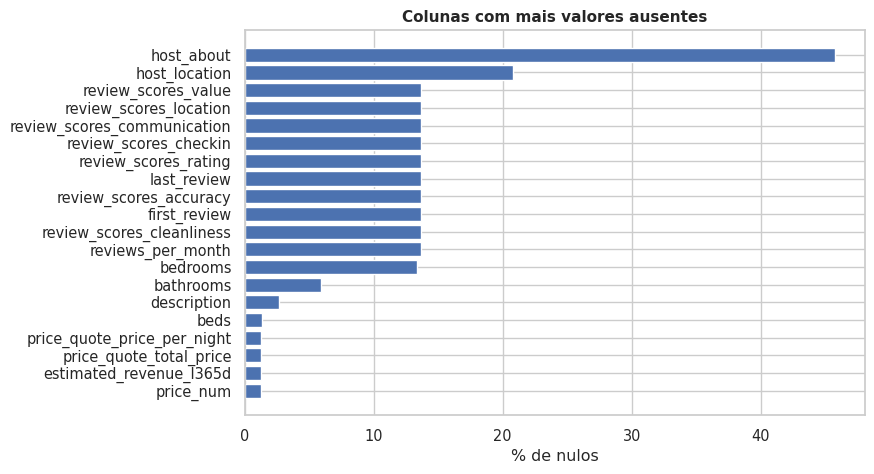

,anuncios,bedrooms,bathrooms,beds,price_num,review_scores_rating
room_type,,,,,,
Entire home/apt,36373,6.50,5.50,1.10,1.10,11.60
Hotel room,36,5.60,0.00,5.60,0.00,44.40
Private room,5655,56.40,8.10,2.60,1.90,26.00
Shared room,290,36.60,12.10,4.80,1.00,27.90


In [4]:
nulls = pd.DataFrame({"% nulos": df_raw.isna().mean() * 100, "n nulos": df_raw.isna().sum()})
nulls = nulls[nulls["n nulos"] > 0].sort_values("% nulos", ascending=False)
print(f"{len(nulls)} de {df_raw.shape[1]} colunas têm algum nulo; {int((nulls['% nulos'] > 10).sum())} têm mais de 10%.")
display(nulls.head(20))

fig, ax = plt.subplots(figsize=(8, 5))
top = nulls.head(20)[::-1]
ax.barh(top.index, top["% nulos"], color=C[0])
ax.set(xlabel="% de nulos", title="Colunas com mais valores ausentes")
savefig("02_nulos")

# Onde os nulos se concentram (por tipo de quarto)
by_room = df_raw.groupby("room_type")[["bedrooms", "bathrooms", "beds", "price_num", "review_scores_rating"]].apply(lambda g: g.isna().mean() * 100)
by_room.insert(0, "anuncios", df_raw["room_type"].value_counts())
display(by_room.round(1))

### 2.2 Verificações de consistência
Cada linha testa uma hipótese sobre o dataset. Para adicionar uma verificação, chame `check(descrição, série_booleana_ok, nota)`.

In [5]:
rows = []


def check(desc, ok, note=""):
    ok = pd.Series(ok).fillna(True).astype(bool)
    rows.append({"verificação": desc, "avaliadas": len(ok), "violações": int((~ok).sum()), "% ok": 100 * ok.mean(), "nota": note})


def within(a, b, tol=1.0):
    d = (a - b).abs()
    return d.le(tol) | d.isna()


d0 = df_raw
CRIME_AGGREGATES = {"crime_total", "crime_patrimonial", "crime_violento", "crime_total_2024", "crime_n_dp", "crime_source"}
CRIME_COMPONENTS = [c for c in cols if c.startswith("crime_") and c not in CRIME_AGGREGATES]
POI_COLS = [c for c in cols if c.startswith("poi_") and c != "poi_total"]
DIST_COLS = where(lambda c: c.startswith(("iptu_", "crime_", "poi_", "poidens_"))) + ["area_km2", "regiao5", "regiao8", "subprefeitura_cd"]

_ci, _co = pd.to_datetime(d0["price_quote_checkin_date"]), pd.to_datetime(d0["price_quote_checkout_date"])
_nights = (_co - _ci).dt.days
_fr, _lr = pd.to_datetime(d0["first_review"]), pd.to_datetime(d0["last_review"])
_occ_formula = np.minimum(255, 2 * d0["number_of_reviews_ltm"] * np.maximum(3, d0["minimum_nights"]))
_poidens_gap = pd.concat([(d0["poidens_" + c[4:]] - d0[c] / d0["area_km2"]).abs() for c in POI_COLS + ["poi_total"]], axis=1).max(axis=1)

check("id único", ~d0["id"].duplicated(keep=False))
check("neighbourhood_cleansed == distrito (sem acento/caixa)", d0["neighbourhood_cleansed"].map(norm_txt) == d0["distrito"].map(norm_txt), "chave de junção com os dados distritais")
check("price_num == price_quote_price_per_night", np.isclose(d0["price_num"], d0["price_quote_price_per_night"], equal_nan=True), "colunas redundantes")
check("price_quote_total_price ≈ preço × noites da cotação", within(d0["price_quote_total_price"], d0["price_num"] * _nights, 1))
check("estimated_revenue_l365d ≈ preço × estimated_occupancy_l365d", within(d0["estimated_revenue_l365d"], d0["price_num"] * d0["estimated_occupancy_l365d"], 1), "receita é derivada, não observada")
check("estimated_occupancy_l365d == min(255, 2 × avaliações_12m × max(3, minimum_nights))", within(d0["estimated_occupancy_l365d"], _occ_formula, 0.5), "ocupação é derivada das avaliações")
check("availability_30 ≤ 60 ≤ 90 ≤ 365", (d0["availability_30"] <= d0["availability_60"]) & (d0["availability_60"] <= d0["availability_90"]) & (d0["availability_90"] <= d0["availability_365"]))
check("number_of_reviews_ltm ≤ number_of_reviews", d0["number_of_reviews_ltm"] <= d0["number_of_reviews"])
check("first_review ≤ last_review", (_fr <= _lr) | _fr.isna())
check("minimum_nights ≤ maximum_nights", d0["minimum_nights"] <= d0["maximum_nights"])
check("review_scores_* nulos ⇔ number_of_reviews == 0", d0["review_scores_rating"].isna() == (d0["number_of_reviews"] == 0))
check("coordenadas dentro do bbox de São Paulo", d0["latitude"].between(-24.0, -23.3) & d0["longitude"].between(-46.9, -46.3))
check("crime_total == soma dos componentes crime_*", d0["crime_total"] == d0[CRIME_COMPONENTS].sum(axis=1))
check("crime_violento + crime_patrimonial == crime_total", (d0["crime_violento"] + d0["crime_patrimonial"]) == d0["crime_total"], "esperado falhar: as duas categorias não particionam o total")
check("poi_total == soma dos poi_*", d0["poi_total"] == d0[POI_COLS].sum(axis=1))
check("poidens_* == poi_* / area_km2", _poidens_gap <= 0.01, "densidades são redundantes com as contagens")

nunq = d0.groupby("distrito")[DIST_COLS].nunique(dropna=False).max()
rows.append({"verificação": f"{len(DIST_COLS)} colunas distritais são constantes dentro do distrito", "avaliadas": len(DIST_COLS),
             "violações": int((nunq > 1).sum()), "% ok": 100 * (nunq == 1).mean(), "nota": "avaliadas = colunas; n efetivo dessas features = nº de distritos"})

checks_df = pd.DataFrame(rows).set_index("verificação")
display(checks_df.round(2))

,avaliadas,violações,% ok,nota
verificação,,,,
id único,42354,0,100.00,
neighbourhood_cleansed == distrito (sem acento/caixa),42354,0,100.00,chave de junção com os dados distritais
price_num == price_quote_price_per_night,42354,1,100.00,colunas redundantes
price_quote_total_price ≈ preço × noites da cotação,42354,1,100.00,
estimated_revenue_l365d ≈ preço × estimated_occupancy_l365d,42354,0,100.00,"receita é derivada, não observada"
"estimated_occupancy_l365d == min(255, 2 × avaliações_12m × max(3, minimum_nights))",42354,0,100.00,ocupação é derivada das avaliações
availability_30 ≤ 60 ≤ 90 ≤ 365,42354,0,100.00,
number_of_reviews_ltm ≤ number_of_reviews,42354,0,100.00,
first_review ≤ last_review,42354,0,100.00,


### 2.3 Duplicidades e colunas redundantes

In [6]:
dup_keys = {
    "id": ["id"],
    "host + coordenadas": ["host_id", "latitude", "longitude"],
    "picture_url": ["picture_url"],
    "name": ["name"],
    "name + host": ["name", "host_id"],
}
print("Linhas extras (duplicatas além da primeira ocorrência):")
for label, keys in dup_keys.items():
    print(f"  {label:20s}: {int(df_raw.duplicated(keys).sum()):>6,}")

same_pin = df_raw.duplicated(["host_id", "latitude", "longitude"], keep=False)
print(f"\nAnúncios do mesmo host na mesma coordenada: {same_pin.sum():,} ({pct(same_pin.mean())}) — em geral várias unidades do mesmo host no mesmo prédio (maioria `Entire rental unit`) ou anúncios duplicados.")
display(df_raw.loc[same_pin, "property_type"].value_counts().head(6).to_frame("anuncios"))

const_cols = [c for c in cols if df_raw[c].nunique(dropna=False) <= 1]
print("\nColunas constantes:", const_cols)
print("Colunas redundantes: price_num/price_quote_price_per_night; neighbourhood_cleansed/distrito; poidens_* (= poi_*/área); "
      "crime_total_2024 (corr. com crime_total entre distritos:",
      round(df_raw[["distrito", "crime_total", "crime_total_2024"]].drop_duplicates("distrito")[["crime_total", "crime_total_2024"]].corr().iloc[0, 1], 3), ")")

Linhas extras (duplicatas além da primeira ocorrência):
  id                  :      0
  host + coordenadas  :  4,399
  picture_url         :    936
  name                :  1,677
  name + host         :  1,279

Anúncios do mesmo host na mesma coordenada: 6,084 (14.4%) — em geral várias unidades do mesmo host no mesmo prédio (maioria `Entire rental unit`) ou anúncios duplicados.


,anuncios
property_type,
Entire rental unit,4933
Entire condo,207
Private room in home,181
Entire serviced apartment,150
Room in aparthotel,140
Room in hotel,132



Colunas constantes: ['scrape_id', 'source']
Colunas redundantes: price_num/price_quote_price_per_night; neighbourhood_cleansed/distrito; poidens_* (= poi_*/área); crime_total_2024 (corr. com crime_total entre distritos: 0.989 )


**Leitura**
- As verificações de consistência passam em ~100% das linhas. Exceções: 11 anúncios com `minimum_nights > maximum_nights` e `crime_violento + crime_patrimonial ≠ crime_total` (esperado: as duas categorias não cobrem todo o total).
- A junção com os dados distritais é limpa: `neighbourhood_cleansed` = `distrito` em 100% das linhas (96 distritos) e as 109 colunas distritais são constantes dentro de cada distrito.
- Os nulos de `review_scores_*`, `first_review`, `last_review` e `reviews_per_month` (13,6%) são exatamente os anúncios **sem nenhuma avaliação**. Já `bedrooms` está vazio em 56% dos *Private room* e 37% dos *Shared room*.
- 14,4% dos anúncios dividem host **e** coordenada com outro anúncio (quase todos `Entire rental unit`): em geral são várias unidades do mesmo prédio. Vale ter isso em mente antes de contar "imóveis".

## 3. Engenharia de atributos
Tudo que é derivado fica em **uma função** (`build_features`) para ser reaproveitada em outros notebooks/pipelines. Nada é descartado do arquivo original.

In [7]:
BOOL_COLS = ["host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]
DATE_COLS = ["last_scraped", "calendar_last_scraped", "first_review", "last_review", "price_quote_checkin_date", "price_quote_checkout_date"]


def parse_amenities(s):
    try:
        return json.loads(s)
    except (TypeError, ValueError):
        return []


def build_features(raw: pd.DataFrame) -> pd.DataFrame:
    d = raw.drop(columns=["price"])      # texto "$540.43" → substituído por `price` numérico (= price_num) abaixo
    for c in BOOL_COLS:
        d[c] = d[c].map({"t": True, "f": False}).astype("boolean")
    for c in DATE_COLS:
        d[c] = pd.to_datetime(d[c], errors="coerce")

    f = {}
    # --- preço e cotação -----------------------------------------------------
    f["price"] = d["price_num"]                                   # R$/noite (ver seção 4.1 sobre a moeda)
    f["log_price"] = np.log(d["price_num"])
    f["quote_nights"] = (d["price_quote_checkout_date"] - d["price_quote_checkin_date"]).dt.days
    f["quote_nights_bucket"] = pd.cut(f["quote_nights"], [0, 1, 2, 3, 6, 13, 29, np.inf], labels=["1", "2", "3", "4–6", "7–13", "14–29", "30+"])
    f["quote_lead_days"] = (d["price_quote_checkin_date"] - d["last_scraped"]).dt.days
    f["quote_dow"] = d["price_quote_checkin_date"].dt.dayofweek   # 0 = segunda
    f["price_pp"] = d["price_num"] / d["accommodates"]
    # --- imóvel -------------------------------------------------------------
    f["bath_shared"] = d["bathrooms_text"].str.contains("shared", case=False, na=False)
    f["bath_private"] = d["bathrooms_text"].str.contains("private", case=False, na=False)
    f["n_amenities"] = d["amenities"].map(parse_amenities).map(len)
    f["min_nights_bucket"] = pd.cut(d["minimum_nights"], [0, 1, 2, 3, 6, 27, np.inf], labels=["1", "2", "3", "4–6", "7–27", "28+"])
    f["acc_b"] = pd.cut(d["accommodates"], [0, 1, 2, 3, 4, 6, np.inf], labels=["1", "2", "3", "4", "5–6", "7+"]).astype(str)
    f["bed_b"] = d["bedrooms"].clip(upper=4).map(lambda v: "s/ info" if pd.isna(v) else str(int(v))).astype(str)
    # --- geografia (distância e direção em relação a CITY_CENTER) -------------
    f["dist_centro_km"] = haversine_km(d["latitude"], d["longitude"], *CITY_CENTER)
    f["dist_bucket"] = pd.cut(f["dist_centro_km"], DIST_BINS, labels=DIST_LABELS)
    f["setor"] = sector(d["latitude"], d["longitude"], *CITY_CENTER)
    # --- host ---------------------------------------------------------------
    f["host_tenure_years"] = d["hosts_time_as_host_years"] + d["hosts_time_as_host_months"] / 12
    f["host_in_sp"] = d["host_location"].fillna("").map(norm_txt).str.contains("sao paulo").where(d["host_location"].notna()).astype("boolean")
    f["host_size"] = pd.cut(d["calculated_host_listings_count"], [0, 1, 4, 19, np.inf], labels=["1", "2–4", "5–19", "20+"])
    # --- avaliações / atividade --------------------------------------------
    f["has_reviews"] = d["number_of_reviews"] > 0
    f["active_ltm"] = d["number_of_reviews_ltm"] > 0
    f["days_since_last_review"] = (d["last_scraped"] - d["last_review"]).dt.days
    f["years_since_first_review"] = (d["last_scraped"] - d["first_review"]).dt.days / 365.25
    # --- distritais derivadas (densidades por km²) --------------------------
    for k in ("total", "violento", "patrimonial"):
        f[f"crime_{k}_km2"] = d[f"crime_{k}"] / d["area_km2"]
    for g, names in POI_GROUPS.items():
        f[f"poidens_{g}"] = d[[f"poidens_{n}" for n in names if f"poidens_{n}" in d]].sum(axis=1)
    return pd.concat([d, pd.DataFrame(f, index=d.index)], axis=1).copy()   # .copy() consolida os blocos (evita fragmentação)


df = build_features(df_raw)
DIST_LABEL = df.drop_duplicates("distrito").set_index("distrito")["neighbourhood_cleansed"]     # nome com acento, para rótulos
lab = lambda d: DIST_LABEL.get(d, str(d).title())
new_cols = [c for c in df.columns if c not in df_raw.columns]
print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas ({len(new_cols)} novas):")
print(", ".join(new_cols))

42,354 linhas x 218 colunas (30 novas):
log_price, quote_nights, quote_nights_bucket, quote_lead_days, quote_dow, price_pp, bath_shared, bath_private, n_amenities, min_nights_bucket, acc_b, bed_b, dist_centro_km, dist_bucket, setor, host_tenure_years, host_in_sp, host_size, has_reviews, active_ltm, days_since_last_review, years_since_first_review, crime_total_km2, crime_violento_km2, crime_patrimonial_km2, poidens_atracoes, poidens_hospedagem, poidens_comida_noite, poidens_cultura, poidens_verde_lazer


## 4. Preço
### 4.1 Moeda
O JSON da cotação (`price_quote_raw`) marca `currency = "USD"`, mas os *line items* trazem `R$`. Conferindo:

In [8]:
raw_q = df.loc[df["price"].notna(), "price_quote_raw"].dropna()      # cotações que retornaram preço
tags = raw_q.map(lambda s: json.loads(s)["quote"].get("currency")).value_counts().to_dict()
print("Tag de moeda no JSON      :", tags)
print("Cotações com 'R$' nos line items:", pct(raw_q.str.contains(r"R\$", regex=True).mean()))
print("Exemplo de line item      :", json.loads(raw_q.iloc[0])["quote"]["raw_price_line_items"][0]["description"])
print("→ Os valores estão em reais (R$/noite); a tag USD é um artefato da coleta.")

Tag de moeda no JSON      : {'USD': 41831}
Cotações com 'R$' nos line items: 100.0%
Exemplo de line item      : 14 nights x R$540.37
→ Os valores estão em reais (R$/noite); a tag USD é um artefato da coleta.


### 4.2 Distribuição

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
R$/noite,"41,832.00",418.00,818.00,12.00,77.00,124.00,250.00,331.00,430.00,833.00,"1,910.00","9,360.00","57,127.00"


Assimetria: 35.5 (preço) → 0.68 (log-preço) | média/mediana = 1.26


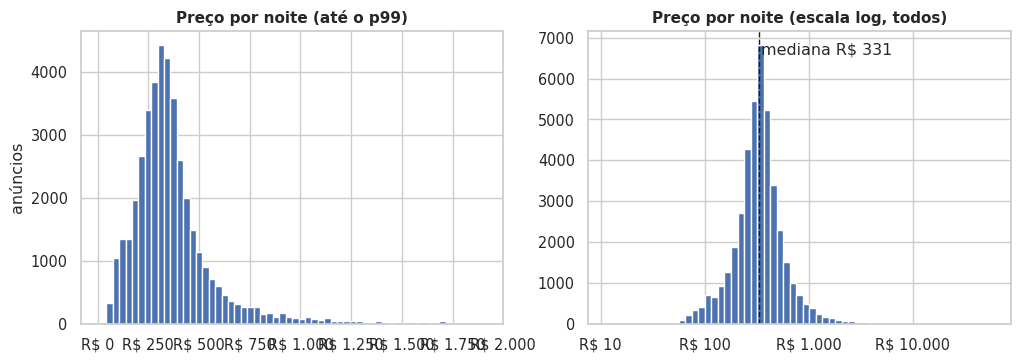

In [9]:
p = df["price"].dropna()
display(p.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).round(0).to_frame("R$/noite").T)
print(f"Assimetria: {stats.skew(p):.1f} (preço) → {stats.skew(np.log(p)):.2f} (log-preço) | média/mediana = {p.mean() / p.median():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(p[p <= p.quantile(.99)], bins=60, color=C[0])
ax[0].xaxis.set_major_formatter(BRL)
ax[0].set(title="Preço por noite (até o p99)", ylabel="anúncios")
ax[1].hist(p, bins=np.logspace(np.log10(p.min()), np.log10(p.max()), 60), color=C[0])
ax[1].set_xscale("log")
ax[1].axvline(p.median(), color="k", ls="--", lw=1)
ax[1].text(p.median() * 1.05, ax[1].get_ylim()[1] * .92, f"mediana {brl(p.median())}")
ax[1].xaxis.set_major_formatter(BRL)
ax[1].set(title="Preço por noite (escala log, todos)")
savefig("04_preco_distribuicao")

### 4.3 O preço é comparável entre anúncios?
Cada preço é uma **cotação** para uma data de check-in e uma duração de estadia específicas. Se essas variáveis diferirem muito entre anúncios, comparar preços direto mistura efeitos de calendário e de desconto por estadia longa.

quote_nights_bucket,1,2,3,4–6,7–13,14–29,30+
cotacoes,"23,240.00","12,893.00","2,687.00","1,437.00",702.00,625.00,737.00
preco_mediano,351.00,305.50,306.00,278.40,258.00,220.60,140.60
%,54.90,30.50,6.30,3.40,1.70,1.50,1.70


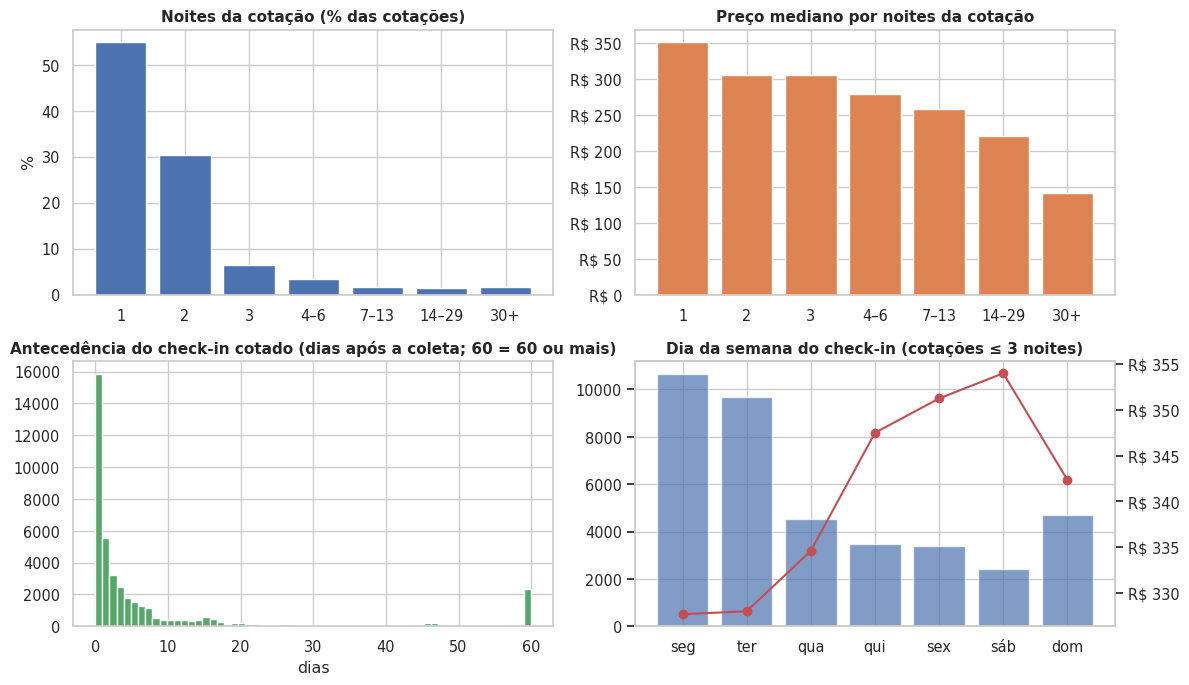

Cotações de 1 noite: 54.9% | noites da cotação == minimum_nights: 92.7%
Preço mediano: R$ 351 (1 noite) vs R$ 141 (30+ noites)
Antecedência: mediana 1 dia(s) | 77.4% das cotações são para check-in em até 7 dias da coleta
Check-in seg+ter: 52.4% das cotações curtas vs sáb: 6.2%


In [10]:
qn = df.groupby("quote_nights_bucket", observed=True).agg(cotacoes=("id", "size"), preco_mediano=("price", "median"))
qn["%"] = qn["cotacoes"] / qn["cotacoes"].sum() * 100
display(qn.round(1).T)

dow_lbl = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
short = df[df["quote_nights"] <= MAX_QUOTE_NIGHTS]
dow = short.groupby("quote_dow").agg(cotacoes=("id", "size"), preco_mediano=("price", "median"))
dow.index = dow.index.astype(int)      # quote_dow vem como float por causa dos nulos

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].bar(qn.index.astype(str), qn["%"], color=C[0]); ax[0, 0].set(title="Noites da cotação (% das cotações)", ylabel="%")
ax[0, 1].bar(qn.index.astype(str), qn["preco_mediano"], color=C[1]); ax[0, 1].yaxis.set_major_formatter(BRL)
ax[0, 1].set(title="Preço mediano por noites da cotação")
ax[1, 0].hist(df["quote_lead_days"].clip(0, 60).dropna(), bins=61, color=C[2]); ax[1, 0].set(title="Antecedência do check-in cotado (dias após a coleta; 60 = 60 ou mais)", xlabel="dias")
ax[1, 1].bar([dow_lbl[i] for i in dow.index], dow["cotacoes"], color=C[0], alpha=.7)
ax2 = ax[1, 1].twinx(); ax2.plot([dow_lbl[i] for i in dow.index], dow["preco_mediano"], "o-", color=C[3]); ax2.yaxis.set_major_formatter(BRL); ax2.grid(False)
ax[1, 1].set(title=f"Dia da semana do check-in (cotações ≤ {MAX_QUOTE_NIGHTS} noites)")
fig.tight_layout()
savefig("04_preco_comparabilidade")

print(f"Cotações de 1 noite: {pct((df['quote_nights'] == 1).mean())} | noites da cotação == minimum_nights: {pct((df['quote_nights'] == df['minimum_nights']).mean())}")
print(f"Preço mediano: {brl(qn['preco_mediano'].iloc[0])} (1 noite) vs {brl(qn['preco_mediano'].iloc[-1])} (30+ noites)")
print(f"Antecedência: mediana {df['quote_lead_days'].median():.0f} dia(s) | {pct((df['quote_lead_days'] <= 7).mean())} das cotações são para check-in em até 7 dias da coleta")
print(f"Check-in seg+ter: {pct(dow['cotacoes'].loc[[0, 1]].sum() / dow['cotacoes'].sum())} das cotações curtas vs sáb: {pct(dow['cotacoes'].loc[5] / dow['cotacoes'].sum())}")

**Leitura**
- O preço é uma **cotação pontual**: 55% das cotações são de 1 noite, 93% usam exatamente o `minimum_nights` do anúncio e 77% são para check-in em até 7 dias da coleta (mediana: 1 dia).
- O preço por noite cai com a duração da estadia (mediana R\$ 351 com 1 noite → R\$ 141 com 30+ noites). Misturar durações confunde desconto de estadia longa com diferença de mercado.
- 52% dos check-ins cotados caem na segunda ou na terça e só 6% no sábado. Hipótese: fins de semana tendem a estar reservados, então a "próxima data livre" cai em dias úteis; o preço mediano sobe cerca de 8% de segunda para sábado.
- Decisão adotada: comparar preços apenas entre cotações de até `MAX_QUOTE_NIGHTS` noites (`price_ok`).

### 4.4 Outliers e subconjunto de preço comparável
`price_ok` = tem preço **e** cotação de até `MAX_QUOTE_NIGHTS` noites **e** não é outlier extremo (cerca de Tukey no log-preço, `OUTLIER_K`). As seções de preço usam `dfp`; as de demanda/receita usam `dfa` (ativos nos últimos 12 meses + preço comparável).

In [11]:
short_prices = df["price"].where(df["quote_nights"] <= MAX_QUOTE_NIGHTS).dropna()
lq1, lq3 = np.log(short_prices).quantile([.25, .75])
iqr = lq3 - lq1
lo, hi = np.exp(lq1 - OUTLIER_K * iqr), np.exp(lq3 + OUTLIER_K * iqr)
df["price_outlier"] = (df["price"] < lo) | (df["price"] > hi)
df["price_ok"] = df["price"].notna() & (df["quote_nights"] <= MAX_QUOTE_NIGHTS) & ~df["price_outlier"]
dfp = df[df["price_ok"]].copy()
dfa = df[df["active_ltm"] & df["price_ok"]].copy()

n_priced = int(df["price"].notna().sum())
print(f"Cercas (k={OUTLIER_K}): {brl(lo)} a {brl(hi)}")
print(f"Abaixo: {int((df['price'] < lo).sum())} | acima: {int((df['price'] > hi).sum())} | acima de R$ 5.000: {int((df['price'] > 5000).sum())}")
hi_out = df[df["price"] > hi]
print(f"Entre os outliers altos, {pct((~hi_out['active_ltm']).mean())} não tiveram nenhuma avaliação nos últimos 12 meses (preços possivelmente 'de bloqueio').")
print(f"\nCom preço: {n_priced:,} ({pct(n_priced / len(df))}) → price_ok: {len(dfp):,} ({pct(len(dfp) / len(df))} do total) | dfa (ativos): {len(dfa):,}")
display(df.nlargest(8, "price")[["price", "quote_nights", "accommodates", "bedrooms", "room_type", "distrito", "number_of_reviews_ltm"]])

Cercas (k=3.0): R$ 56 a R$ 1.979
Abaixo: 71 | acima: 400 | acima de R$ 5.000: 112
Entre os outliers altos, 68.2% não tiveram nenhuma avaliação nos últimos 12 meses (preços possivelmente 'de bloqueio').

Com preço: 41,832 (98.8%) → price_ok: 38,033 (89.8% do total) | dfa (ativos): 31,469


,price,quote_nights,accommodates,bedrooms,room_type,distrito,number_of_reviews_ltm
23588,"57,127.00",1.00,3,1.00,Entire home/apt,MOEMA,1
15720,"57,059.00",1.00,4,1.00,Entire home/apt,REPUBLICA,0
4057,"53,030.00",1.00,2,1.00,Private room,REPUBLICA,0
3319,"39,864.33",3.00,6,3.00,Entire home/apt,MORUMBI,0
34481,"34,236.00",1.00,1,4.00,Entire home/apt,VILA ANDRADE,0
6007,"29,505.50",2.00,2,1.00,Entire home/apt,ITAIM BIBI,0
911,"28,600.75",8.00,1,NaN,Private room,MORUMBI,0
40005,"27,388.25",1.00,8,4.00,Entire home/apt,MORUMBI,0


**Leitura**
- Mediana de R\$ 331/noite, mas com cauda extrema (p99 ≈ R\$ 1.910; máximo R\$ 57.127): assimetria 35 no preço contra 0,7 no log. Trabalhe em **log-preço**.
- Cercas de Tukey no log (k = 3): R\$ 56 a R\$ 1.979, o que marca 471 anúncios (71 baixos e 400 altos). 68% dos outliers altos não tiveram avaliação em 12 meses — provável preço de bloqueio/placeholder.
- `price_ok` = 38.033 anúncios (89,8%); `dfa` (ativos com preço comparável) = 31.469.

## 5. Estrutura da oferta
`cat_summary(by)` devolve volume, atividade, preço (em `dfp`), ocupação e receita estimadas (em `dfa`) por qualquer coluna categórica — é a função mais reaproveitada daqui em diante.

,anuncios,%,ativos_12m_%,rating_medio,preco_p25,preco_mediano,preco_p75,ocup_est_mediana,receita_est_mediana
room_type,,,,,,,,,
Entire home/apt,36373,85.90,82.90,4.80,280.00,346.00,438.00,72.00,"25,293.00"
Private room,5655,13.40,58.50,4.80,132.00,194.00,302.00,48.00,"8,940.00"
Shared room,290,0.70,59.30,4.80,80.60,106.00,172.50,18.00,"2,422.00"
Hotel room,36,0.10,41.70,4.60,275.00,371.00,554.20,45.00,"6,606.00"


69 tipos de propriedade; os 5 maiores concentram 89.0% dos anúncios.


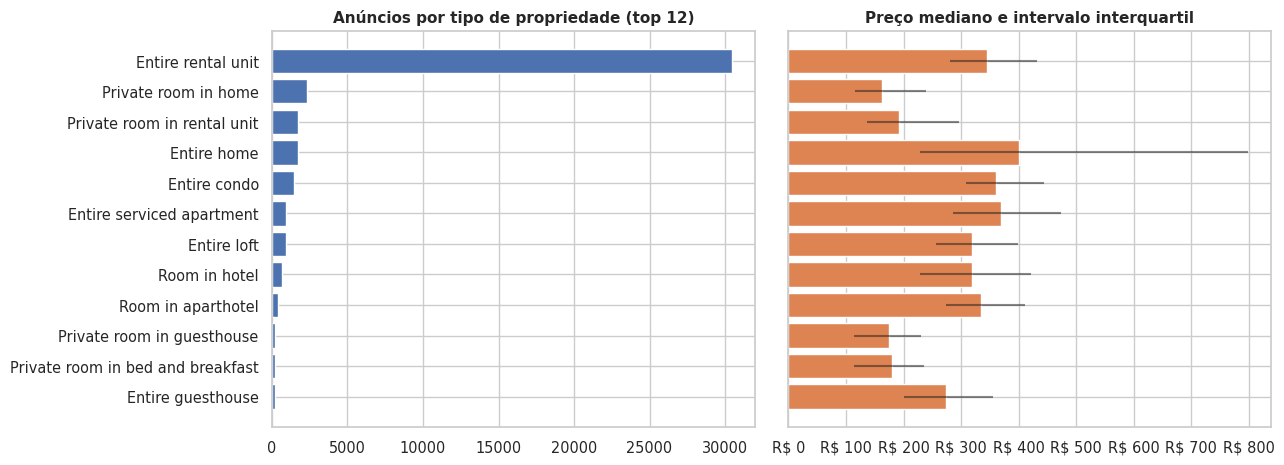

In [12]:
def cat_summary(by) -> pd.DataFrame:
    """Resumo por categoria: volume, atividade, preço (price_ok), ocupação e receita estimadas (ativos)."""
    g = df.groupby(by, observed=True)
    out = pd.DataFrame({"anuncios": g.size(), "%": g.size() / len(df) * 100,
                        "ativos_12m_%": g["active_ltm"].mean() * 100, "rating_medio": g["review_scores_rating"].mean()})
    gp = dfp.groupby(by, observed=True)["price"]
    out["preco_p25"], out["preco_mediano"], out["preco_p75"] = gp.quantile(.25), gp.median(), gp.quantile(.75)
    ga = dfa.groupby(by, observed=True)
    out["ocup_est_mediana"] = ga["estimated_occupancy_l365d"].median()
    out["receita_est_mediana"] = ga["estimated_revenue_l365d"].median()
    return out.sort_values("anuncios", ascending=False)


rt = cat_summary("room_type")
display(rt.round(1))
save_table(rt, "por_room_type")

pt = cat_summary("property_type")
print(f"{df['property_type'].nunique()} tipos de propriedade; os 5 maiores concentram {pct(pt['%'].head(5).sum() / 100)} dos anúncios.")
top_pt = pt.head(12)
order = top_pt.index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
ax[0].barh(order, top_pt.loc[order, "anuncios"], color=C[0]); ax[0].set(title="Anúncios por tipo de propriedade (top 12)")
med = top_pt.loc[order, "preco_mediano"]
ax[1].barh(order, med, xerr=[med - top_pt.loc[order, "preco_p25"], top_pt.loc[order, "preco_p75"] - med], color=C[1], error_kw={"alpha": .5})
ax[1].xaxis.set_major_formatter(BRL); ax[1].set(title="Preço mediano e intervalo interquartil")
fig.tight_layout()
savefig("05_property_type")

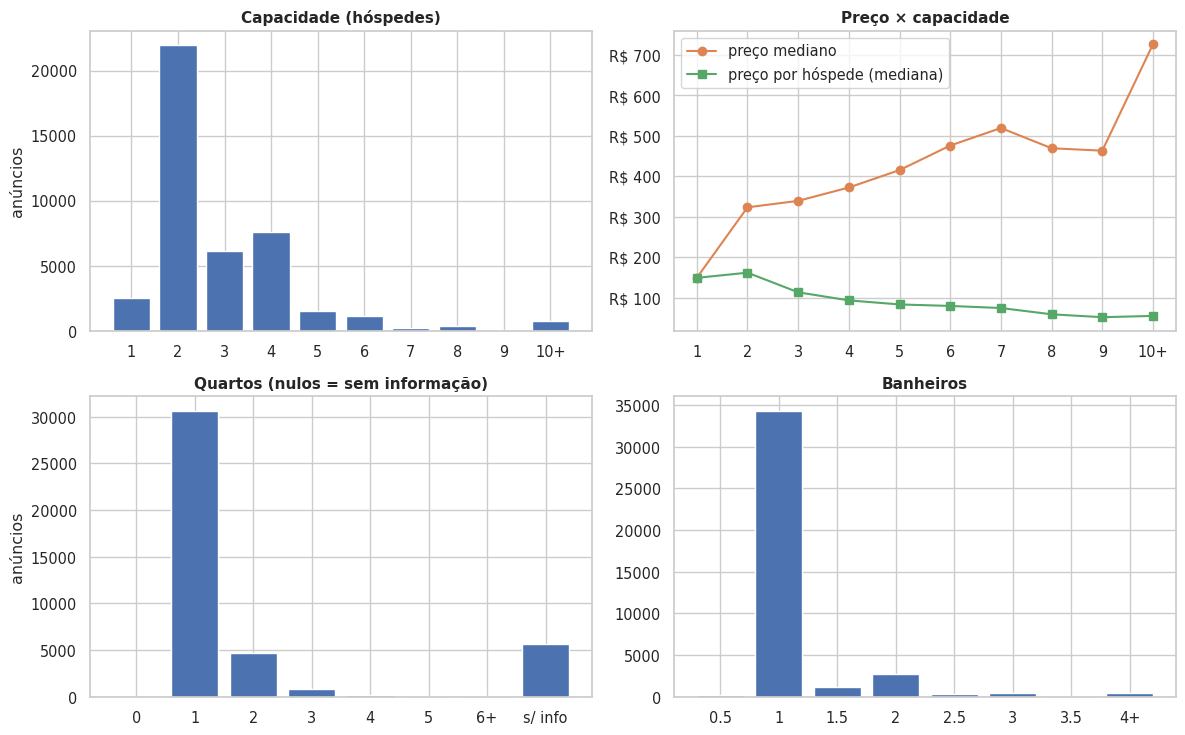

Entire home/apt: 85.9% | capacidade mediana: 2 | mediana de quartos: 1 (nulos: 13.4%, 56.3% deles são Private room)
Banheiro compartilhado: 5.8% | amenities por anúncio: mediana 30 (p10 9, p90 46)


In [13]:
acc = df["accommodates"].clip(upper=10)
acc_p = dfp.assign(acc=dfp["accommodates"].clip(upper=10)).groupby("acc")
acc_lbl = [str(i) for i in range(1, 10)] + ["10+"]
bed = df["bedrooms"].clip(upper=6).value_counts(dropna=False).sort_index(na_position="last")
bed_lbl = [("s/ info" if pd.isna(i) else ("6+" if i == 6 else str(int(i)))) for i in bed.index]
bath = df["bathrooms"].clip(upper=4).value_counts().sort_index()

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
ax[0, 0].bar(acc_lbl, acc.value_counts().sort_index().values, color=C[0]); ax[0, 0].set(title="Capacidade (hóspedes)", ylabel="anúncios")
ax[0, 1].plot(acc_lbl, acc_p["price"].median().values, "o-", label="preço mediano", color=C[1])
ax[0, 1].plot(acc_lbl, acc_p["price_pp"].median().values, "s-", label="preço por hóspede (mediana)", color=C[2])
ax[0, 1].yaxis.set_major_formatter(BRL); ax[0, 1].legend(); ax[0, 1].set(title="Preço × capacidade")
ax[1, 0].bar(bed_lbl, bed.values, color=C[0]); ax[1, 0].set(title="Quartos (nulos = sem informação)", ylabel="anúncios")
ax[1, 1].bar([("4+" if i == 4 else f"{i:g}") for i in bath.index], bath.values, color=C[0]); ax[1, 1].set(title="Banheiros")
fig.tight_layout()
savefig("05_capacidade_quartos")

print(f"Entire home/apt: {pct((df['room_type'] == 'Entire home/apt').mean())} | capacidade mediana: {df['accommodates'].median():.0f} | mediana de quartos: {df['bedrooms'].median():.0f} (nulos: {pct(df['bedrooms'].isna().mean())}, "
      f"{pct(df.loc[df['bedrooms'].isna(), 'room_type'].eq('Private room').mean())} deles são Private room)")
print(f"Banheiro compartilhado: {pct(df['bath_shared'].mean())} | amenities por anúncio: mediana {df['n_amenities'].median():.0f} (p10 {df['n_amenities'].quantile(.1):.0f}, p90 {df['n_amenities'].quantile(.9):.0f})")

**Leitura**
- A oferta é dominada por apartamentos inteiros: 86% são *Entire home/apt* (72% só em `Entire rental unit`); 5 dos 69 tipos de propriedade concentram 89% dos anúncios.
- Preço mediano por tipo de quarto: R\$ 346 (*Entire home/apt*), R\$ 194 (*Private room*) e R\$ 106 (*Shared room*).
- O preço sobe com a capacidade, mas o **preço por hóspede cai** a partir de 2 hóspedes (economia de escala). A capacidade mediana é de 2 hóspedes e 1 quarto.

## 6. Hosts
`host_*` se repete em todos os anúncios do host: para falar de **hosts** (e não de anúncios), deduplique por `host_id`.

Hosts: 15,840 | com 1 único anúncio: 72.3% | anúncios por host: média 2.7, máx 496
Top 1% dos hosts (159) detêm 29.4% dos anúncios; top 5%: 49.1%; top 10%: 58.0% | Gini = 0.58
Anúncios de hosts com 5+ anúncios: 54.1% | com 20+: 35.2%
Superhost: 48.7% dos anúncios | identidade verificada: 97.1% | host em SP: 85.1% (localização nula em 20.8%)
host_listings_count > calculated_host_listings_count em 53.4% dos anúncios (a primeira conta o host em todo o Airbnb; a segunda, só nesta coleta)


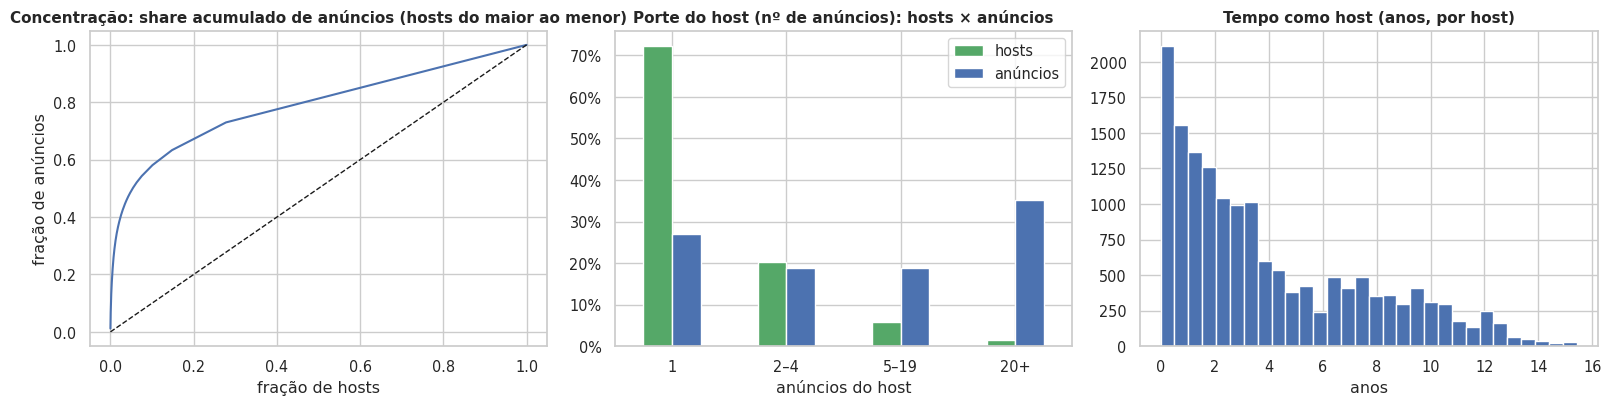

,anuncios,%,ativos_12m_%,rating_medio,preco_p25,preco_mediano,preco_p75,ocup_est_mediana,receita_est_mediana
host_size,,,,,,,,,
20+,14899,35.20,86.90,4.70,290.50,347.00,419.30,66.00,"23,475.00"
1,11459,27.10,69.60,4.90,245.50,325.50,440.40,72.00,"24,715.50"
5–19,8004,18.90,80.40,4.80,236.50,325.20,436.00,66.00,"20,328.00"
2–4,7992,18.90,78.70,4.90,226.00,314.00,421.60,72.00,"22,444.00"


,anuncios,%,ativos_12m_%,rating_medio,preco_p25,preco_mediano,preco_p75,ocup_est_mediana,receita_est_mediana
host_is_superhost,,,,,,,,,
False,21714,51.30,66.60,4.70,252.50,336.00,431.00,42.00,"13,277.50"
True,20640,48.70,92.90,4.90,263.00,334.00,423.00,102.00,"32,724.00"


In [14]:
hs = df.groupby("host_id").size().sort_values(ascending=False)
n_h = len(hs)
cum = hs.cumsum() / hs.sum()
share_top = {q: cum.iloc[int(np.ceil(q * n_h)) - 1] for q in (.01, .05, .10)}
x = np.sort(hs.values)
gini = 2 * np.sum(np.arange(1, n_h + 1) * x) / (n_h * x.sum()) - (n_h + 1) / n_h

print(f"Hosts: {n_h:,} | com 1 único anúncio: {pct((hs == 1).mean())} | anúncios por host: média {hs.mean():.1f}, máx {hs.max()}")
print(f"Top 1% dos hosts ({int(np.ceil(.01 * n_h))}) detêm {pct(share_top[.01])} dos anúncios; top 5%: {pct(share_top[.05])}; top 10%: {pct(share_top[.10])} | Gini = {gini:.2f}")
print(f"Anúncios de hosts com 5+ anúncios: {pct((df['calculated_host_listings_count'] >= 5).mean())} | com 20+: {pct((df['calculated_host_listings_count'] >= 20).mean())}")
print(f"Superhost: {pct(df['host_is_superhost'].mean())} dos anúncios | identidade verificada: {pct(df['host_identity_verified'].mean())} | host em SP: {pct(df['host_in_sp'].mean())} (localização nula em {pct(df['host_in_sp'].isna().mean())})")
print(f"host_listings_count > calculated_host_listings_count em {pct((df['host_listings_count'] > df['calculated_host_listings_count']).mean())} dos anúncios (a primeira conta o host em todo o Airbnb; a segunda, só nesta coleta)")

host_lvl = df.drop_duplicates("host_id")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(np.arange(1, n_h + 1) / n_h, cum.values, color=C[0]); ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="Concentração: share acumulado de anúncios (hosts do maior ao menor)", xlabel="fração de hosts", ylabel="fração de anúncios")
sz = pd.DataFrame({"hosts": host_lvl["host_size"].value_counts(normalize=True), "anúncios": df["host_size"].value_counts(normalize=True)}).loc[["1", "2–4", "5–19", "20+"]]
sz.plot.bar(ax=ax[1], color=[C[2], C[0]], rot=0); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax[1].set(title="Porte do host (nº de anúncios): hosts × anúncios", xlabel="anúncios do host")
ax[2].hist(host_lvl["host_tenure_years"], bins=30, color=C[0]); ax[2].set(title="Tempo como host (anos, por host)", xlabel="anos")
fig.tight_layout()
savefig("06_hosts")

hz = cat_summary("host_size")
sh = cat_summary("host_is_superhost")
display(hz.round(1)); display(sh.round(1))

**Leitura**
- Mercado **profissionalizado**: 72% dos hosts têm um único anúncio, mas o top 1% dos hosts (159) controla 29% dos anúncios e o top 10%, 58% (Gini 0,58). 35% dos anúncios são de hosts com 20+ anúncios.
- Superhost não é um selo raro aqui (49% dos anúncios). Superhosts são bem mais ativos (93% × 67% com avaliação em 12 meses) e têm ocupação estimada mediana 2,4× maior (102 × 42 noites), mas o **preço mediano é praticamente igual** (R\$ 334 × R\$ 336).
- Hosts grandes (20+) são mais ativos (87% × 70% dos hosts de 1 anúncio), com preço mediano parecido (R\$ 347 × R\$ 326) e nota média menor (4,66 × 4,87).

## 7. Disponibilidade, ocupação e receita (estimadas)
**Atenção:** `estimated_occupancy_l365d` e `estimated_revenue_l365d` **não são observadas**. As verificações da seção 2.2 mostram que, em 100% das linhas,

`ocupação = min(255, 2 × avaliações_12m × max(3, minimum_nights))` e `receita = preço_cotado × ocupação`

ou seja, ocupação e receita são funções das **avaliações dos últimos 12 meses** (e do mínimo de noites), e a receita herda o preço de uma cotação pontual. Abaixo, o que isso implica.

Ocupação estimada: 20.6% zero (= sem avaliações em 12m) | 8.0% no teto (255 noites) | mediana entre ativos: 72 noites
Anúncios ativos (≥1 avaliação em 12m): 79.4% | disponibilidade_365 mediana: 314 dias | has_availability=f: 0.4%
Receita estimada (ativos, mediana): R$ 22.968 | top 1% dos anúncios = 9.3% da receita total estimada; top 10% = 39.9%
Spearman(ocupação est., avaliações 12m) = 0.989


min_nights_bucket,1,2,3,4–6,7–27,28+
avaliacoes_12m_mediana,12.00,11.00,8.00,4.00,2.00,2.00
ocup_est_mediana,72.00,66.00,48.00,40.00,56.00,120.00
anuncios,"21,152.00","9,339.00","1,581.00",798.00,519.00,247.00


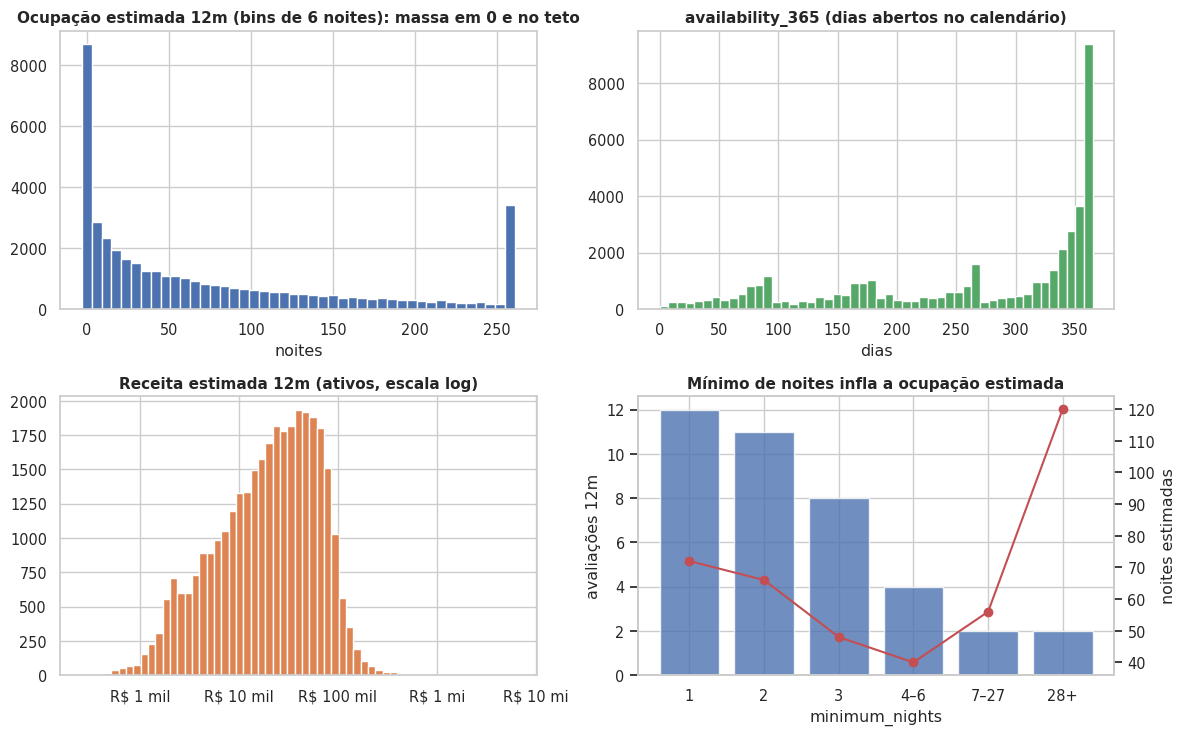

In [15]:
occ = df["estimated_occupancy_l365d"]
cap = int(occ.max())
rev_all = df["estimated_revenue_l365d"].dropna().sort_values(ascending=False)
print(f"Ocupação estimada: {pct((occ == 0).mean())} zero (= sem avaliações em 12m) | {pct((occ >= cap).mean())} no teto ({cap} noites) | mediana entre ativos: {dfa['estimated_occupancy_l365d'].median():.0f} noites")
print(f"Anúncios ativos (≥1 avaliação em 12m): {pct(df['active_ltm'].mean())} | disponibilidade_365 mediana: {df['availability_365'].median():.0f} dias | has_availability=f: {pct((df['has_availability'] == False).mean())}")
print(f"Receita estimada (ativos, mediana): {brl(dfa['estimated_revenue_l365d'].median())} | top 1% dos anúncios = {pct(rev_all.head(int(len(rev_all) * .01)).sum() / rev_all.sum())} da receita total estimada; top 10% = {pct(rev_all.head(int(len(rev_all) * .10)).sum() / rev_all.sum())}")
print(f"Spearman(ocupação est., avaliações 12m) = {df[['estimated_occupancy_l365d', 'number_of_reviews_ltm']].corr('spearman').iloc[0, 1]:.3f}")

mb = df[df["active_ltm"]].groupby("min_nights_bucket", observed=True).agg(avaliacoes_12m_mediana=("number_of_reviews_ltm", "median"), ocup_est_mediana=("estimated_occupancy_l365d", "median"), anuncios=("id", "size"))
display(mb.round(1).T)

rev_act = df.loc[df["active_ltm"], "estimated_revenue_l365d"].dropna()
rev_act = rev_act[rev_act > 0]
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
ax[0, 0].hist(occ, bins=np.arange(-3, 264, 6), color=C[0]); ax[0, 0].set(title="Ocupação estimada 12m (bins de 6 noites): massa em 0 e no teto", xlabel="noites")
ax[0, 1].hist(df["availability_365"], bins=50, color=C[2]); ax[0, 1].set(title="availability_365 (dias abertos no calendário)", xlabel="dias")
ax[1, 0].hist(rev_act, bins=np.logspace(np.log10(rev_act.min()), np.log10(rev_act.max()), 60), color=C[1]); ax[1, 0].set_xscale("log")
ax[1, 0].xaxis.set_major_formatter(BRL_SHORT); ax[1, 0].set(title="Receita estimada 12m (ativos, escala log)")
ax[1, 1].bar(mb.index.astype(str), mb["avaliacoes_12m_mediana"], color=C[0], alpha=.8, label="avaliações 12m (mediana)")
ax2 = ax[1, 1].twinx(); ax2.plot(mb.index.astype(str), mb["ocup_est_mediana"], "o-", color=C[3], label="ocupação estimada (mediana)"); ax2.grid(False)
ax[1, 1].set(title="Mínimo de noites infla a ocupação estimada", xlabel="minimum_nights", ylabel="avaliações 12m")
ax2.set_ylabel("noites estimadas")
fig.tight_layout()
savefig("07_ocupacao_receita")

**Leitura**
- Ocupação e receita são **derivadas**, não observadas: `ocupação = min(255, 2 × avaliações_12m × max(3, minimum_nights))` e `receita = preço cotado × ocupação` (100% das linhas, seção 2.2). O Spearman entre ocupação estimada e avaliações em 12 meses é 0,99.
- 20,6% dos anúncios têm ocupação zero (nenhuma avaliação em 12 meses) e 8% estão no teto de 255 noites; a mediana entre os ativos é 72 noites.
- O mínimo de noites **infla** a estimativa: anúncios com `minimum_nights ≥ 28` têm mediana de 2 avaliações em 12 meses (contra 12 nos de 1 noite), mas ocupação estimada de 120 noites (contra 72).
- A receita estimada é concentrada: top 1% dos anúncios = 9% do total; top 10% = 40%.
- Consequência: "demanda" e "receita" calculadas a partir desses campos **não são independentes**. Para triangular, vale olhar também `availability_30/60/90` (calendário), lembrando que dia bloqueado ≠ dia reservado.

## 8. Avaliações

Sem avaliações: 13.6% | com <5 avaliações: 31.5% | mediana de avaliações: 14 | 100+: 10.2%
Nota: mediana 4.89 | média 4.77 | nota ≥ 4,8: 67.4% | nota = 5,0: 28.2% | nota < 4,0: 2.8%  → efeito teto


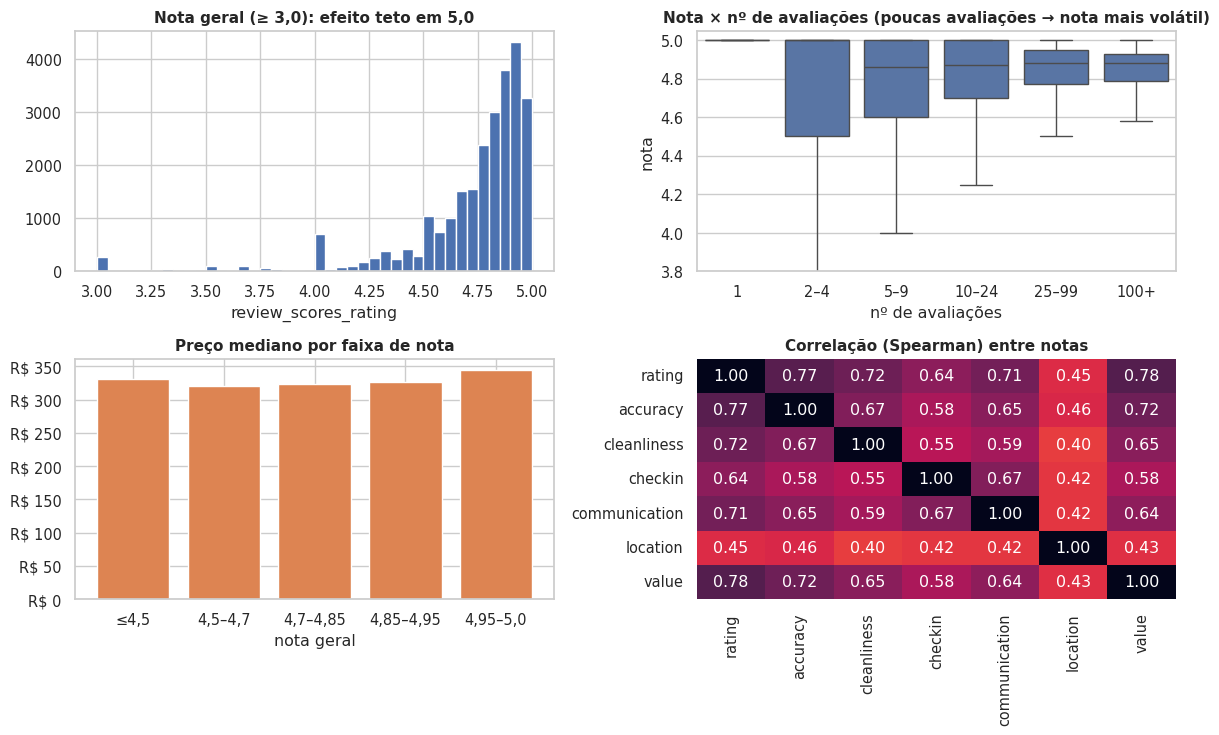

In [16]:
rv = df[df["has_reviews"]].copy()
rv["rev_bucket"] = pd.cut(rv["number_of_reviews"], [0, 1, 4, 9, 24, 99, np.inf], labels=["1", "2–4", "5–9", "10–24", "25–99", "100+"])
dfp_r = dfp.assign(rating_bucket=pd.cut(dfp["review_scores_rating"], [0, 4.5, 4.7, 4.85, 4.95, 5.0], labels=["≤4,5", "4,5–4,7", "4,7–4,85", "4,85–4,95", "4,95–5,0"]))
score_cols = ["review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin", "review_scores_communication", "review_scores_location", "review_scores_value"]

r = rv["review_scores_rating"]
print(f"Sem avaliações: {pct((~df['has_reviews']).mean())} | com <5 avaliações: {pct((df['number_of_reviews'] < 5).mean())} | mediana de avaliações: {df['number_of_reviews'].median():.0f} | 100+: {pct((df['number_of_reviews'] >= 100).mean())}")
print(f"Nota: mediana {r.median():.2f} | média {r.mean():.2f} | nota ≥ 4,8: {pct((r >= 4.8).mean())} | nota = 5,0: {pct((r == 5).mean())} | nota < 4,0: {pct((r < 4).mean())}  → efeito teto")

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
ax[0, 0].hist(r[r >= 3], bins=np.arange(3, 5.05, .05), color=C[0]); ax[0, 0].set(title="Nota geral (≥ 3,0): efeito teto em 5,0", xlabel="review_scores_rating")
sns.boxplot(data=rv, x="rev_bucket", y="review_scores_rating", showfliers=False, color=C[0], ax=ax[0, 1])
ax[0, 1].set(title="Nota × nº de avaliações (poucas avaliações → nota mais volátil)", xlabel="nº de avaliações", ylabel="nota", ylim=(3.8, 5.05))
pb = dfp_r.groupby("rating_bucket", observed=True)["price"].agg(["median", "size"])
ax[1, 0].bar(pb.index.astype(str), pb["median"], color=C[1]); ax[1, 0].yaxis.set_major_formatter(BRL)
ax[1, 0].set(title="Preço mediano por faixa de nota", xlabel="nota geral")
sns.heatmap(rv[score_cols].corr("spearman"), annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, ax=ax[1, 1], cbar=False,
            xticklabels=[c.replace("review_scores_", "") for c in score_cols], yticklabels=[c.replace("review_scores_", "") for c in score_cols])
ax[1, 1].set(title="Correlação (Spearman) entre notas")
fig.tight_layout()
savefig("08_avaliacoes")

**Leitura**
- **Efeito teto**: mediana 4,89; 28% dos anúncios avaliados têm nota exatamente 5,0 e 67% têm ≥ 4,8; só 2,8% ficam abaixo de 4,0. A nota discrimina pouco para a maioria dos anúncios.
- Com poucas avaliações a nota é mais volátil (31,5% dos anúncios têm menos de 5 avaliações), e o preço mediano quase não muda com a nota (R\$ 321 a R\$ 344 entre as faixas).
- As sub-notas são bastante correlacionadas entre si (ρ de 0,40 a 0,78, mediana 0,64): refletem em boa parte um fator geral de satisfação.

## 9. Tempo: entrada de anúncios e recência
Não há data de criação do anúncio; usamos `first_review` como *proxy* de entrada (só existe para anúncios com avaliação).

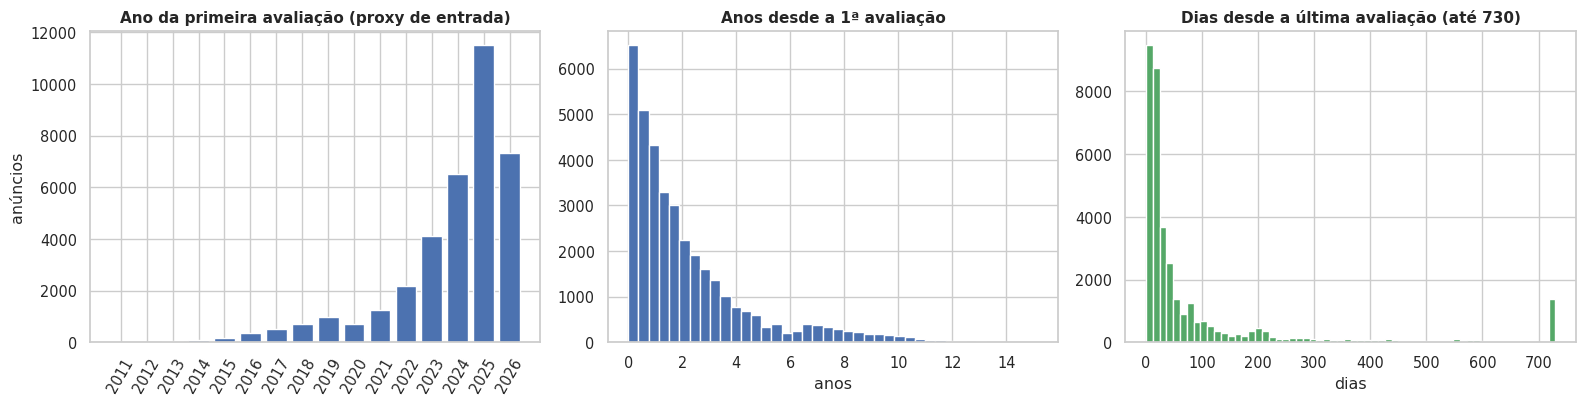

Entre os anúncios com avaliação, 51.5% tiveram a 1ª avaliação em 2025–2026 e 39.9% nos últimos 12 meses.
Última avaliação há ≤ 90 dias: 77.2% | há > 365 dias: 8.0% (entre os que têm avaliação)


In [17]:
fy = df["first_review"].dt.year.value_counts().sort_index()
rec = df["days_since_last_review"].dropna()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].bar(fy.index.astype(int).astype(str), fy.values, color=C[0]); ax[0].tick_params(axis="x", rotation=60)
ax[0].set(title="Ano da primeira avaliação (proxy de entrada)", ylabel="anúncios")
ax[1].hist(df["years_since_first_review"].dropna(), bins=40, color=C[0]); ax[1].set(title="Anos desde a 1ª avaliação", xlabel="anos")
ax[2].hist(rec.clip(upper=730), bins=60, color=C[2]); ax[2].set(title="Dias desde a última avaliação (até 730)", xlabel="dias")
fig.tight_layout()
savefig("09_tempo")

recent = df["first_review"] >= pd.Timestamp("2025-01-01")
print(f"Entre os anúncios com avaliação, {pct(recent.sum() / df['has_reviews'].sum())} tiveram a 1ª avaliação em 2025–2026 e {pct((df['years_since_first_review'] < 1).sum() / df['has_reviews'].sum())} nos últimos 12 meses.")
print(f"Última avaliação há ≤ 90 dias: {pct((rec <= 90).mean())} | há > 365 dias: {pct((rec > 365).mean())} (entre os que têm avaliação)")

**Leitura**
- **Mercado jovem**: entre os anúncios com avaliação, 51,5% tiveram a primeira avaliação em 2025–2026 e 40% nos últimos 12 meses. Muitos anúncios têm histórico curto, o que deixa notas e ocupação estimada instáveis e penaliza entrantes recentes em métricas de demanda.
- 77% receberam avaliação nos últimos 90 dias; 8% estão parados há mais de 1 ano.

## 10. Espacial
Sem shapefile, usamos `hexbin` (lat/lon com correção de aspecto). Nos painéis de preço/receita, hexágonos com menos de 8 anúncios ficam em branco.

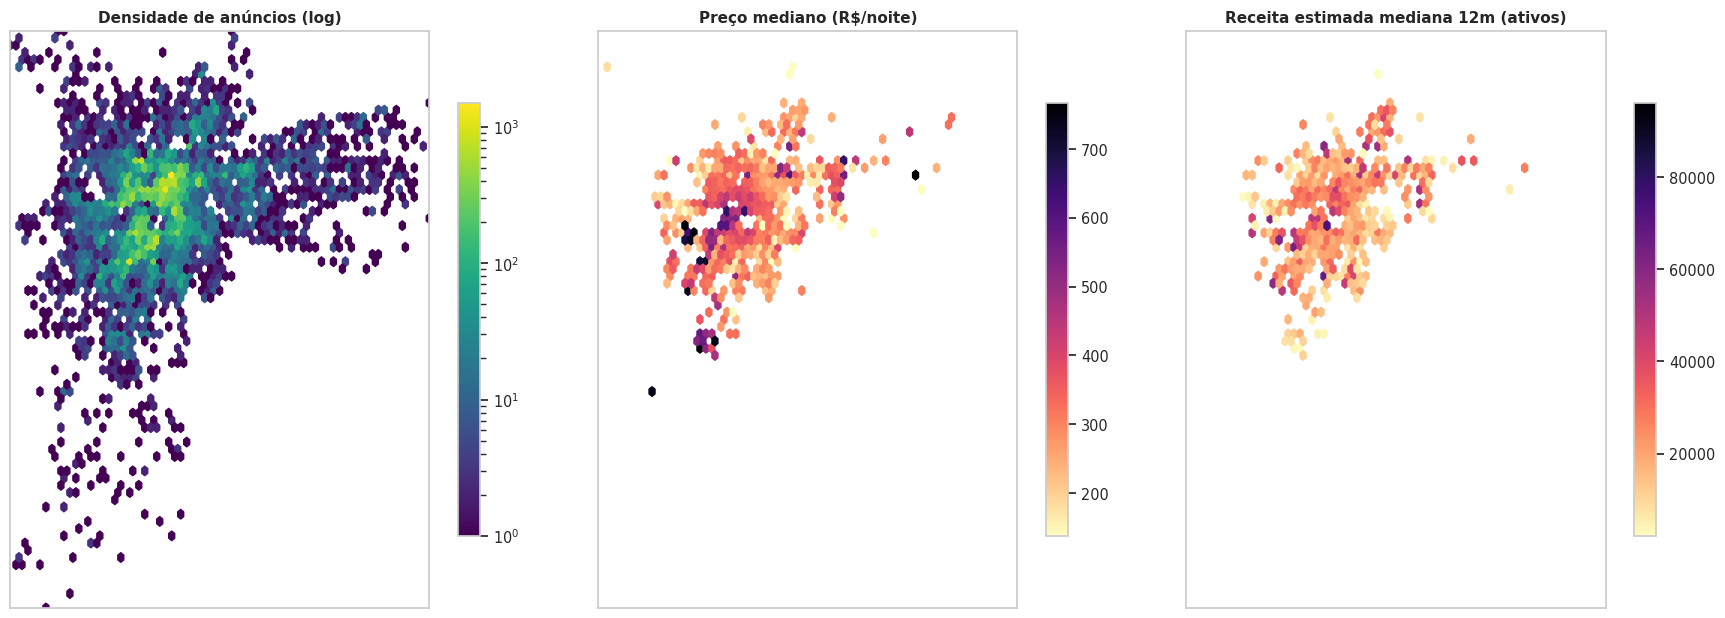

In [18]:
asp = 1 / np.cos(np.deg2rad(df["latitude"].mean()))
ext = (df["longitude"].min(), df["longitude"].max(), df["latitude"].min(), df["latitude"].max())   # mesma extensão nos 3 painéis
panels = [
    (df, None, "Densidade de anúncios (log)", "viridis", dict(bins="log", mincnt=1)),
    (dfp, "price", "Preço mediano (R$/noite)", "magma_r", dict(mincnt=8, reduce_C_function=np.median, vmin=dfp["price"].quantile(.05), vmax=dfp["price"].quantile(.95))),
    (dfa, "estimated_revenue_l365d", "Receita estimada mediana 12m (ativos)", "magma_r", dict(mincnt=8, reduce_C_function=np.median, vmin=dfa["estimated_revenue_l365d"].quantile(.05), vmax=dfa["estimated_revenue_l365d"].quantile(.95))),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
for ax, (frame, cvar, title, cmap, kw) in zip(axes, panels):
    hb = ax.hexbin(frame["longitude"], frame["latitude"], C=None if cvar is None else frame[cvar], gridsize=70, cmap=cmap, extent=ext, **kw)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect(asp); ax.set(title=title, xticks=[], yticks=[]); fig.colorbar(hb, ax=ax, shrink=.75)
fig.tight_layout()
savefig("10_mapas_hexbin")

,anuncios,%,ativos_12m_%,rating_medio,preco_p25,preco_mediano,preco_p75,ocup_est_mediana,receita_est_mediana
regiao8,,,,,,,,,
Oeste,15404,36.40,80.30,4.80,301.00,376.00,485.00,66.00,"24,052.50"
Centro,10369,24.50,80.50,4.80,236.00,300.00,373.30,90.00,"26,137.00"
Sul 1,7505,17.70,81.10,4.80,267.00,334.00,401.00,60.00,"19,656.00"
Sul 2,4481,10.60,76.70,4.80,266.00,331.00,426.00,60.00,"19,488.00"
Leste 1,2678,6.30,77.20,4.80,214.00,291.00,399.00,78.00,"22,831.50"
Norte 1,1174,2.80,82.80,4.80,201.90,275.00,343.00,96.00,"26,352.00"
Norte 2,386,0.90,52.10,4.80,137.50,200.00,319.50,48.00,"10,271.00"
Leste 2,357,0.80,44.80,4.70,160.00,263.00,445.80,36.00,"7,464.00"


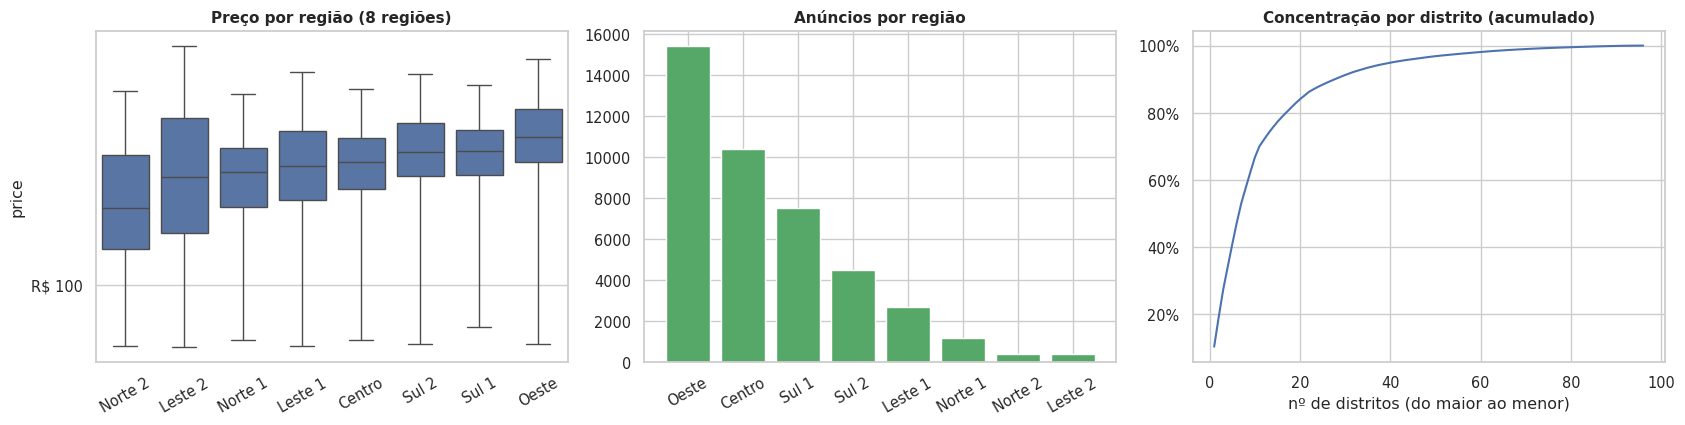

Top 5 distritos: 40.8% dos anúncios | top 10: 66.7% | top 20: 84.0% | mediana por distrito: 74 | distritos com < 30 anúncios: 25
Maiores: Itaim Bibi (4,382), Republica (3,705), Jardim Paulista (3,500), Moema (2,857), Pinheiros (2,838), Vila Mariana (2,722)


In [19]:
reg8 = cat_summary("regiao8")
display(reg8.round(1))
save_table(reg8, "por_regiao8")
order8 = dfp.groupby("regiao8")["price"].median().sort_values().index
ds = df["distrito"].value_counts()
cum_d = ds.cumsum() / ds.sum()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.boxplot(data=dfp, x="regiao8", y="price", order=order8, showfliers=False, color=C[0], ax=ax[0]); ax[0].set_yscale("log"); ax[0].yaxis.set_major_formatter(BRL)
ax[0].tick_params(axis="x", rotation=30); ax[0].set(title="Preço por região (8 regiões)", xlabel="")
cnt8 = df["regiao8"].value_counts()
ax[1].bar(cnt8.index, cnt8.values, color=C[2]); ax[1].tick_params(axis="x", rotation=30); ax[1].set(title="Anúncios por região")
ax[2].plot(np.arange(1, len(cum_d) + 1), cum_d.values, color=C[0]); ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax[2].set(title="Concentração por distrito (acumulado)", xlabel="nº de distritos (do maior ao menor)")
fig.tight_layout()
savefig("10_regioes_concentracao")

print(f"Top 5 distritos: {pct(cum_d.iloc[4])} dos anúncios | top 10: {pct(cum_d.iloc[9])} | top 20: {pct(cum_d.iloc[19])} | mediana por distrito: {ds.median():.0f} | distritos com < {MIN_LISTINGS_DISTRICT} anúncios: {(ds < MIN_LISTINGS_DISTRICT).sum()}")
print("Maiores:", ", ".join(f"{lab(k)} ({v:,})" for k, v in ds.head(6).items()))

**Leitura**
- **Concentração espacial forte**: top 5 distritos = 41% dos anúncios; top 10 = 67%; top 20 = 84% (mediana de 74 anúncios por distrito; 25 distritos com menos de 30).
- A Zona Oeste lidera em preço (mediana R\$ 376), mas o Centro tem ocupação e receita estimadas maiores (90 noites e R\$ 26,1 mil contra 66 noites e R\$ 24,1 mil na Oeste): **rankings por preço e por receita não coincidem**.
- Norte 2 e Leste 2 têm menos de 1% dos anúncios cada e baixa atividade (52% e 45% ativos em 12 meses).

## 11. Agregados distritais (IPTU, crime, POI)
As 109 colunas distritais assumem **96 valores distintos** (um por distrito). Correlacioná-las com o preço *por anúncio* (n ≈ 38 mil) infla o tamanho amostral — é pseudo-replicação. A unidade correta para essas features é o **distrito (n = 96)**, descartando distritos com amostra baixa. `build_district_table` já entrega essa visão.

In [20]:
def build_district_table(d, dprice, dactive, min_n=MIN_LISTINGS_DISTRICT):
    """Uma linha por distrito: métricas dos anúncios (agregadas) + atributos distritais (IPTU, crime, POI)."""
    g = d.groupby("distrito")
    out = pd.DataFrame({
        "n_anuncios": g.size(),
        "pct_entire_home": (d["room_type"] == "Entire home/apt").groupby(d["distrito"]).mean(),
        "pct_superhost": g["host_is_superhost"].mean(),
        "pct_host_5mais": (d["calculated_host_listings_count"] >= 5).groupby(d["distrito"]).mean(),
        "pct_ativos": g["active_ltm"].mean(),
        "rating_medio": g["review_scores_rating"].mean(),
        "avail365_mediana": g["availability_365"].median(),
        "lat_c": g["latitude"].median(), "lon_c": g["longitude"].median(), "dist_centro_km": g["dist_centro_km"].median(),
    })
    gp = dprice.groupby("distrito")["price"]
    out["n_preco_ok"] = gp.size()
    out["preco_p25"], out["preco_mediano"], out["preco_p75"] = gp.quantile(.25), gp.median(), gp.quantile(.75)
    ga = dactive.groupby("distrito")
    out["receita_mediana"], out["ocup_mediana"] = ga["estimated_revenue_l365d"].median(), ga["estimated_occupancy_l365d"].median()
    attrs = (["regiao5", "regiao8", "area_km2", "crime_source", "crime_n_dp", "crime_total", "crime_total_km2", "crime_violento_km2",
              "crime_patrimonial_km2", "iptu_n", "iptu_venal_m2_median", "iptu_idade_median", "iptu_share_apto", "poi_total", "poidens_total"]
             + [f"poidens_{k}" for k in POI_GROUPS])
    out = out.join(g[attrs].first())
    out["anuncios_km2"] = out["n_anuncios"] / out["area_km2"]
    out["amostra_baixa"] = out["n_preco_ok"].fillna(0) < min_n
    return out.sort_values("n_anuncios", ascending=False)


dist = build_district_table(df, dfp, dfa)
save_table(dist, "resumo_distritos")
low = dist["amostra_baixa"]
print(f"{len(dist)} distritos | amostra baixa (< {MIN_LISTINGS_DISTRICT} anúncios com preço comparável): {int(low.sum())} distritos, {pct(dist.loc[low, 'n_anuncios'].sum() / len(df))} dos anúncios")
display(dist.head(TOP_N)[["regiao5", "n_anuncios", "preco_mediano", "receita_mediana", "ocup_mediana", "pct_ativos", "pct_host_5mais",
                          "iptu_venal_m2_median", "crime_total_km2", "poidens_total", "crime_source"]].round(2))

96 distritos | amostra baixa (< 30 anúncios com preço comparável): 31 distritos, 1.4% dos anúncios


,regiao5,n_anuncios,preco_mediano,receita_mediana,ocup_mediana,pct_ativos,pct_host_5mais,iptu_venal_m2_median,crime_total_km2,poidens_total,crime_source
distrito,,,,,,,,,,,
ITAIM BIBI,Oeste,4382,423.00,"23,400.00",54.00,0.81,0.65,105.40,682.68,20.35,dp-direct
REPUBLICA,Centro,3705,271.50,"26,376.00",96.00,0.82,0.54,191.40,"5,577.81",111.81,nearest-imputed
JARDIM PAULISTA,Oeste,3500,393.00,"28,560.00",72.00,0.81,0.59,122.44,"1,412.96",45.26,dp-direct
MOEMA,Sul,2857,374.00,"24,039.00",66.00,0.83,0.66,107.92,753.80,9.69,nearest-imputed
PINHEIROS,Oeste,2838,366.50,"25,643.00",72.00,0.82,0.58,98.80,"1,638.78",47.72,dp-direct
VILA MARIANA,Sul,2722,326.00,"18,324.00",60.00,0.82,0.60,94.10,754.25,19.31,dp-direct
BELA VISTA,Centro,2459,325.00,"24,990.00",78.00,0.81,0.58,147.70,"2,434.14",39.37,nearest-imputed
PERDIZES,Oeste,1979,336.65,"20,203.50",60.00,0.83,0.55,78.60,"2,166.93",10.89,dp-direct
CONSOLACAO,Centro,1927,337.47,"31,435.50",96.00,0.81,0.52,134.59,"2,341.02",48.49,dp-direct


### 11.1 Cobertura e qualidade das features distritais

In [21]:
cov = dist.groupby("crime_source").agg(distritos=("n_anuncios", "size"), anuncios=("n_anuncios", "sum"))
cov["% dos anúncios"] = cov["anuncios"] / cov["anuncios"].sum() * 100
display(cov.round(1))
imp = dist[dist["crime_source"] == "nearest-imputed"]
print("Maiores distritos com crime IMPUTADO (valor do DP mais próximo):", ", ".join(f"{lab(i)} ({n:,})" for i, n in imp["n_anuncios"].head(6).items()))

poi_cov = dist.groupby("regiao5").agg(distritos=("poi_total", "size"), poi_total_mediano=("poi_total", "median"), distritos_sem_poi=("poi_total", lambda s: int((s == 0).sum())))
display(poi_cov)
print("→ POIs vêm do OSM: a contagem cai fortemente fora do centro-oeste (viés de cobertura), então 'poi' mede em parte a completude do mapeamento.")

,distritos,anuncios,% dos anúncios
crime_source,,,
dp-direct,71,28279,66.80
nearest-imputed,25,14075,33.20


Maiores distritos com crime IMPUTADO (valor do DP mais próximo): Republica (3,705), Moema (2,857), Bela Vista (2,459), Santo Amaro (1,862), Saude (810), Barra Funda (567)


,distritos,poi_total_mediano,distritos_sem_poi
regiao5,,,
Centro,8,122.00,0
Leste,33,3.00,4
Norte,18,10.50,0
Oeste,15,34.00,1
Sul,22,18.00,1


→ POIs vêm do OSM: a contagem cai fortemente fora do centro-oeste (viés de cobertura), então 'poi' mede em parte a completude do mapeamento.


**Leitura**
- **25 dos 96 distritos têm crime imputado** (valor do DP mais próximo) e eles concentram **33% dos anúncios** — inclusive República, Moema, Bela Vista e Santo Amaro, quatro dos maiores. Qualquer resultado que dependa de crime passa por essa imputação.
- Os POIs vêm do OSM e têm viés de cobertura: mediana de 122 POIs por distrito no Centro contra 3 na Zona Leste, e 6 distritos sem nenhum POI. Em parte, "densidade de POI" mede a completude do mapeamento.

### 11.2 Ranking de distritos por preço mediano (somente amostra suficiente)

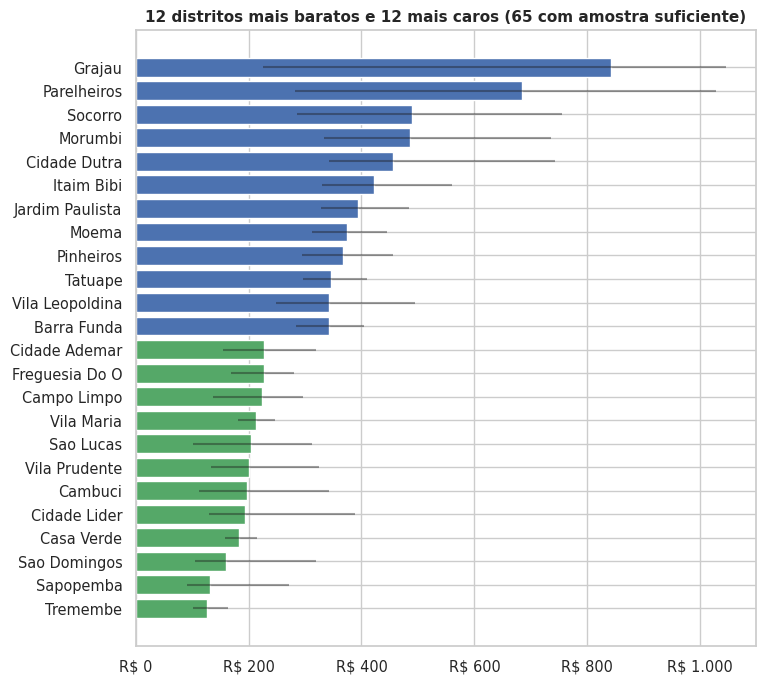

In [22]:
ok = dist[~dist["amostra_baixa"]].sort_values("preco_mediano")
sel = pd.concat([ok.head(12), ok.tail(12)])
med = sel["preco_mediano"]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh([lab(i) for i in sel.index], med, xerr=[med - sel["preco_p25"], sel["preco_p75"] - med], color=[C[2]] * 12 + [C[0]] * 12, error_kw={"alpha": .4})
ax.xaxis.set_major_formatter(BRL); ax.set(title=f"12 distritos mais baratos e 12 mais caros ({len(ok)} com amostra suficiente)")
savefig("11_ranking_distritos_preco")

### 11.3 Correlações **entre distritos** (Spearman, distritos com amostra suficiente)
`*` = p < 0,05 **sem correção para múltiplos testes** (13 features × 4 alvos). Use como triagem exploratória, não como prova.

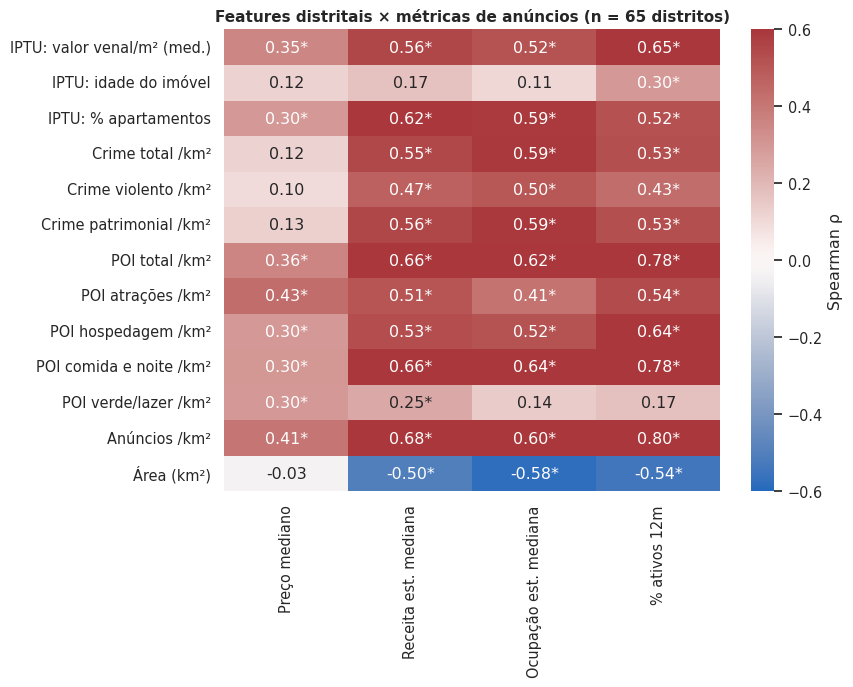

ρ(preço mediano, crime/km²) — todos                 : +0.12 (p = 0.34, n = 65)
ρ(preço mediano, crime/km²) — só crime 'dp-direct'  : +0.13 (p = 0.36, n = 48)


In [23]:
DIST_FEATURES = {
    "iptu_venal_m2_median": "IPTU: valor venal/m² (med.)", "iptu_idade_median": "IPTU: idade do imóvel", "iptu_share_apto": "IPTU: % apartamentos",
    "crime_total_km2": "Crime total /km²", "crime_violento_km2": "Crime violento /km²", "crime_patrimonial_km2": "Crime patrimonial /km²",
    "poidens_total": "POI total /km²", "poidens_atracoes": "POI atrações /km²", "poidens_hospedagem": "POI hospedagem /km²",
    "poidens_comida_noite": "POI comida e noite /km²", "poidens_verde_lazer": "POI verde/lazer /km²", "anuncios_km2": "Anúncios /km²", "area_km2": "Área (km²)",
}
DIST_TARGETS = {"preco_mediano": "Preço mediano", "receita_mediana": "Receita est. mediana", "ocup_mediana": "Ocupação est. mediana", "pct_ativos": "% ativos 12m"}


def spearman_table(frame, targets, features, min_n=10):
    rows = []
    for t in targets:
        for f in features:
            s = frame[[t, f]].dropna()
            if len(s) >= min_n:
                r_, p_ = stats.spearmanr(s[t], s[f])
                rows.append((t, f, r_, p_, len(s)))
    return pd.DataFrame(rows, columns=["alvo", "feature", "rho", "p", "n"])


sp = spearman_table(ok, DIST_TARGETS, DIST_FEATURES)
rho_m = sp.pivot(index="feature", columns="alvo", values="rho").loc[list(DIST_FEATURES), list(DIST_TARGETS)]
star = sp.assign(s=np.where(sp["p"] < .05, "*", "")).pivot(index="feature", columns="alvo", values="s").loc[list(DIST_FEATURES), list(DIST_TARGETS)]
annot = rho_m.apply(lambda col: col.map("{:.2f}".format)) + star
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(rho_m, annot=annot, fmt="", cmap="vlag", center=0, vmin=-.6, vmax=.6, ax=ax, cbar_kws={"label": "Spearman ρ"},
            xticklabels=list(DIST_TARGETS.values()), yticklabels=list(DIST_FEATURES.values()))
ax.set(title=f"Features distritais × métricas de anúncios (n = {len(ok)} distritos)", xlabel="", ylabel="")
savefig("11_correlacao_distrital")

direct = ok[ok["crime_source"] == "dp-direct"]
for nm, fr in [("todos", ok), ("só crime 'dp-direct'", direct)]:
    r_, p_ = stats.spearmanr(fr["preco_mediano"], fr["crime_total_km2"])
    print(f"ρ(preço mediano, crime/km²) — {nm:22s}: {r_:+.2f} (p = {p_:.2f}, n = {len(fr)})")

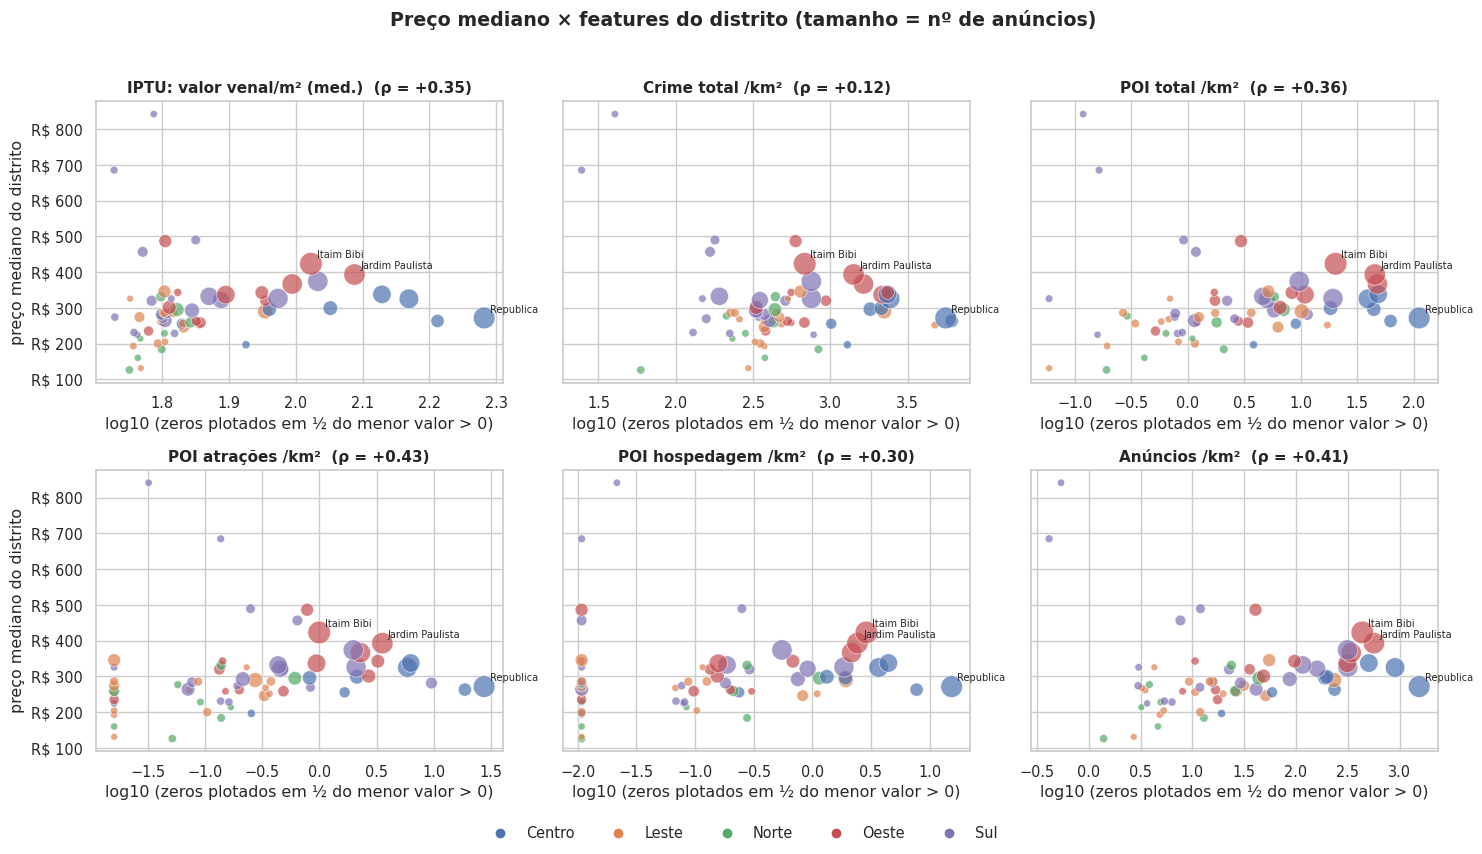

In [24]:
def logx(s):
    """log10 seguro para colunas com zeros."""
    pos = s[s > 0]
    return np.log10(s.where(s > 0, pos.min() / 2))


scatter_feats = ["iptu_venal_m2_median", "crime_total_km2", "poidens_total", "poidens_atracoes", "poidens_hospedagem", "anuncios_km2"]
reg_colors = dict(zip(sorted(dist["regiao5"].unique()), C))
big3 = ok.nlargest(3, "n_anuncios").index
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharey=True)
for ax, f in zip(axes.ravel(), scatter_feats):
    ax.scatter(logx(ok[f]), ok["preco_mediano"], s=np.sqrt(ok["n_anuncios"]) * 4, c=ok["regiao5"].map(reg_colors), alpha=.7, edgecolor="w", lw=.5)
    for i in big3:
        ax.annotate(lab(i), (logx(ok[f])[i], ok.loc[i, "preco_mediano"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
    r_ = sp[(sp["alvo"] == "preco_mediano") & (sp["feature"] == f)]["rho"].iloc[0]
    ax.set(title=f"{DIST_FEATURES[f]}  (ρ = {r_:+.2f})", xlabel="log10 (zeros plotados em ½ do menor valor > 0)")
    ax.yaxis.set_major_formatter(BRL)
axes[0, 0].set_ylabel("preço mediano do distrito"); axes[1, 0].set_ylabel("preço mediano do distrito")
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in reg_colors.items()], loc="lower center", ncol=5, frameon=False)
fig.suptitle("Preço mediano × features do distrito (tamanho = nº de anúncios)", y=.99, fontweight="bold")
fig.tight_layout(rect=(0, .04, 1, .97))
savefig("11_scatter_distrital")

**Leitura**
- O **preço mediano** tem correlação só moderada com as features distritais (ρ ≈ 0,3 a 0,4; a maior é POI de atrações, +0,43) e **nenhuma** com crime/km² (+0,12, não significativo).
- **Atividade, ocupação e receita** correlacionam bem mais (ρ ≈ 0,5 a 0,8) com densidade de anúncios, POIs, % de apartamentos e valor venal — e também **positivamente com crime/km²** (+0,55 com receita, +0,59 com ocupação). Isso não é causal: essas variáveis medem, em grande parte, a mesma coisa — **centralidade/densidade urbana** (a área do distrito tem ρ ≈ −0,5 com receita, ocupação e % de ativos). Para "ajustar por risco", controle pela densidade antes de interpretar o crime.
- O topo do ranking de preço (Grajaú R\$ 842, Parelheiros R\$ 685) vem de distritos periféricos com 44 a 55 anúncios com preço comparável — provavelmente casas de lazer e ruído de amostra pequena. Não decida pela mediana bruta: combine com volume e receita.

### 11.4 Colinearidade entre as features distritais (96 distritos)

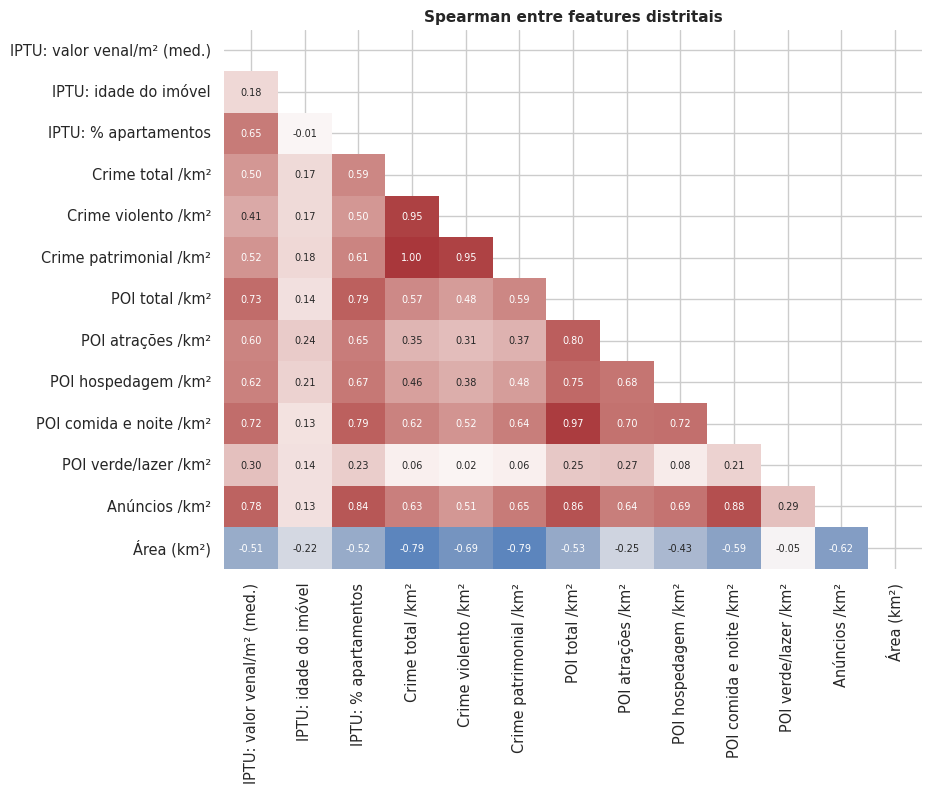

Pares com |ρ| ≥ 0,85: [('Crime violento /km²', 'Crime total /km²', np.float64(0.95)), ('Crime patrimonial /km²', 'Crime total /km²', np.float64(1.0)), ('Crime patrimonial /km²', 'Crime violento /km²', np.float64(0.95)), ('POI comida e noite /km²', 'POI total /km²', np.float64(0.97)), ('Anúncios /km²', 'POI total /km²', np.float64(0.86)), ('Anúncios /km²', 'POI comida e noite /km²', np.float64(0.88))]


In [25]:
cm = dist[list(DIST_FEATURES)].corr("spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool)), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar=False,
            xticklabels=list(DIST_FEATURES.values()), yticklabels=list(DIST_FEATURES.values()), annot_kws={"size": 7})
ax.set(title="Spearman entre features distritais")
savefig("11_colinearidade_distrital")
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(cm.index) for b in cm.columns[:i] if abs(cm.loc[a, b]) >= .85]
print("Pares com |ρ| ≥ 0,85:", [(DIST_FEATURES[a], DIST_FEATURES[b], round(r_, 2)) for a, b, r_ in pairs] or "nenhum")

**Leitura**
- Há muita redundância: `crime_patrimonial` ≈ `crime_total` (ρ = 1,00 — o total é praticamente só crime patrimonial), POIs de "comida e noite" ≈ POI total (0,97) e anúncios/km² anda junto com POI total (0,86). As 13 features distritais carregam bem menos dimensões independentes do que colunas: escolha um representante por grupo ou use PCA antes de modelar.

## 12. O que explica o preço?
### 12.1 Correlação (Spearman) com o log-preço — nível do anúncio
As variáveis distritais aparecem separadas: aqui elas só têm 96 valores possíveis, então refletem diferenças *entre* distritos.

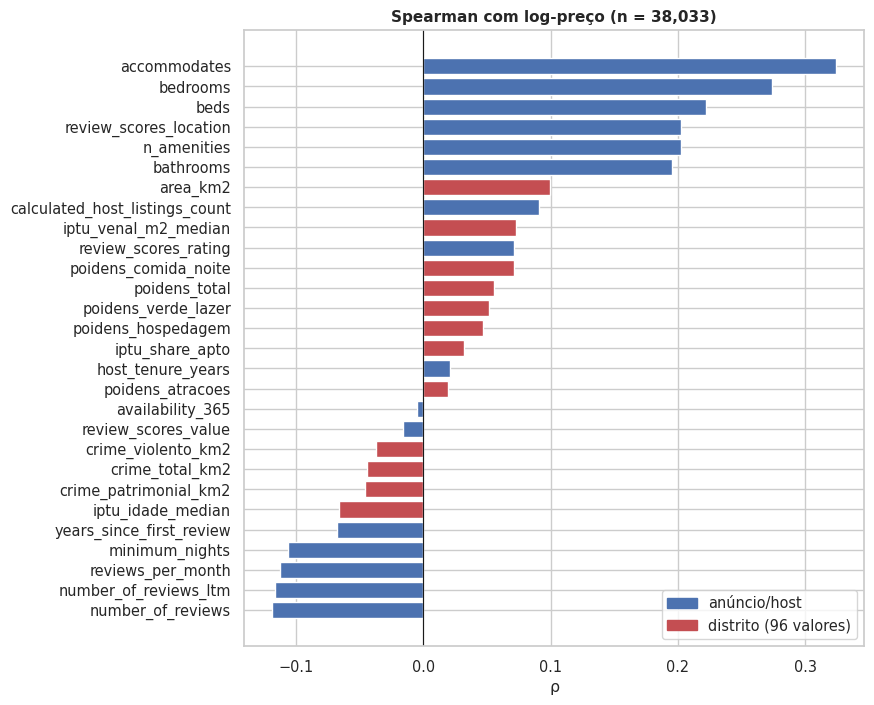

In [26]:
LISTING_FEATURES = ["accommodates", "bedrooms", "beds", "bathrooms", "n_amenities", "minimum_nights", "availability_365", "number_of_reviews",
                    "number_of_reviews_ltm", "reviews_per_month", "review_scores_rating", "review_scores_location", "review_scores_value",
                    "host_tenure_years", "calculated_host_listings_count", "years_since_first_review"]
DIST_FEATURES_L = [f for f in DIST_FEATURES if f in dfp.columns]          # 'anuncios_km2' só existe na tabela distrital
rho_l = dfp[LISTING_FEATURES + DIST_FEATURES_L + ["log_price"]].corr("spearman")["log_price"].drop("log_price")
plot_df = pd.DataFrame({"rho": rho_l, "grupo": ["anúncio/host"] * len(LISTING_FEATURES) + ["distrito"] * len(DIST_FEATURES_L)}).sort_values("rho")
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(plot_df.index, plot_df["rho"], color=plot_df["grupo"].map({"anúncio/host": C[0], "distrito": C[3]}))
ax.axvline(0, color="k", lw=.8)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C[0]), plt.Rectangle((0, 0), 1, 1, color=C[3])], labels=["anúncio/host", "distrito (96 valores)"], loc="lower right")
ax.set(title=f"Spearman com log-preço (n = {len(dfp):,})", xlabel="ρ")
savefig("12_correlacao_log_preco")

**Leitura**
- No nível do anúncio, o preço se associa ao **tamanho**: capacidade (ρ = 0,32), quartos (0,27), camas (0,22), banheiros (0,20), nº de amenities (0,20) e nota de localização (0,20).
- Associações negativas: nº de avaliações (−0,12), avaliações por mês (−0,11) e mínimo de noites (−0,11) — anúncios mais baratos giram mais.
- As variáveis distritais têm |ρ| ≤ 0,10 aqui. Isso não significa que não importam: elas só assumem 96 valores, e o distrito explica uma fração limitada da variância (próximas células).

### 12.2 Quanto da variância do log-preço cada agrupamento explica? (η² ajustado)
Como as features distritais só variam *entre* distritos, o η² do `distrito` é o **teto** do que elas podem explicar no nível do anúncio.

,eta2,eta2_ajustado,grupos
porte do host,0.01,0.01,4.00
regiao5 (5 regiões),0.05,0.05,5.00
distrito (região),0.14,0.14,96.00
quartos (bed_b),0.15,0.15,6.00
room_type,0.16,0.16,4.00
capacidade (acc_b),0.19,0.19,6.00
property_type,0.20,0.20,66.00
room_type × capacidade,0.27,0.27,24.00
distrito × room_type,0.30,0.30,243.00
distrito × room_type × capacidade,0.46,0.44,936.00


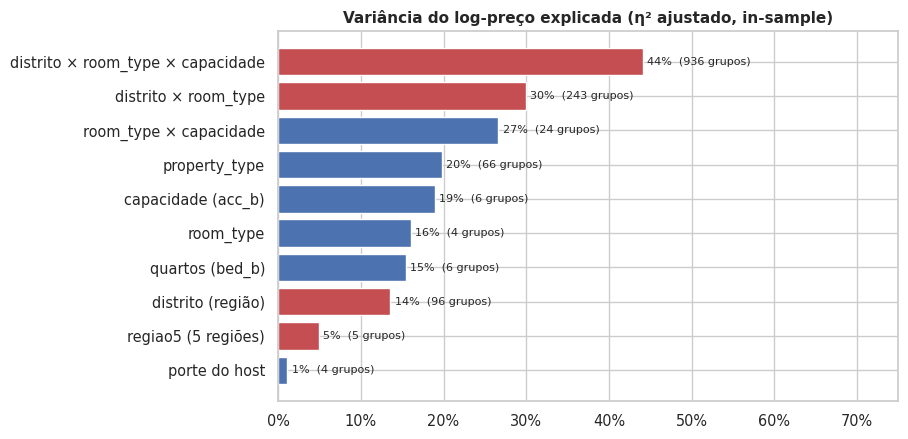

In [27]:
def eta2(frame, by, y="log_price"):
    by = [by] if isinstance(by, str) else list(by)
    g = frame.groupby(by, observed=True)[y]
    e = (g.transform("mean") - frame[y].mean()).pow(2).sum() / (frame[y] - frame[y].mean()).pow(2).sum()
    k, n = g.ngroups, len(frame)
    return pd.Series({"eta2": e, "eta2_ajustado": 1 - (1 - e) * (n - 1) / (n - k), "grupos": k})


specs = {
    "regiao5 (5 regiões)": "regiao5", "distrito (região)": "distrito", "room_type": "room_type", "capacidade (acc_b)": "acc_b", "quartos (bed_b)": "bed_b",
    "property_type": "property_type", "porte do host": "host_size",
    "room_type × capacidade": ["room_type", "acc_b"], "distrito × room_type": ["distrito", "room_type"],
    "distrito × room_type × capacidade": ["distrito", "room_type", "acc_b"],
}
et = pd.DataFrame({k: eta2(dfp, v) for k, v in specs.items()}).T.sort_values("eta2_ajustado")
display(et.round(3))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(et.index, et["eta2_ajustado"], color=[C[3] if "distrito" in i or "regiao" in i else C[0] for i in et.index])
for y_, (v, k) in enumerate(zip(et["eta2_ajustado"], et["grupos"])):
    ax.text(v + .005, y_, f"{v:.0%}  ({int(k)} grupos)", va="center", fontsize=8)
ax.set(title="Variância do log-preço explicada (η² ajustado, in-sample)", xlim=(0, .75))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
savefig("12_eta2")

### 12.3 E fora da amostra? Preditor por **célula** (região × perfil)
Prevê o log-preço pela média da célula mais fina disponível no treino (`min_support` anúncios), com cascata para células mais grossas. CV agrupada por **host** (evita vazar o mesmo prédio/host entre treino e teste).

In [28]:
from sklearn.model_selection import GroupKFold


def cell_cv_r2(frame, levels, y="log_price", min_support=5, n_splits=5):
    """R² fora da amostra de um preditor por célula com cascata (do nível mais grosso ao mais fino)."""
    pred = np.full(len(frame), np.nan)
    for tr, te in GroupKFold(n_splits).split(frame, groups=frame["host_id"]):
        trn, tst = frame.iloc[tr], frame.iloc[te]
        p = pd.Series(trn[y].mean(), index=tst.index)
        for keys in levels:
            st = trn.groupby(keys, observed=True)[y].agg(["mean", "size"])
            st = st.loc[st["size"] >= min_support, "mean"].rename("_m")
            p = tst[keys].join(st, on=keys)["_m"].fillna(p)
        pred[te] = p.values
    return 1 - np.sum((frame[y].values - pred) ** 2) / np.sum((frame[y].values - frame[y].mean()) ** 2)


cascades = {
    "só região: regiao5 → distrito": [["regiao5"], ["distrito"]],
    "só perfil: room_type → room_type × capacidade": [["room_type"], ["room_type", "acc_b"]],
    "região + tipo: room_type → distrito × room_type": [["room_type"], ["distrito", "room_type"]],
    "região + perfil: … → distrito × room_type × capacidade": [["room_type"], ["room_type", "acc_b"], ["distrito", "room_type"], ["distrito", "room_type", "acc_b"]],
}
cell_res = pd.Series({k: cell_cv_r2(dfp, v) for k, v in cascades.items()}, name="R² fora da amostra (CV por host)")
display(cell_res.to_frame().round(3))
cells = dfp.groupby(["distrito", "room_type", "acc_b"]).size()
print(f"Células distrito × room_type × capacidade: {len(cells)} | com ≥ 5 anúncios: {(cells >= 5).sum()} células cobrindo {pct(cells[cells >= 5].sum() / len(dfp))} dos anúncios")

,R² fora da amostra (CV por host)
só região: regiao5 → distrito,0.11
só perfil: room_type → room_type × capacidade,0.26
região + tipo: room_type → distrito × room_type,0.26
região + perfil: … → distrito × room_type × capacidade,0.34


Células distrito × room_type × capacidade: 936 | com ≥ 5 anúncios: 468 células cobrindo 97.5% dos anúncios


**Leitura**
- O **distrito sozinho explica ~14%** da variância do log-preço (η² ajustado) e as 5 grandes regiões, 5%. Esse é o **teto** do que IPTU, crime e POI conseguem explicar no nível do anúncio, já que só variam entre distritos.
- O **perfil** pesa mais: tipo de propriedade 20%, capacidade 19% e `room_type` 16%; `room_type × capacidade` chega a 27%.
- **Região + perfil juntos** é o que funciona: fora da amostra (CV agrupada por host), `distrito × room_type × capacidade` atinge R² ≈ 0,34, contra ≈ 0,26 só com perfil e ≈ 0,11 só com região. Com `min_support = 5`, 468 das 936 células cobrem 97,5% dos anúncios, então essa granularidade é viável.

## 13. Amenities
`amenities` é um JSON em texto com ~6,6 mil strings distintas (texto livre, marcas, variações). Trabalhamos com as 40 mais frequentes. O "prêmio" abaixo é a diferença média de log-preço **depois de remover a média de cada distrito × capacidade** — é associação, não causalidade (piscina/academia/portaria são *proxies* do padrão do prédio).

6,582 strings distintas de amenities | anúncios com ≤ 10 amenities: 12.7% | zero amenities: 0.1%


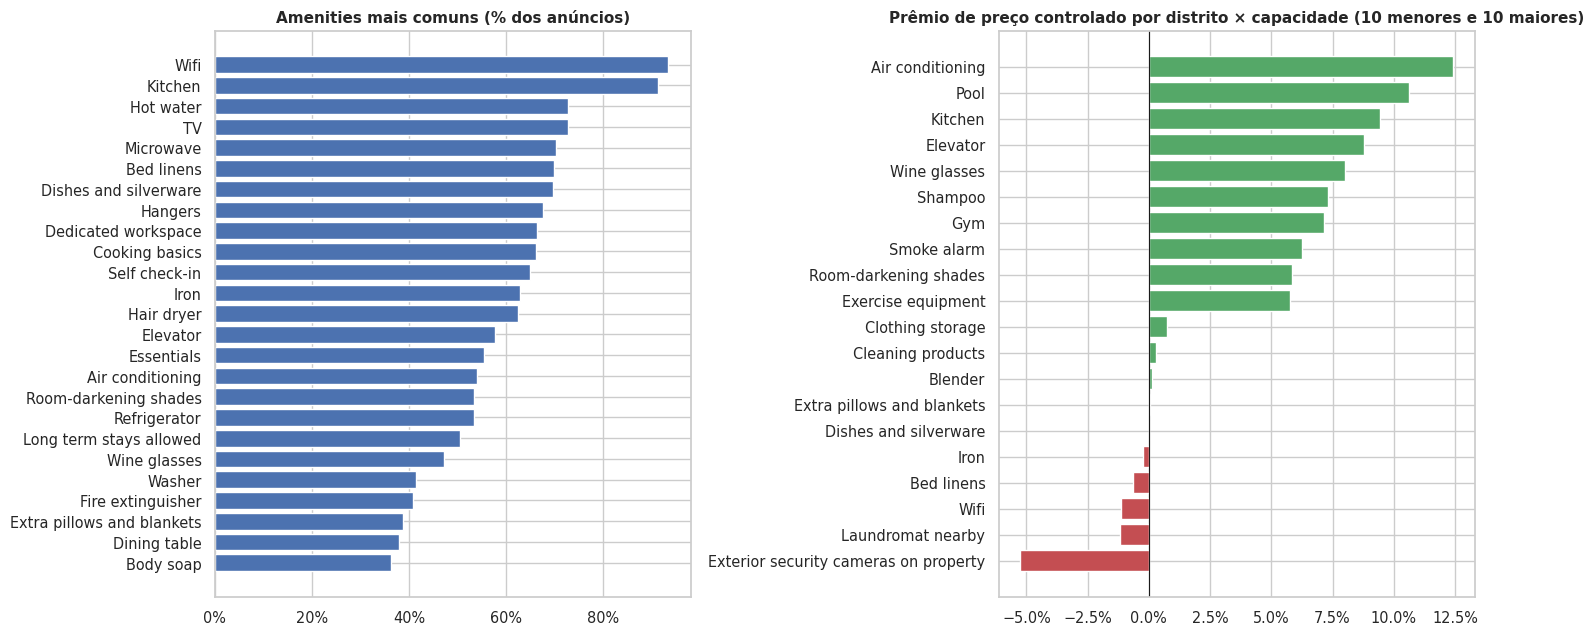

,prevalencia,premio,t
amenity,,,
Exterior security cameras on property,0.28,-0.05,-11.66
Laundromat nearby,0.31,-0.01,-2.89
Wifi,0.94,-0.01,-1.22
Bed linens,0.72,-0.01,-1.36
Iron,0.64,-0.00,-0.57
Smoke alarm,0.34,0.06,14.80
Gym,0.26,0.07,17.30
Shampoo,0.36,0.07,17.85
Wine glasses,0.49,0.08,19.40


Spearman(n_amenities, log-preço) = 0.20


In [29]:
am_sets = df["amenities"].map(parse_amenities).map(set)
cnt = Counter(a for s in am_sets for a in s)
print(f"{len(cnt):,} strings distintas de amenities | anúncios com ≤ 10 amenities: {pct((df['n_amenities'] <= 10).mean())} | zero amenities: {pct((df['n_amenities'] == 0).mean())}")
top_am = [a for a, _ in cnt.most_common(40)]
A = pd.DataFrame({a: am_sets.map(lambda s, a=a: a in s) for a in top_am}, index=df.index)
prev = A.mean().sort_values()

Ap = A.loc[dfp.index]
res = dfp["log_price"] - dfp.groupby(["distrito", "acc_b"])["log_price"].transform("mean")
rows = []
for a in top_am:
    has = Ap[a]
    if .03 <= has.mean() <= .97:
        t_, _ = stats.ttest_ind(res[has], res[~has], equal_var=False)
        rows.append((a, has.mean(), np.expm1(res[has].mean() - res[~has].mean()), t_))
prem = pd.DataFrame(rows, columns=["amenity", "prevalencia", "premio", "t"]).set_index("amenity").sort_values("premio")
show = pd.concat([prem.head(10), prem.tail(10)])

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
ax[0].barh(prev.tail(25).index, prev.tail(25).values, color=C[0]); ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax[0].set(title="Amenities mais comuns (% dos anúncios)")
ax[1].barh(show.index, show["premio"], color=[C[2] if v > 0 else C[3] for v in show["premio"]]); ax[1].axvline(0, color="k", lw=.8)
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1)); ax[1].set(title="Prêmio de preço controlado por distrito × capacidade (10 menores e 10 maiores)")
fig.tight_layout()
savefig("13_amenities")
display(pd.concat([prem.head(5), prem.tail(8)]).round(3))
print(f"Spearman(n_amenities, log-preço) = {dfp[['n_amenities', 'log_price']].corr('spearman').iloc[0, 1]:.2f}")

**Leitura**
- São 6.582 strings distintas de amenities (texto livre e marcas); as 40 mais frequentes bastam para análise. Wi-Fi (93%) e cozinha (91%) são praticamente universais.
- Maiores prêmios (controlados por distrito × capacidade): ar-condicionado (+12%), piscina (+11%), elevador (+9%) e academia (+7%) — *proxies* do padrão do prédio. Itens de "hospitalidade" como *wine glasses* (+8%) também aparecem, provável sinal de curadoria do anúncio. É associação, não causalidade.

## 14. Baseline preditivo (sinal por bloco de variáveis)
Não é um modelo final: serve para medir **quanto sinal** cada bloco traz e **quanto o esquema de validação importa**. Alvo = log-preço em `dfp`. Os R² podem oscilar na 2ª casa decimal conforme a versão do scikit-learn. Ficam de fora `price_pp`, `estimated_revenue_l365d` e `estimated_occupancy_l365d` (derivadas do preço/avaliações → vazamento de alvo).

,features,R² (log-preço),erro % mediano
bloco adicionado,,,
imóvel,9,0.37,21.27
amenities,50,0.44,20.11
host,55,0.44,20.15
avaliações/atividade,63,0.52,18.04
lat/lon,65,0.59,16.44
distrito (IPTU/crime/POI),77,0.59,16.36


,R² (log-preço)
modelo,
imóvel + host,0.34
imóvel (referência),0.37
imóvel + amenities,0.44
imóvel + avaliações/atividade,0.47
imóvel + distrito (IPTU/crime/POI),0.47
imóvel + lat/lon,0.50


,R²,erro % mediano
aleatório,0.66,14.30
por host,0.59,16.36
por distrito,0.56,17.01


Tempo da seção: 80s


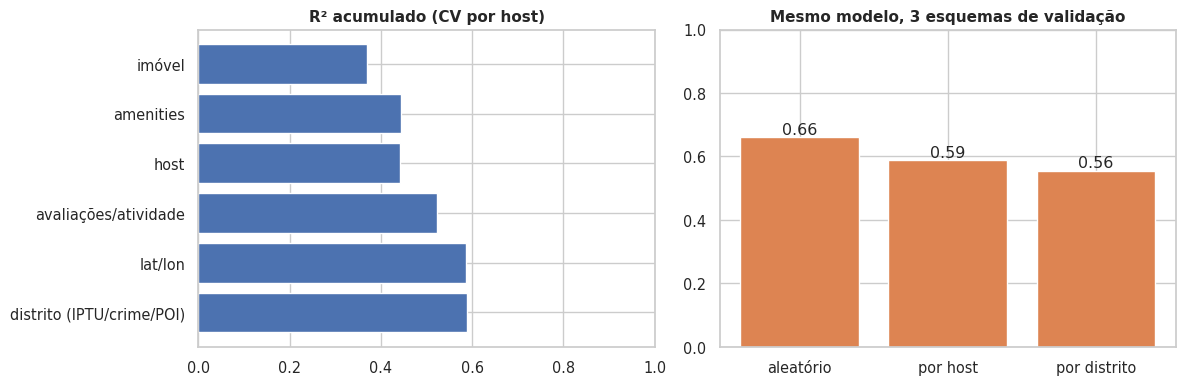

In [30]:
if RUN_BASELINE:
    import time
    from sklearn.ensemble import HistGradientBoostingRegressor
    from sklearn.model_selection import KFold, cross_val_predict
    from sklearn.metrics import r2_score

    t0 = time.time()
    base = dfp.copy()
    for c in ["room_type", "property_type"]:
        keep = base[c].value_counts().index[:20]
        base[c + "_cat"] = base[c].where(base[c].isin(keep), "Outros").astype("category").cat.codes
    base = pd.concat([base, Ap.add_prefix("am_").astype(int)], axis=1)

    BLOCKS = {
        "imóvel": ["accommodates", "bedrooms", "beds", "bathrooms", "bath_shared", "bath_private", "room_type_cat", "property_type_cat", "minimum_nights"],
        "amenities": ["n_amenities"] + [c for c in base.columns if c.startswith("am_")],
        "host": ["host_is_superhost", "host_tenure_years", "calculated_host_listings_count", "host_identity_verified", "host_in_sp"],
        "avaliações/atividade": ["number_of_reviews", "number_of_reviews_ltm", "reviews_per_month", "review_scores_rating", "review_scores_cleanliness",
                                 "review_scores_location", "review_scores_value", "years_since_first_review"],
        "lat/lon": ["latitude", "longitude"],
        "distrito (IPTU/crime/POI)": ["iptu_venal_m2_median", "iptu_idade_median", "iptu_share_apto", "crime_total_km2", "crime_violento_km2",
                                      "crime_patrimonial_km2", "poidens_total"] + [f"poidens_{k}" for k in POI_GROUPS],
    }
    CATEGORICAL = {"room_type_cat", "property_type_cat"}
    y_all = base["log_price"].values

    def to_float(frame, cols):
        return frame[cols].apply(lambda s: s.astype("float64")).values

    def cv_eval(cols, scheme="por host", n_splits=3):
        cat = np.array([c in CATEGORICAL for c in cols])
        model = HistGradientBoostingRegressor(max_iter=200, learning_rate=.1, min_samples_leaf=30, random_state=SEED,
                                              categorical_features=cat if cat.any() else None)
        if scheme == "aleatório":
            cv, groups = KFold(n_splits, shuffle=True, random_state=SEED), None
        else:
            cv, groups = GroupKFold(n_splits), base["host_id" if scheme == "por host" else "distrito"].values
        pred = cross_val_predict(model, to_float(base, cols), y_all, cv=cv, groups=groups)
        return r2_score(y_all, pred), float(np.median(np.abs(np.expm1(pred - y_all))))

    rows, acc_cols = [], []
    for b, cols_b in BLOCKS.items():                                  # (a) acumulado
        acc_cols = acc_cols + cols_b
        r2_, err_ = cv_eval(acc_cols)
        rows.append({"bloco adicionado": b, "features": len(acc_cols), "R² (log-preço)": r2_, "erro % mediano": 100 * err_})
    cumul = pd.DataFrame(rows).set_index("bloco adicionado")
    display(cumul.round(3))

    rows = []
    for b in ["amenities", "host", "avaliações/atividade", "lat/lon", "distrito (IPTU/crime/POI)"]:      # (b) cada bloco sobre 'imóvel'
        r2_, _ = cv_eval(BLOCKS["imóvel"] + BLOCKS[b])
        rows.append({"modelo": f"imóvel + {b}", "R² (log-preço)": r2_})
    solo = pd.DataFrame(rows).set_index("modelo")
    solo.loc["imóvel (referência)"] = cumul.loc["imóvel", "R² (log-preço)"]
    display(solo.sort_values("R² (log-preço)").round(3))

    sch = pd.DataFrame({s: dict(zip(["R²", "erro % mediano"], (lambda r: (r[0], 100 * r[1]))(cv_eval(acc_cols, s)))) for s in ["aleatório", "por host", "por distrito"]}).T
    display(sch.round(3))
    print(f"Tempo da seção: {time.time() - t0:.0f}s")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].barh(cumul.index[::-1], cumul["R² (log-preço)"][::-1], color=C[0]); ax[0].set(title="R² acumulado (CV por host)", xlim=(0, 1))
    ax[1].bar(sch.index, sch["R²"], color=C[1]); ax[1].set(title="Mesmo modelo, 3 esquemas de validação", ylim=(0, 1))
    for i, v in enumerate(sch["R²"]):
        ax[1].text(i, v + .01, f"{v:.2f}", ha="center")
    fig.tight_layout()
    savefig("14_baseline")
else:
    print("RUN_BASELINE = False → seção pulada.")

**Leitura**
- Só com características do imóvel, R² ≈ 0,37 (CV por host); amenities somam ≈ +0,07, avaliações/atividade ≈ +0,08 e lat/lon ≈ +0,07, chegando a 0,59 (erro percentual mediano ≈ 16%).
- O bloco distrital (IPTU/crime/POI) soma **≈ 0 depois de lat/lon**: a informação de localização que ele carrega já está nas coordenadas. Sobre o imóvel, sozinho, ele leva o R² de 0,37 a 0,47 (lat/lon leva a 0,50).
- Features de host **não ajudam** (0,34 sobre o imóvel, abaixo da referência 0,37): provavelmente funcionam como "impressão digital" do host e não generalizam para hosts novos.
- A validação aleatória **superestima**: R² ≈ 0,66 (aleatório) contra ≈ 0,59 (por host) e ≈ 0,56 (por distrito), porque o mesmo host/prédio cai em treino e teste. Prefira CV agrupada.

## Parte II — Aprofundamento: visualizações e insights
As seções 15 a 24 aprofundam o que a Parte I apontou: estrutura de correlações, preço **ajustado por perfil** (o eixo região × perfil), geografia (distância, direção, autocorrelação espacial), tipologia de distritos e o teste do calendário como proxy de demanda. Reutilizam `df`, `dfp`, `dfa` e `dist`; a tabela `dist` ganha colunas novas e é salva de novo no fim da seção 24.

## 15. Estrutura de correlações entre variáveis do anúncio
Clustermap de Spearman (anúncios com preço comparável): o dendrograma agrupa as variáveis que andam juntas.

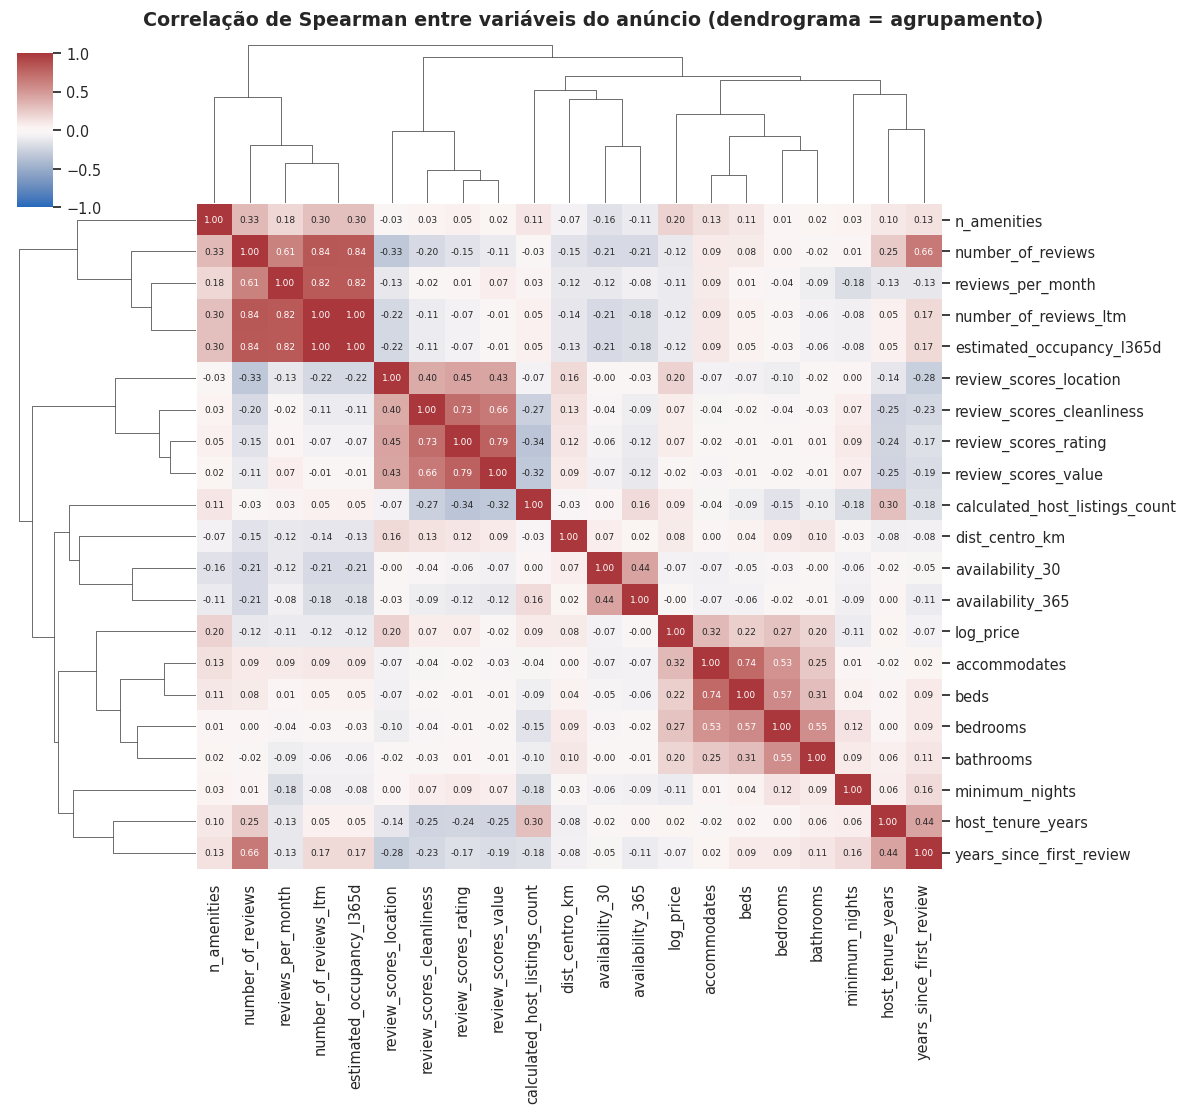

Ordem do dendrograma: n_amenities | number_of_reviews | reviews_per_month | number_of_reviews_ltm | estimated_occupancy_l365d | review_scores_location | review_scores_cleanliness | review_scores_rating | review_scores_value | calculated_host_listings_count | dist_centro_km | availability_30 | availability_365 | log_price | accommodates | beds | bedrooms | bathrooms | minimum_nights | host_tenure_years | years_since_first_review


,var_a,var_b,rho
76,estimated_occupancy_l365d,number_of_reviews_ltm,1.00
54,number_of_reviews_ltm,number_of_reviews,0.84
75,estimated_occupancy_l365d,number_of_reviews,0.84
65,reviews_per_month,number_of_reviews_ltm,0.82
77,estimated_occupancy_l365d,reviews_per_month,0.82
118,review_scores_value,review_scores_rating,0.79
4,beds,accommodates,0.74
133,review_scores_cleanliness,review_scores_rating,0.73
135,review_scores_cleanliness,review_scores_value,0.66
180,years_since_first_review,number_of_reviews,0.66


In [31]:
CORR_VARS = ["log_price", "accommodates", "bedrooms", "beds", "bathrooms", "n_amenities", "minimum_nights", "availability_30", "availability_365",
             "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month", "estimated_occupancy_l365d", "review_scores_rating",
             "review_scores_location", "review_scores_value", "review_scores_cleanliness", "host_tenure_years",
             "calculated_host_listings_count", "years_since_first_review", "dist_centro_km"]
cc = dfp[CORR_VARS].corr("spearman")
cg = sns.clustermap(cc, method="average", cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6.5},
                    figsize=(12, 11), cbar_pos=(0.02, 0.83, 0.03, 0.14))
cg.fig.suptitle("Correlação de Spearman entre variáveis do anúncio (dendrograma = agrupamento)", y=1.01, fontweight="bold")
savefig("15_clustermap_anuncio")

print("Ordem do dendrograma:", " | ".join(cc.columns[i] for i in cg.dendrogram_row.reordered_ind))
pairs = pd.DataFrame([(a, b, cc.loc[a, b]) for i, a in enumerate(cc.index) for b in cc.columns[:i]], columns=["var_a", "var_b", "rho"])
display(pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).head(12).round(2))

**Leitura**
- O dendrograma separa **cinco blocos**: (1) atividade — avaliações, avaliações/mês, avaliações em 12 meses e ocupação estimada (esta tem ρ = 1,00 com as avaliações em 12 meses, por construção); (2) notas — geral, limpeza, custo-benefício e localização (ρ de 0,40 a 0,79 entre si); (3) calendário — `availability_30` e `availability_365`; (4) tamanho — capacidade, camas, quartos e banheiros, que é onde o **preço** se encaixa (ρ = 0,32 com a capacidade); (5) tempo de casa — tempo como host e tempo desde a 1ª avaliação.
- O preço é quase **independente da atividade** (|ρ| ≈ 0,12) e da nota geral (0,07): cobrar mais não se associa a ter mais nem menos avaliações.
- `n_amenities` anda mais com a **atividade** (ρ = 0,30 com avaliações em 12 meses) do que com o preço (0,20): anúncios mais completos tendem a ter mais avaliações.
- Hosts com **muitos anúncios** têm notas menores (ρ de −0,27 a −0,34 com limpeza, nota geral e custo-benefício), e calendários mais abertos andam com menos avaliações (ρ ≈ −0,2).

## 16. Preço e receita por segmento (região × perfil)
### 16.1 Distribuição por região e tipo de quarto

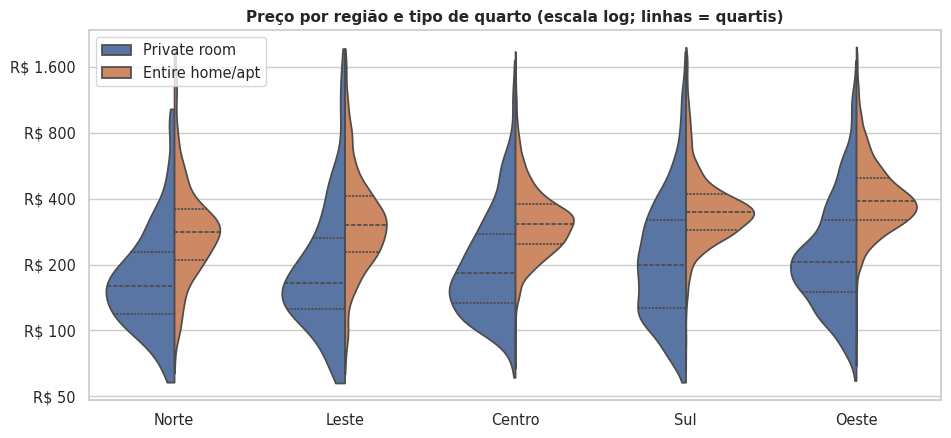

room_type,Entire home/apt,Private room,razão inteiro/privado
regiao5,,,
Norte,281.84,160.00,1.76
Leste,304.00,164.67,1.85
Centro,307.19,182.00,1.69
Sul,346.16,200.00,1.73
Oeste,389.00,206.00,1.89


In [32]:
seg2 = dfp[dfp["room_type"].isin(["Entire home/apt", "Private room"])].copy()
seg2["log10_price"] = np.log10(seg2["price"])
order5 = list(seg2.groupby("regiao5")["price"].median().sort_values().index)
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.violinplot(data=seg2, x="regiao5", y="log10_price", hue="room_type", order=order5, split=True, inner="quart", cut=0, palette=[C[0], C[1]], ax=ax)
ticks = [50, 100, 200, 400, 800, 1600]
ax.set_yticks(np.log10(ticks)); ax.set_yticklabels([brl(t) for t in ticks])
ax.set(xlabel="", ylabel="", title="Preço por região e tipo de quarto (escala log; linhas = quartis)")
ax.legend(title="", loc="upper left")
savefig("16_violino_regiao_tipo")
tab = seg2.pivot_table(index="regiao5", columns="room_type", values="price", aggfunc="median").loc[order5]
tab["razão inteiro/privado"] = tab["Entire home/apt"] / tab["Private room"]
display(tab.round(2))

**Leitura**
- A hierarquia de regiões é a mesma nos dois tipos de quarto (Norte < Leste < Centro < Sul < Oeste) e a razão entre quarto inteiro e privado é estável, de 1,7 a 1,9 em todas as regiões: o *tipo de quarto* funciona como um multiplicador quase constante sobre a região.
- O Oeste cobra ≈ 27% a mais que o Centro por um apartamento inteiro (R\$ 389 × R\$ 307) e ≈ 13% a mais por um quarto privado (R\$ 206 × R\$ 182).
- As distribuições se sobrepõem bastante: a diferença entre regiões é pequena frente à dispersão dentro de cada uma (coerente com o η² de 5% de `regiao5`).

### 16.2 Região × capacidade: preço, prêmio relativo e receita estimada
Células com menos de 20 anúncios ficam em branco. A receita é a **estimada** (derivada — ver seção 7).

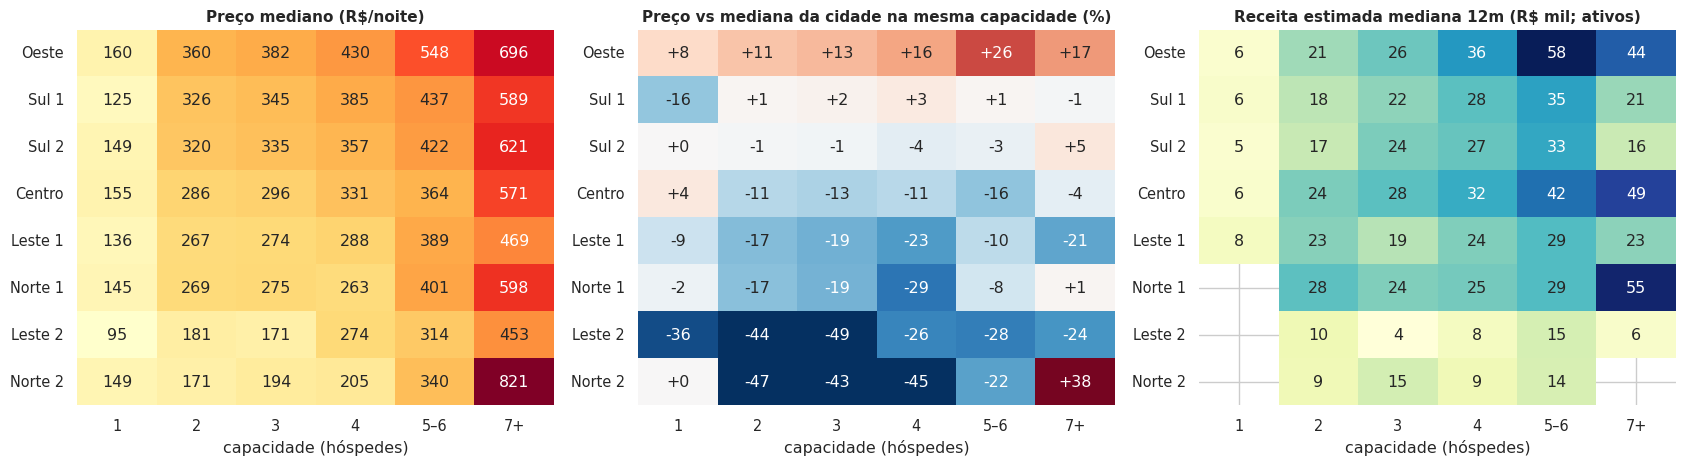

In [33]:
ACC_ORDER = ["1", "2", "3", "4", "5–6", "7+"]
row_order = list(dfp.groupby("regiao8")["price"].median().sort_values(ascending=False).index)


def seg_pivot(frame, value, min_n=20):
    p_ = frame.pivot_table(index="regiao8", columns="acc_b", values=value, aggfunc="median").reindex(index=row_order, columns=ACC_ORDER)
    n_ = frame.pivot_table(index="regiao8", columns="acc_b", values=value, aggfunc="size").reindex(index=row_order, columns=ACC_ORDER)
    return p_.where(n_ >= min_n)


p_abs = seg_pivot(dfp, "price")
city_med = dfp.groupby("acc_b")["price"].median().reindex(ACC_ORDER)
p_idx = (p_abs.div(city_med, axis=1) - 1) * 100
r_abs = seg_pivot(dfa, "estimated_revenue_l365d") / 1000
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(p_abs, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax[0], cbar=False); ax[0].set(title="Preço mediano (R$/noite)")
sns.heatmap(p_idx, annot=True, fmt="+.0f", cmap="RdBu_r", center=0, vmin=-40, vmax=40, ax=ax[1], cbar=False); ax[1].set(title="Preço vs mediana da cidade na mesma capacidade (%)")
sns.heatmap(r_abs, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax[2], cbar=False); ax[2].set(title="Receita estimada mediana 12m (R$ mil; ativos)")
for a in ax:
    a.set(xlabel="capacidade (hóspedes)", ylabel="")
fig.tight_layout()
savefig("16_heatmaps_regiao_capacidade")

**Leitura**
- O prêmio do **Oeste** é consistente em todas as capacidades (+8% a +26% sobre a mediana da cidade, com pico em 5–6 hóspedes). O **Centro** fica de 11% a 16% abaixo para 2 a 5 hóspedes e só supera a cidade em 1 hóspede (+4%). Sul 1 e Sul 2 ficam perto da média; Leste 2 e Norte 2 ficam muito abaixo (células com poucos anúncios).
- Nas seis maiores regiões, perfis de **5–6 hóspedes** têm receita estimada mediana de R\$ 29 a 58 mil (Oeste R\$ 58 mil; Centro R\$ 42 mil), contra R\$ 17 a 28 mil para 2 hóspedes. Atenção: no Oeste o preço sobe ×1,5 de 2 para 5–6 hóspedes, mas a receita sobe ×2,8 — logo a *ocupação estimada* também sobe, e ela vem de avaliações × mínimo de noites (seção 7). Vale conferir isso antes de concluir que perfis maiores rendem mais.

### 16.3 Dispersão dentro do distrito

IIQ/mediana DENTRO do distrito (mediana dos 65 distritos): 0.61 | ENTRE distritos (IIQ das medianas distritais / mediana): 0.25


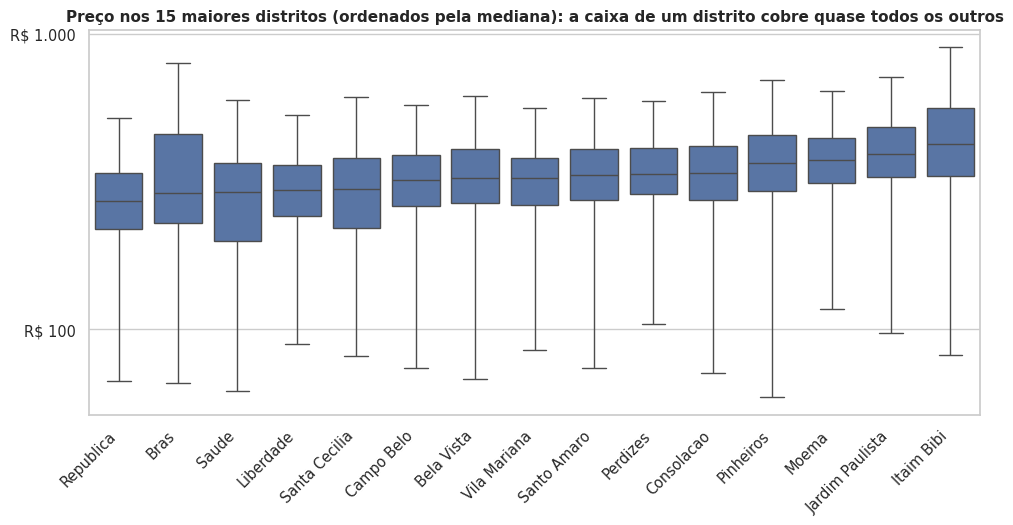

In [34]:
okn = dist.loc[~dist["amostra_baixa"]].index
gstat = dfp[dfp["distrito"].isin(okn)].groupby("distrito")["price"]
within = (gstat.quantile(.75) - gstat.quantile(.25)) / gstat.median()
dmed = gstat.median()
between = (dmed.quantile(.75) - dmed.quantile(.25)) / dmed.median()
print(f"IIQ/mediana DENTRO do distrito (mediana dos {len(okn)} distritos): {within.median():.2f} | ENTRE distritos (IIQ das medianas distritais / mediana): {between:.2f}")

top15 = dist.nlargest(15, "n_preco_ok").index
sub = dfp[dfp["distrito"].isin(top15)]
order_d = list(sub.groupby("distrito")["price"].median().sort_values().index)
fig, ax = plt.subplots(figsize=(11.5, 5))
sns.boxplot(data=sub, x="distrito", y="price", order=order_d, showfliers=False, color=C[0], ax=ax)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(BRL)
ax.set_xticks(range(len(order_d))); ax.set_xticklabels([lab(t) for t in order_d], rotation=45, ha="right")
ax.set(xlabel="", ylabel="", title="Preço nos 15 maiores distritos (ordenados pela mediana): a caixa de um distrito cobre quase todos os outros")
savefig("16_boxplot_top15_distritos")

**Leitura**
- **Dentro de um distrito o preço varia bem mais do que entre distritos**: o intervalo interquartil equivale a 61% da mediana do próprio distrito (mediana dos 65 distritos), contra 25% de dispersão entre as medianas distritais — cerca de 2,4× mais.
- No gráfico, a caixa de qualquer um dos 15 maiores distritos cobre boa parte das caixas dos outros. Escolher só o distrito não define o preço; o perfil do imóvel pesa tanto ou mais (seção 12).

## 17. Preço ajustado por perfil: quem é caro **para o mesmo produto**?
A mediana bruta mistura *composição* (mais casas grandes, mais quartos privados) com *preço*. O **índice ajustado** é a média do resíduo do log-preço depois de remover a média de cada perfil (`room_type × capacidade`): ele diz quanto o distrito cobra a mais/a menos que o esperado para o mesmo perfil.

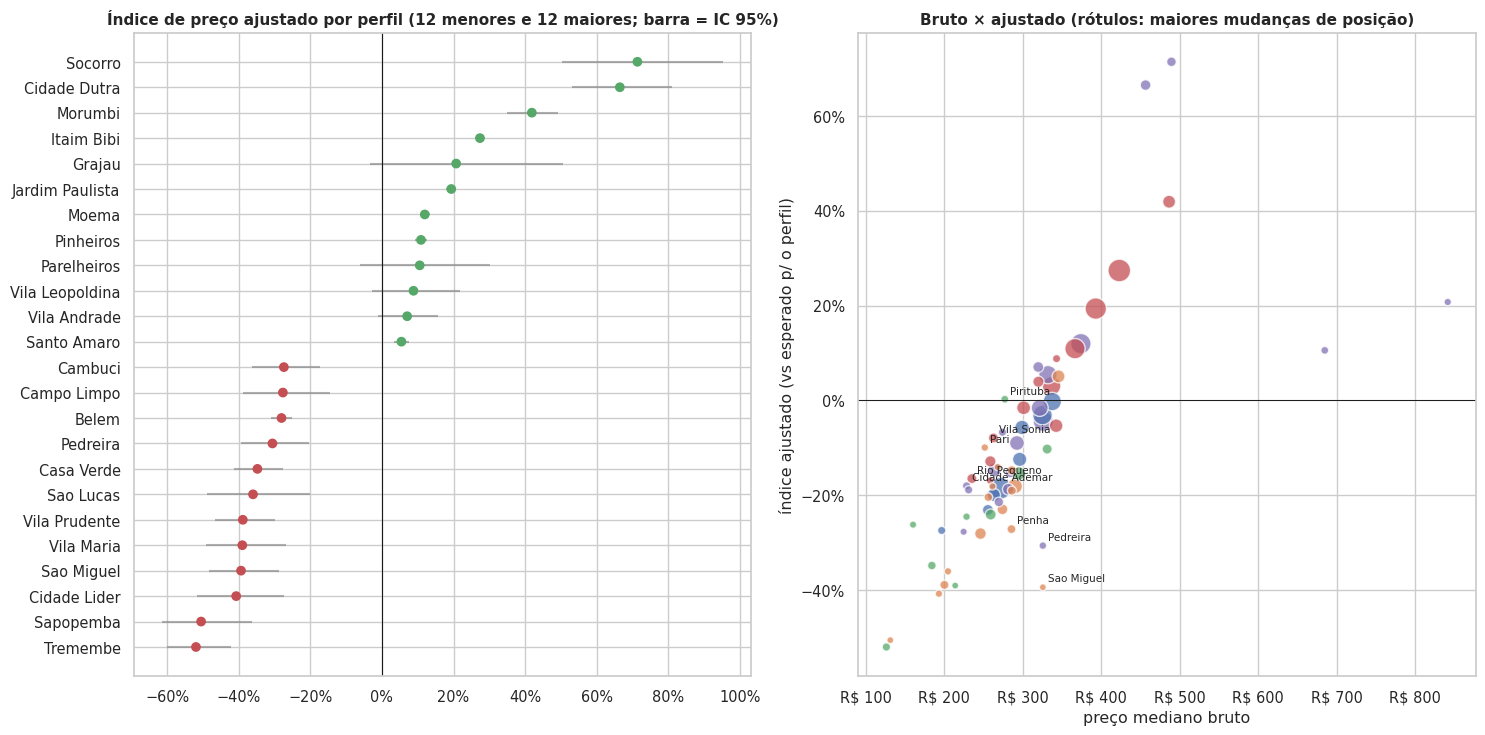

Spearman(mediana bruta, índice ajustado) = 0.83 (n = 65 distritos)
Sobem depois do ajuste (pareciam baratos por mix): Pari (50º → 27º), Pirituba (35º → 16º), Vila Sonia (43º → 25º), Cidade Ademar (54º → 38º), Lapa (46º → 30º)
Caem depois do ajuste (pareciam caros por mix):    Sao Miguel (18º → 62º), Pedreira (18º → 57º), Penha (32º → 53º), Vila Formosa (30º → 44º), Vila Guilherme (16º → 28º)
Maiores índices: Socorro +71%, Cidade Dutra +66%, Morumbi +42%, Itaim Bibi +27%, Grajau +21%
Menores índices: Tremembe -52%, Sapopemba -51%, Cidade Lider -41%, Sao Miguel -39%, Vila Maria -39%


In [35]:
def adjusted_price_index(frame, profile=("room_type", "acc_b")):
    """Preço relativo do distrito para o MESMO perfil (% acima/abaixo do esperado) com IC 95%."""
    f_ = frame.copy()
    f_["resid"] = f_["log_price"] - f_.groupby(list(profile), observed=True)["log_price"].transform("mean")
    g_ = f_.groupby("distrito")["resid"].agg(media="mean", dp="std", n="size")
    se = g_["dp"] / np.sqrt(g_["n"])
    return pd.DataFrame({"n": g_["n"], "indice": np.expm1(g_["media"]) * 100,
                         "ic_lo": np.expm1(g_["media"] - 1.96 * se) * 100, "ic_hi": np.expm1(g_["media"] + 1.96 * se) * 100})


pidx = adjusted_price_index(dfp)
dist["indice_preco_aj"] = pidx["indice"]
okd = dist[~dist["amostra_baixa"]].copy()
okd["rank_bruto"] = okd["preco_mediano"].rank(ascending=False)
okd["rank_ajust"] = okd["indice_preco_aj"].rank(ascending=False)
okd["delta_rank"] = okd["rank_bruto"] - okd["rank_ajust"]            # > 0: sobe no ranking depois do ajuste

ext = pd.concat([okd.nsmallest(12, "indice_preco_aj"), okd.nlargest(12, "indice_preco_aj")]).sort_values("indice_preco_aj")
ci = pidx.loc[ext.index]
pos = np.arange(len(ext))
fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
ax[0].errorbar(ci["indice"], pos, xerr=[ci["indice"] - ci["ic_lo"], ci["ic_hi"] - ci["indice"]], fmt="none", ecolor="gray", alpha=.6)
ax[0].scatter(ci["indice"], pos, c=[C[3] if v < 0 else C[2] for v in ci["indice"]], zorder=3)
ax[0].set_yticks(pos); ax[0].set_yticklabels([lab(i) for i in ext.index]); ax[0].axvline(0, color="k", lw=.8)
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax[0].set(title="Índice de preço ajustado por perfil (12 menores e 12 maiores; barra = IC 95%)")
ax[1].scatter(okd["preco_mediano"], okd["indice_preco_aj"], s=np.sqrt(okd["n_anuncios"]) * 4, c=okd["regiao5"].map(reg_colors), alpha=.75, edgecolor="w")
ax[1].axhline(0, color="k", lw=.7)
for i, r_ in okd.reindex(okd["delta_rank"].abs().sort_values(ascending=False).index).head(8).iterrows():
    ax[1].annotate(lab(i), (r_["preco_mediano"], r_["indice_preco_aj"]), fontsize=7.5, xytext=(4, 4), textcoords="offset points")
ax[1].xaxis.set_major_formatter(BRL); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax[1].set(xlabel="preço mediano bruto", ylabel="índice ajustado (vs esperado p/ o perfil)", title="Bruto × ajustado (rótulos: maiores mudanças de posição)")
fig.tight_layout()
savefig("17_indice_preco_ajustado")

print(f"Spearman(mediana bruta, índice ajustado) = {stats.spearmanr(okd['preco_mediano'], okd['indice_preco_aj'])[0]:.2f} (n = {len(okd)} distritos)")
show = lambda d_: ", ".join(f"{lab(i)} ({r_['rank_bruto']:.0f}º → {r_['rank_ajust']:.0f}º)" for i, r_ in d_.iterrows())
print("Sobem depois do ajuste (pareciam baratos por mix):", show(okd.nlargest(5, "delta_rank")))
print("Caem depois do ajuste (pareciam caros por mix):   ", show(okd.nsmallest(5, "delta_rank")))
print("Maiores índices:", ", ".join(f"{lab(i)} {v:+.0f}%" for i, v in okd["indice_preco_aj"].nlargest(5).items()))
print("Menores índices:", ", ".join(f"{lab(i)} {v:+.0f}%" for i, v in okd["indice_preco_aj"].nsmallest(5).items()))

**Leitura**
- O ranking bruto e o ajustado se parecem (ρ = 0,83), mas **composição engana**: São Miguel e Pedreira ocupam o 18º lugar pela mediana bruta e caem para 62º e 57º quando comparados ao mesmo perfil (mix de imóveis grandes); já Pari, Pirituba, Vila Sônia e Lapa sobem de 16 a 23 posições.
- O prêmio do eixo **Oeste/Sudoeste é robusto e bem estimado** nos distritos grandes: Morumbi +42%, Itaim Bibi +27%, Jardim Paulista +20%, Moema +12% e Pinheiros +11%, todos com intervalo de confiança estreito. No outro extremo estão Tremembé (−52%), Sapopemba (−51%), Cidade Líder, São Miguel e Vila Maria (−39% a −41%).
- Os maiores índices — Socorro (+71%) e Cidade Dutra (+66%) — têm amostra pequena (143 e 214 anúncios) e Grajaú e Parelheiros têm IC que inclui zero. A próxima célula investiga esses casos.

### 17.1 Por que alguns distritos têm índice tão alto? Mix e robustez
Conferimos o mix de imóveis dos 5 maiores índices e se o prêmio sobrevive quando só entram cotações de **até 14 dias** (descarta efeito de datas de evento/alta temporada).

In [36]:
top_idx = list(okd.nlargest(5, "indice_preco_aj").index)
robust = adjusted_price_index(dfp[dfp["quote_lead_days"] <= 14])
mix_rows = {}
for d_ in top_idx + [None]:
    s_ = df if d_ is None else df[df["distrito"] == d_]
    mix_rows["Cidade (todos)" if d_ is None else lab(d_)] = {
        "anúncios": len(s_), "casas_%": s_["property_type"].eq("Entire home").mean() * 100, "aptos_%": s_["property_type"].eq("Entire rental unit").mean() * 100,
        "capacidade_med": s_["accommodates"].median(), "piscina_%": A.loc[s_.index, "Pool"].mean() * 100, "preço_med": s_["price"].median()}
mix_tbl = pd.DataFrame(mix_rows).T
mix_tbl["índice (todas as cotações)"] = [okd.loc[d_, "indice_preco_aj"] for d_ in top_idx] + [np.nan]
mix_tbl["índice (cotações ≤ 14 dias)"] = [robust.loc[d_, "indice"] for d_ in top_idx] + [np.nan]
display(mix_tbl.round(1))

,anúncios,casas_%,aptos_%,capacidade_med,piscina_%,preço_med,índice (todas as cotações),índice (cotações ≤ 14 dias)
Socorro,143.00,18.90,14.00,2.00,21.00,514.00,71.40,74.90
Cidade Dutra,214.00,22.00,23.80,4.00,2.30,467.00,66.50,68.50
Morumbi,467.00,9.20,60.20,3.00,50.50,533.80,41.90,41.30
Itaim Bibi,"4,382.00",1.00,77.00,2.00,42.90,423.40,27.40,26.50
Grajau,50.00,48.00,6.00,13.50,46.00,858.90,20.70,21.80
Cidade (todos),"42,354.00",4.00,71.90,2.00,31.90,331.00,NaN,NaN


**Leitura**
- **Grajaú** é um mercado de casas grandes: 48% de casas (contra 4% na cidade), mediana de 13,5 hóspedes e 46% com piscina. O prêmio vem do mix de produto (e a amostra é pequena: 50 anúncios).
- **Socorro e Cidade Dutra não se explicam pelo mix** (casas em 19–22% dos anúncios; capacidade mediana de 2 a 4 hóspedes) **nem por datas de evento**: o índice se mantém (+75% e +68,5%) quando só entram cotações de até 14 dias. Vale inspecionar esses anúncios (tipo de produto, localização exata) antes de tratá-los como oportunidade ou como outlier.

## 18. Preço × ocupação × receita por distrito
Como `receita = preço × ocupação`, as curvas pontilhadas são **iso-receita**: pontos sobre a mesma curva têm a mesma receita estimada.

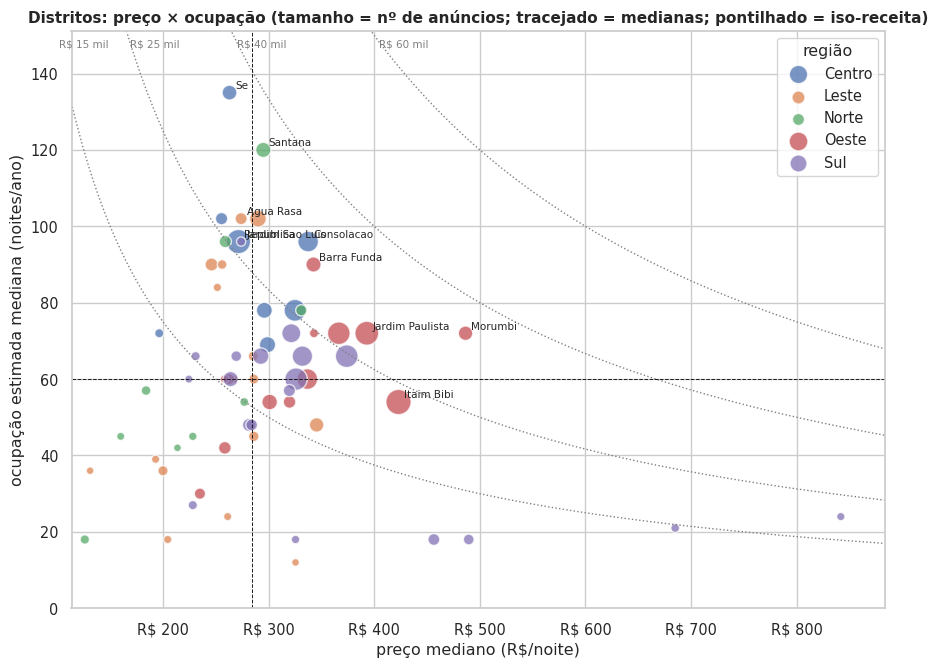

Variância do log-receita — anúncios ativos       :   11% vem do PREÇO |   89% vem da OCUPAÇÃO
Variância do log-receita — distritos (medianas)  :   20% vem do PREÇO |   78% vem da OCUPAÇÃO
Spearman(preço, ocupação): anúncios ativos = -0.14 | distritos = +0.09
Maiores receitas medianas: Se (R$ 36.7 mil; preço 263; 135 noites), Morumbi (R$ 36.3 mil; preço 486; 72 noites), Agua Rasa (R$ 33.1 mil; preço 274; 102 noites), Santana (R$ 31.8 mil; preço 295; 120 noites), Consolacao (R$ 31.4 mil; preço 337; 96 noites)
Maiores praças: Itaim Bibi: preço 423, 54 noites, receita R$ 23.4 mil | Republica: preço 272, 96 noites, receita R$ 26.4 mil | Jardim Paulista: preço 393, 72 noites, receita R$ 28.6 mil
Mediana dos distritos: preço 284 | ocupação 60 noites | receita R$ 17.9 mil


In [37]:
q = okd.dropna(subset=["preco_mediano", "ocup_mediana", "receita_mediana"]).copy()
fig, ax = plt.subplots(figsize=(10.5, 7.5))
for reg, gg in q.groupby("regiao5"):
    ax.scatter(gg["preco_mediano"], gg["ocup_mediana"], s=np.sqrt(gg["n_anuncios"]) * 5, color=reg_colors[reg], alpha=.75, edgecolor="w", label=reg)
px = np.linspace(q["preco_mediano"].min() * .9, q["preco_mediano"].max() * 1.05, 300)
ymax = q["ocup_mediana"].max() * 1.12
for R_ in (15_000, 25_000, 40_000, 60_000):
    ax.plot(px, R_ / px, ls=":", color="gray", lw=1)
    xr = R_ / ymax
    ax.text(xr * 1.02, ymax * .985, f"R$ {R_ // 1000} mil", fontsize=7.5, color="gray", va="top")
ax.axvline(q["preco_mediano"].median(), color="k", lw=.7, ls="--"); ax.axhline(q["ocup_mediana"].median(), color="k", lw=.7, ls="--")
for i in set(q.nlargest(7, "receita_mediana").index) | set(q.nlargest(3, "n_anuncios").index):
    ax.annotate(lab(i), (q.loc[i, "preco_mediano"], q.loc[i, "ocup_mediana"]), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.set(xlim=(px[0], px[-1]), ylim=(0, ymax), xlabel="preço mediano (R$/noite)", ylabel="ocupação estimada mediana (noites/ano)",
       title="Distritos: preço × ocupação (tamanho = nº de anúncios; tracejado = medianas; pontilhado = iso-receita)")
ax.xaxis.set_major_formatter(BRL); ax.legend(title="região", loc="upper right")
savefig("18_quadrante_preco_ocupacao")

la = np.log(dfa[["price", "estimated_occupancy_l365d", "estimated_revenue_l365d"]])
lq = np.log(q[["preco_mediano", "ocup_mediana", "receita_mediana"]])
for nm, fr, (cp, co, cr) in [("anúncios ativos", la, ("price", "estimated_occupancy_l365d", "estimated_revenue_l365d")), ("distritos (medianas)", lq, ("preco_mediano", "ocup_mediana", "receita_mediana"))]:
    v = fr[cr].var()
    print(f"Variância do log-receita — {nm:22s}: {fr[cr].cov(fr[cp]) / v:5.0%} vem do PREÇO | {fr[cr].cov(fr[co]) / v:5.0%} vem da OCUPAÇÃO")
print(f"Spearman(preço, ocupação): anúncios ativos = {stats.spearmanr(dfa['price'], dfa['estimated_occupancy_l365d'])[0]:+.2f} | distritos = {stats.spearmanr(q['preco_mediano'], q['ocup_mediana'])[0]:+.2f}")
print("Maiores receitas medianas:", ", ".join(f"{lab(i)} (R$ {r_['receita_mediana'] / 1000:.1f} mil; preço {r_['preco_mediano']:.0f}; {r_['ocup_mediana']:.0f} noites)" for i, r_ in q.nlargest(5, "receita_mediana").iterrows()))
print("Maiores praças:", " | ".join(f"{lab(i)}: preço {r_['preco_mediano']:.0f}, {r_['ocup_mediana']:.0f} noites, receita R$ {r_['receita_mediana'] / 1000:.1f} mil" for i, r_ in q.nlargest(3, "n_anuncios").iterrows()))
print(f"Mediana dos distritos: preço {q['preco_mediano'].median():.0f} | ocupação {q['ocup_mediana'].median():.0f} noites | receita R$ {q['receita_mediana'].median() / 1000:.1f} mil")

**Leitura**
- **A receita estimada é, na prática, um ranking de avaliações**: 89% da variância do log-receita entre anúncios ativos vem da ocupação estimada e só 11% do preço (78% × 20% entre distritos). Preço e ocupação são praticamente independentes entre distritos (ρ = +0,09).
- Há dois caminhos para uma receita alta: **Sé** (R\$ 36,7 mil; preço R\$ 263 e 135 noites) e **Santana** (R\$ 31,8 mil; R\$ 295 e 120 noites) ganham por volume; **Morumbi** (R\$ 36,3 mil) ganha por preço (R\$ 486 com 72 noites).
- **Itaim Bibi**, a maior praça, cobra R\$ 423 mas tem só 54 noites estimadas (a mediana dos distritos é 60): receita de R\$ 23,4 mil, abaixo de República (R\$ 26,4 mil) e Jardim Paulista (R\$ 28,6 mil). Preço alto sozinho não garante receita.

## 19. Gradiente urbano e direção
Distância (em linha reta) até a Praça da Sé (`CITY_CENTER`) e setor de 45° em relação a ela.

dist_bucket,0–2,2–4,4–6,6–8,8–10,10–15,15+
anuncios_%,17.90,19.10,19.90,20.60,9.00,10.70,2.70
ativos_%,82.70,79.40,83.30,79.80,76.80,74.70,55.00
host_5mais_%,51.80,56.10,56.70,60.10,52.80,46.10,25.30
preco_p25,228.00,284.60,276.80,292.30,239.00,229.00,210.60
preco_mediano,284.20,351.00,342.50,367.00,321.00,313.00,350.90
preco_p75,354.00,440.00,432.00,457.00,414.00,411.00,685.00
ocup_mediana,96.00,78.00,72.00,60.00,60.00,60.00,24.00
receita_mediana,"26,190.00","25,658.00","23,185.50","22,544.00","19,708.50","18,077.00","10,170.00"


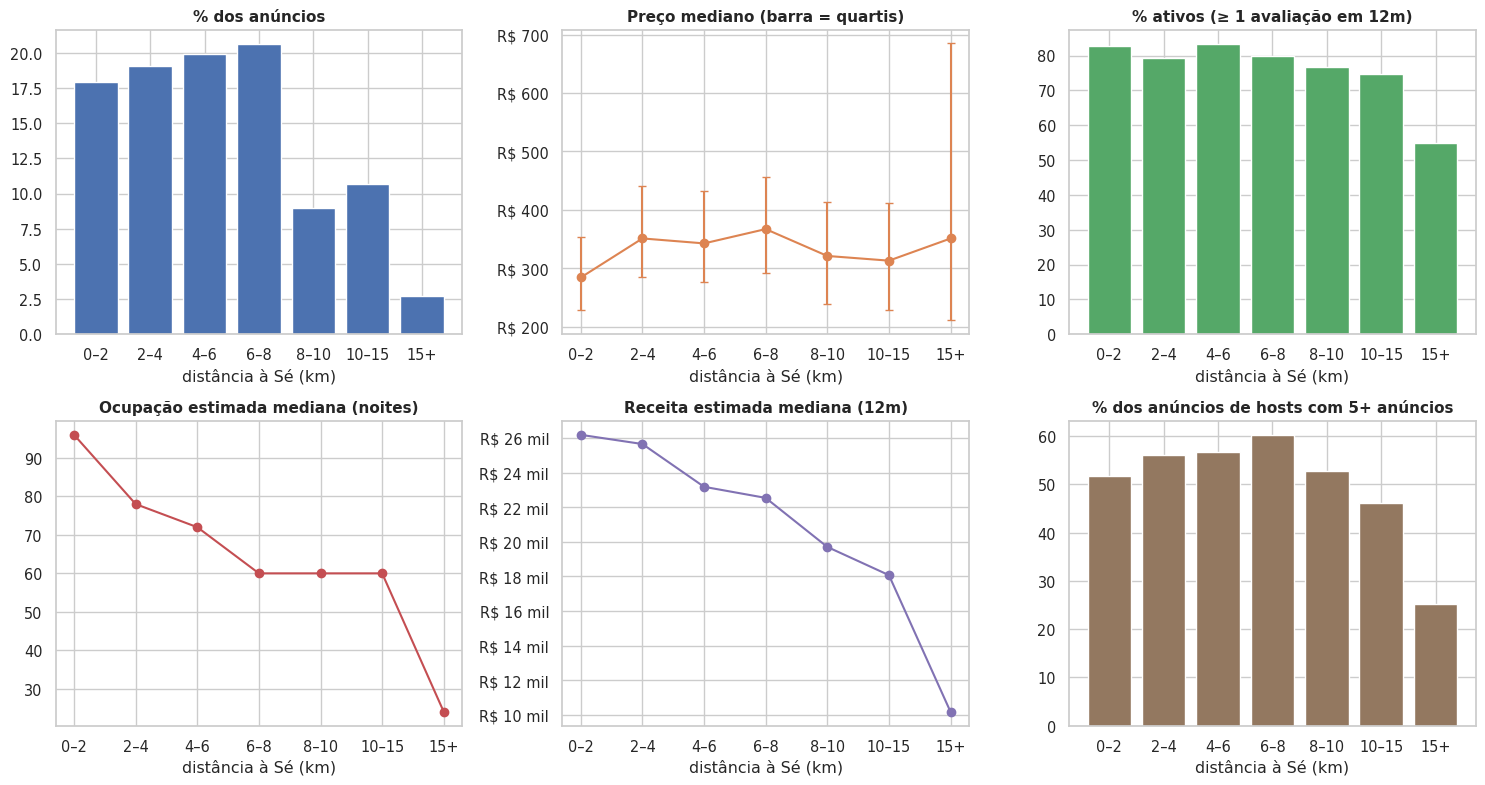

Spearman(preço, distância à Sé) = +0.08 | Spearman(ocupação est., distância) = -0.13


In [38]:
gb_all = df.groupby("dist_bucket", observed=True)
gb_p = dfp.groupby("dist_bucket", observed=True)["price"]
gb_a = dfa.groupby("dist_bucket", observed=True)
grad = pd.DataFrame({
    "anuncios_%": gb_all.size() / len(df) * 100,
    "ativos_%": gb_all["active_ltm"].mean() * 100,
    "host_5mais_%": gb_all["calculated_host_listings_count"].apply(lambda s: (s >= 5).mean() * 100),
    "preco_p25": gb_p.quantile(.25), "preco_mediano": gb_p.median(), "preco_p75": gb_p.quantile(.75),
    "ocup_mediana": gb_a["estimated_occupancy_l365d"].median(), "receita_mediana": gb_a["estimated_revenue_l365d"].median(),
})
display(grad.round(1).T)
xg = np.arange(len(grad))
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].bar(xg, grad["anuncios_%"], color=C[0]); ax[0, 0].set(title="% dos anúncios")
ax[0, 1].errorbar(xg, grad["preco_mediano"], yerr=[grad["preco_mediano"] - grad["preco_p25"], grad["preco_p75"] - grad["preco_mediano"]], fmt="o-", color=C[1], capsize=3)
ax[0, 1].yaxis.set_major_formatter(BRL); ax[0, 1].set(title="Preço mediano (barra = quartis)")
ax[0, 2].bar(xg, grad["ativos_%"], color=C[2]); ax[0, 2].set(title="% ativos (≥ 1 avaliação em 12m)")
ax[1, 0].plot(xg, grad["ocup_mediana"], "o-", color=C[3]); ax[1, 0].set(title="Ocupação estimada mediana (noites)")
ax[1, 1].plot(xg, grad["receita_mediana"], "o-", color=C[4]); ax[1, 1].yaxis.set_major_formatter(BRL_SHORT); ax[1, 1].set(title="Receita estimada mediana (12m)")
ax[1, 2].bar(xg, grad["host_5mais_%"], color=C[5]); ax[1, 2].set(title="% dos anúncios de hosts com 5+ anúncios")
for a in ax.ravel():
    a.set_xticks(xg); a.set_xticklabels(grad.index); a.set_xlabel("distância à Sé (km)")
fig.tight_layout()
savefig("19_gradiente_distancia")
print(f"Spearman(preço, distância à Sé) = {dfp[['price', 'dist_centro_km']].corr('spearman').iloc[0, 1]:+.2f} | Spearman(ocupação est., distância) = {dfa[['estimated_occupancy_l365d', 'dist_centro_km']].corr('spearman').iloc[0, 1]:+.2f}")

**Leitura**
- **A demanda cai com a distância, o preço não**: da faixa 0–2 km até 15+ km, a ocupação estimada mediana vai de 96 para 24 noites, a receita estimada de R\$ 26 mil para R\$ 10 mil e o % de ativos de 83% para 55%. O preço mediano, ao contrário, **sobe** de R\$ 284 (0–2 km) para R\$ 343–367 na faixa de 2 a 8 km e depois se estabiliza (ρ preço × distância = +0,08).
- A oferta se concentra até 8 km (77% dos anúncios), e a profissionalização também: hosts com 5+ anúncios respondem por 52–60% dos anúncios até 10 km e por só 25% acima de 15 km.

setor,N,NE,L,SE,S,SO,O,NO
anuncios,"1,939.00",615.00,"2,209.00",678.00,"5,685.00","14,277.00","11,207.00","4,594.00"
preco_mediano,279.00,282.00,297.00,235.00,308.00,374.00,340.00,304.00
ocup_mediana,114.00,78.00,78.00,48.00,66.00,66.00,72.00,78.00
receita_mediana,"29,764.00","22,202.00","23,847.00","12,792.00","17,976.00","24,300.00","24,480.00","23,678.00"


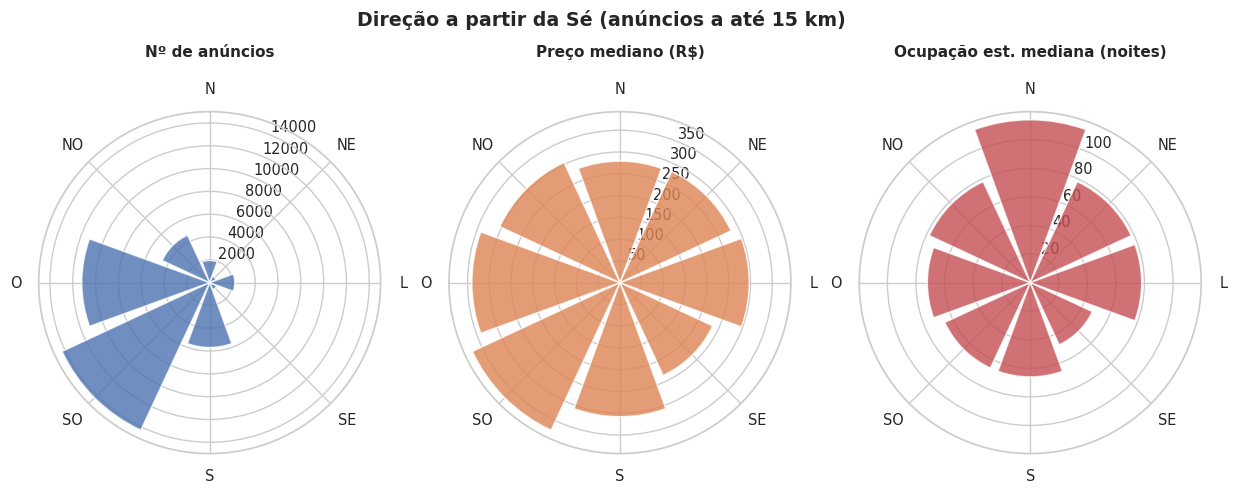

In [39]:
R_MAX = 15
sec = pd.DataFrame({
    "anuncios": df[df["dist_centro_km"] <= R_MAX].groupby("setor", observed=True).size(),
    "preco_mediano": dfp[dfp["dist_centro_km"] <= R_MAX].groupby("setor", observed=True)["price"].median(),
    "ocup_mediana": dfa[dfa["dist_centro_km"] <= R_MAX].groupby("setor", observed=True)["estimated_occupancy_l365d"].median(),
    "receita_mediana": dfa[dfa["dist_centro_km"] <= R_MAX].groupby("setor", observed=True)["estimated_revenue_l365d"].median(),
}).reindex(SECTORS)
display(sec.round(0).T)
theta = np.deg2rad(np.arange(0, 360, 45))
fig, axes = plt.subplots(1, 3, subplot_kw={"projection": "polar"}, figsize=(15, 5.2))
for ax, (ttl, col, cl) in zip(axes, [("Nº de anúncios", "anuncios", C[0]), ("Preço mediano (R$)", "preco_mediano", C[1]), ("Ocupação est. mediana (noites)", "ocup_mediana", C[3])]):
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.bar(theta, sec[col].values, width=np.deg2rad(40), color=cl, alpha=.8)
    ax.set_xticks(theta); ax.set_xticklabels(SECTORS); ax.set_title(ttl, pad=18)
fig.suptitle(f"Direção a partir da Sé (anúncios a até {R_MAX} km)", y=1.02, fontweight="bold")
savefig("19_setores_polar")

**Leitura**
- O **Sudoeste** concentra a oferta (14,3 mil anúncios a até 15 km da Sé) e tem o maior preço mediano (R\$ 374); o **Oeste** vem em seguida (11,2 mil; R\$ 340). O **Norte** tem pouca oferta (1,9 mil), mas a maior ocupação e receita estimadas (114 noites; R\$ 29,8 mil) — Santana aparece entre as maiores receitas distritais (seção 18). O **Sudeste** é o setor mais fraco (R\$ 235; 48 noites; R\$ 12,8 mil).

## 20. Geografia dos distritos: mapas de bolhas e autocorrelação espacial
Sem polígonos, cada distrito é um ponto (mediana das coordenadas dos seus anúncios). A autocorrelação (Moran global e local/LISA) usa os `K_NEIGHBORS` vizinhos mais próximos por centroide, com teste por permutação. Para usar contiguidade de polígonos, troque `knn_weights` por pesos Queen do `libpysal`.

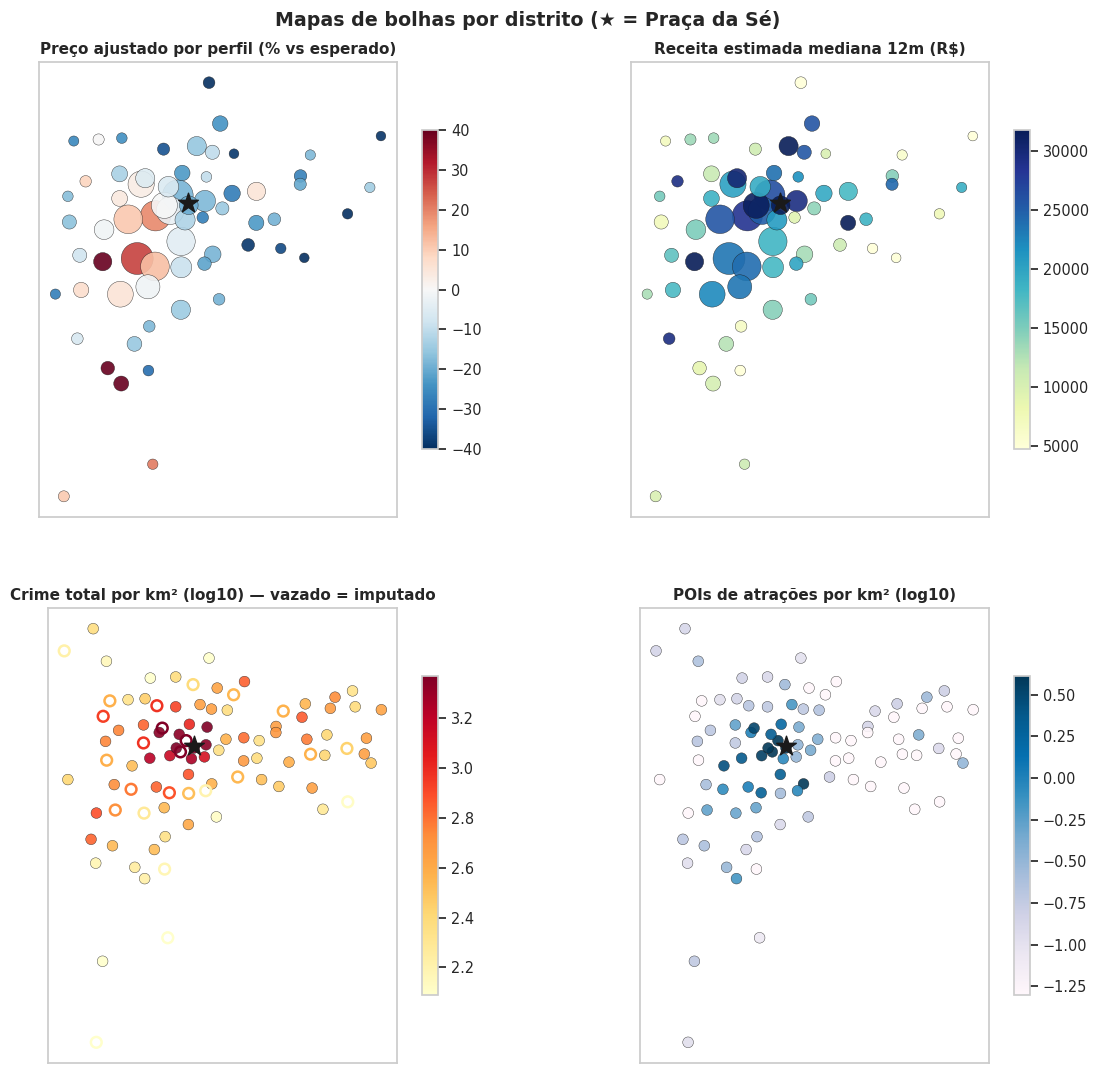

In [40]:
asp = 1 / np.cos(np.deg2rad(df["latitude"].mean()))
allc = dist.dropna(subset=["lat_c", "lon_c"])
MAPS = [
    ("indice_preco_aj", okd, "Preço ajustado por perfil (% vs esperado)", "RdBu_r", lambda s: s, (-40, 40), True),
    ("receita_mediana", okd, "Receita estimada mediana 12m (R$)", "YlGnBu", lambda s: s, None, True),
    ("crime_total_km2", allc, "Crime total por km² (log10) — vazado = imputado", "YlOrRd", np.log10, None, False),
    ("poidens_atracoes", allc, "POIs de atrações por km² (log10)", "PuBu", lambda s: np.log10(s + .05), None, False),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for ax, (col, frame, ttl, cmap, tf, lim, size_by) in zip(axes.ravel(), MAPS):
    val = tf(frame[col])
    lo, hi = lim if lim else (val.quantile(.05), val.quantile(.95))
    norm = mcolors.Normalize(lo, hi)
    sz = np.sqrt(frame["n_anuncios"]) * 8 if size_by else pd.Series(60, index=frame.index)
    imp = (frame["crime_source"] == "nearest-imputed") if col == "crime_total_km2" else pd.Series(False, index=frame.index)
    ax.scatter(frame.loc[~imp, "lon_c"], frame.loc[~imp, "lat_c"], c=val[~imp], cmap=cmap, norm=norm, s=sz[~imp], edgecolor="k", linewidth=.3, alpha=.9)
    if imp.any():
        ax.scatter(frame.loc[imp, "lon_c"], frame.loc[imp, "lat_c"], facecolors="none", edgecolors=[plt.get_cmap(cmap)(norm(v)) for v in val[imp]], s=sz[imp], linewidth=1.8)
    ax.scatter(CITY_CENTER[1], CITY_CENTER[0], marker="*", s=220, color="k", zorder=5)
    ax.set_aspect(asp); ax.set(title=ttl, xticks=[], yticks=[])
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=.7)
fig.suptitle("Mapas de bolhas por distrito (★ = Praça da Sé)", y=.92, fontweight="bold")
savefig("20_mapas_bolhas_distritos")

,distritos,Moran I,esperado,p (bicaudal)
variável,,,,
Índice de preço ajustado,65,0.31,-0.016,0.001
Preço mediano,65,0.27,-0.016,0.001
Ocupação est. mediana,65,0.31,-0.016,0.001
Receita est. mediana,65,0.17,-0.016,0.016
% ativos 12m,65,0.34,-0.016,0.001
Crime total/km² (log1p) — 96 distritos,96,0.57,-0.011,0.001
POI atrações/km² (log1p) — 96 distritos,96,0.56,-0.011,0.001
IPTU valor/m² — 96 distritos,96,0.70,-0.011,0.001


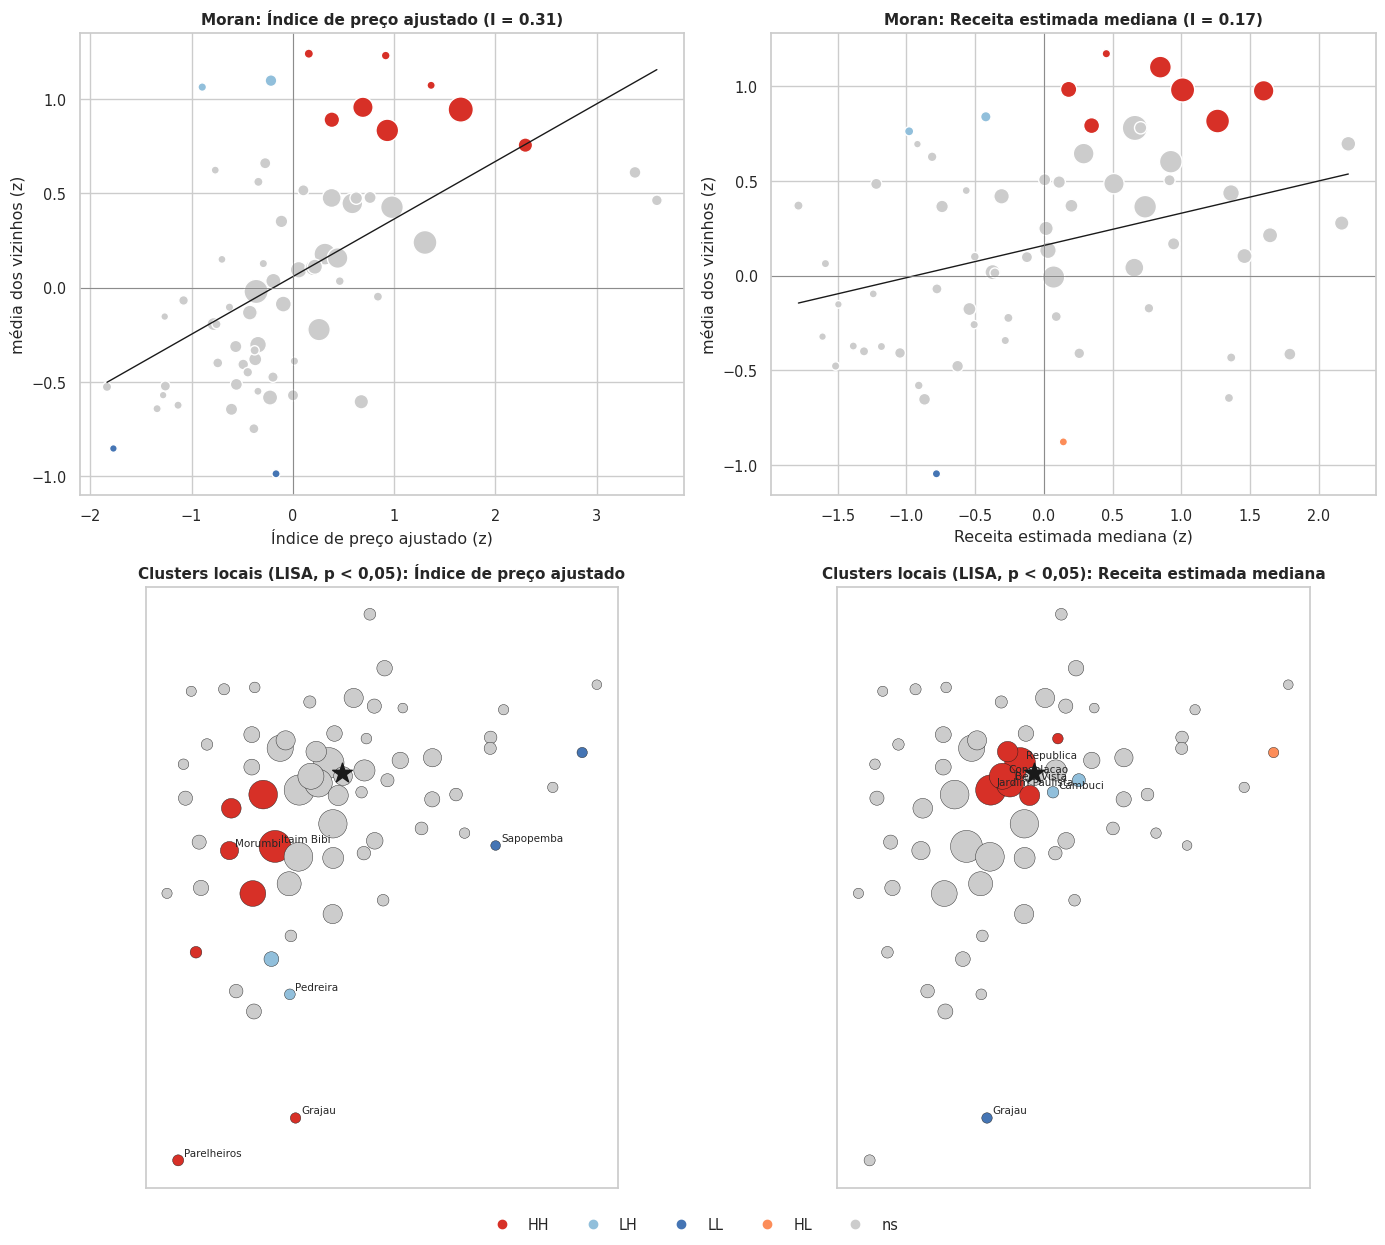

LISA indice_preco_aj: {'ns': 53, 'HH': 8, 'LH': 2, 'LL': 2} | HH: Itaim Bibi, Pinheiros, Santo Amaro, Butanta, Morumbi, Jardim Sao Luis, Parelheiros, Grajau | LL: Itaquera, Sapopemba
LISA receita_mediana: {'ns': 54, 'HH': 7, 'LH': 2, 'LL': 1, 'HL': 1} | HH: Republica, Jardim Paulista, Bela Vista, Consolacao, Santa Cecilia, Liberdade, Pari | LL: Grajau


In [41]:
def to_km(lat, lon):
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    return np.column_stack([(lon - lon.mean()) * np.cos(np.radians(lat.mean())) * 111.32, (lat - lat.mean()) * 110.57])


def knn_weights(xy, k=K_NEIGHBORS):
    """Pesos binários dos k vizinhos mais próximos (por centroide), padronizados por linha."""
    d_ = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2)
    np.fill_diagonal(d_, np.inf)
    idx = np.argsort(d_, axis=1)[:, :k]
    W = np.zeros((len(xy), len(xy)))
    np.put_along_axis(W, idx, 1.0 / k, axis=1)
    return W, idx


def moran_global(x, W, n_perm=N_PERM, seed=SEED):
    z = (x - x.mean()) / x.std()
    stat = lambda v: float((v * (W @ v)).sum() / (v ** 2).sum())
    i_obs = stat(z)
    rng = np.random.default_rng(seed)
    sims = np.array([stat(rng.permutation(z)) for _ in range(n_perm)])
    return i_obs, (1 + int((np.abs(sims) >= abs(i_obs)).sum())) / (n_perm + 1), -1 / (len(x) - 1)


def moran_local(x, W, idx, n_perm=N_PERM, seed=SEED):
    """Moran local (LISA) com permutação condicional: p-valor bicaudal e quadrante (HH, LH, LL, HL)."""
    z = (x - x.mean()) / x.std()
    lag = W @ z
    li = z * lag
    rng = np.random.default_rng(seed)
    n, k = idx.shape
    p_ = np.empty(n)
    for i in range(n):
        others = np.delete(z, i)
        pick = rng.random((n_perm, n - 1)).argsort(axis=1)[:, :k]
        p_[i] = (1 + int((np.abs(z[i] * others[pick].mean(axis=1)) >= abs(li[i])).sum())) / (n_perm + 1)
    quad = np.select([(z > 0) & (lag > 0), (z < 0) & (lag > 0), (z < 0) & (lag < 0), (z > 0) & (lag < 0)], ["HH", "LH", "LL", "HL"], "")
    return z, lag, li, p_, quad


def prep(frame, col, transform=None):
    s = frame.dropna(subset=[col, "lat_c", "lon_c"]).copy()
    vals = s[col].astype(float).values
    if transform is not None:
        vals = transform(vals)
    W, idx = knn_weights(to_km(s["lat_c"], s["lon_c"]))
    return s, vals, W, idx


moran_rows = []
for col, nm, frame, tf in [("indice_preco_aj", "Índice de preço ajustado", okd, None), ("preco_mediano", "Preço mediano", okd, None),
                           ("ocup_mediana", "Ocupação est. mediana", okd, None), ("receita_mediana", "Receita est. mediana", okd, None),
                           ("pct_ativos", "% ativos 12m", okd, None), ("crime_total_km2", "Crime total/km² (log1p) — 96 distritos", dist, np.log1p),
                           ("poidens_atracoes", "POI atrações/km² (log1p) — 96 distritos", dist, np.log1p), ("iptu_venal_m2_median", "IPTU valor/m² — 96 distritos", dist, None)]:
    s_, vals, W, idx = prep(frame, col, tf)
    i_, p_, e_ = moran_global(vals, W)
    moran_rows.append({"variável": nm, "distritos": len(s_), "Moran I": i_, "esperado": e_, "p (bicaudal)": p_})
moran_tbl = pd.DataFrame(moran_rows).set_index("variável")
display(moran_tbl.assign(**{"Moran I": moran_tbl["Moran I"].map("{:.2f}".format), "esperado": moran_tbl["esperado"].map("{:.3f}".format),
                           "p (bicaudal)": moran_tbl["p (bicaudal)"].map("{:.3f}".format)}))

QCOL = {"HH": "#d73027", "LH": "#91bfdb", "LL": "#4575b4", "HL": "#fc8d59", "ns": "#cccccc"}
fig, axes = plt.subplots(2, 2, figsize=(14, 12.5), gridspec_kw={"height_ratios": [1, 1.3]})
lisa_out = {}
for j, (col, nm) in enumerate([("indice_preco_aj", "Índice de preço ajustado"), ("receita_mediana", "Receita estimada mediana")]):
    s_, vals, W, idx = prep(okd, col)
    z, lag, li, p_, quad = moran_local(vals, W, idx)
    cat = np.where(p_ < .05, quad, "ns")
    lisa_out[col] = pd.Series(cat, index=s_.index)
    cols_ = [QCOL[c] for c in cat]
    a0, a1 = axes[0, j], axes[1, j]
    a0.scatter(z, lag, c=cols_, s=np.sqrt(s_["n_anuncios"]) * 5, edgecolor="w")
    i_glob = moran_global(vals, W)[0]
    slope = np.polyfit(z, lag, 1)
    xs = np.array([z.min(), z.max()]); a0.plot(xs, np.polyval(slope, xs), color="k", lw=1)
    a0.axhline(0, color="gray", lw=.6); a0.axvline(0, color="gray", lw=.6)
    a0.set(xlabel=f"{nm} (z)", ylabel="média dos vizinhos (z)", title=f"Moran: {nm} (I = {i_glob:.2f})")
    a1.scatter(s_["lon_c"], s_["lat_c"], c=cols_, s=np.sqrt(s_["n_anuncios"]) * 8, edgecolor="k", linewidth=.3)
    a1.scatter(CITY_CENTER[1], CITY_CENTER[0], marker="*", s=220, color="k", zorder=5)
    for i in np.argsort(-np.abs(li))[:10]:
        if cat[i] != "ns":
            a1.annotate(lab(s_.index[i]), (s_["lon_c"].iloc[i], s_["lat_c"].iloc[i]), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
    a1.set_aspect(asp); a1.set(xticks=[], yticks=[], title=f"Clusters locais (LISA, p < 0,05): {nm}")
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in QCOL.items()], loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, .03, 1, 1))
savefig("20_moran_lisa")
for col, ser in lisa_out.items():
    print(f"LISA {col}: {ser.value_counts().to_dict()} | HH: {', '.join(lab(i) for i in ser[ser == 'HH'].index)} | LL: {', '.join(lab(i) for i in ser[ser == 'LL'].index)}")

**Leitura**
- **Vizinhos se parecem**: o Moran global é moderado para os resultados dos anúncios (índice de preço ajustado 0,31; ocupação 0,31; % ativos 0,34; receita 0,17) e **bem maior para as features exógenas** (crime/km² 0,57; POIs de atração 0,56; IPTU 0,70, em 96 distritos). Boa parte da estrutura espacial está no "tecido urbano", não nos preços.
- **Os hotspots de preço e de receita não coincidem**: o preço ajustado forma um cluster alto no eixo Sudoeste (Itaim Bibi, Pinheiros, Santo Amaro, Butantã, Morumbi, Jardim São Luís) mais dois pontos da franja sul (Parelheiros e Grajaú), e um cluster baixo no Leste (Itaquera, Sapopemba). A receita forma um cluster alto no núcleo central (República, Consolação, Bela Vista, Santa Cecília, Liberdade, Jardim Paulista e Pari).
- Os testes locais não têm correção para múltiplos testes (12 de 65 distritos significativos no preço, quando ≈ 3 seriam esperados ao acaso a 5%); trate os clusters como pistas, não como conclusão.

## 21. Centralidade: PCA dos distritos e correlações **parciais**
Na seção 11.3, receita, ocupação e atividade subiram junto com densidade, POI, IPTU e até crime/km². A hipótese: tudo isso reflete **centralidade/intensidade urbana**. Aqui testamos isso de duas formas: (i) PCA das features distritais *exógenas* (IPTU, crime, POI, área, distância ao centro — sem nenhuma métrica dos anúncios) e (ii) correlações **parciais** controlando por distância ao centro e por densidade de POIs.

Variância explicada: PC1 62% | PC2 12% | PC3 8% | PC4 8% | PC5 4% | acumulada (PC1–PC3): 82%


,PC1,PC2,PC3
POI total/km²,0.95,0.16,0.06
POI comida e noite/km²,0.94,0.14,0.07
POI hospedagem/km²,0.89,0.29,-0.11
IPTU valor/m²,0.89,0.26,-0.16
Crime/km²,0.87,-0.36,-0.07
POI atrações/km²,0.82,0.34,-0.22
Crime violento/km²,0.81,-0.35,-0.11
IPTU % apto,0.72,-0.38,0.09
POI verde/km²,0.33,0.09,0.92
IPTU idade,0.31,0.68,0.04


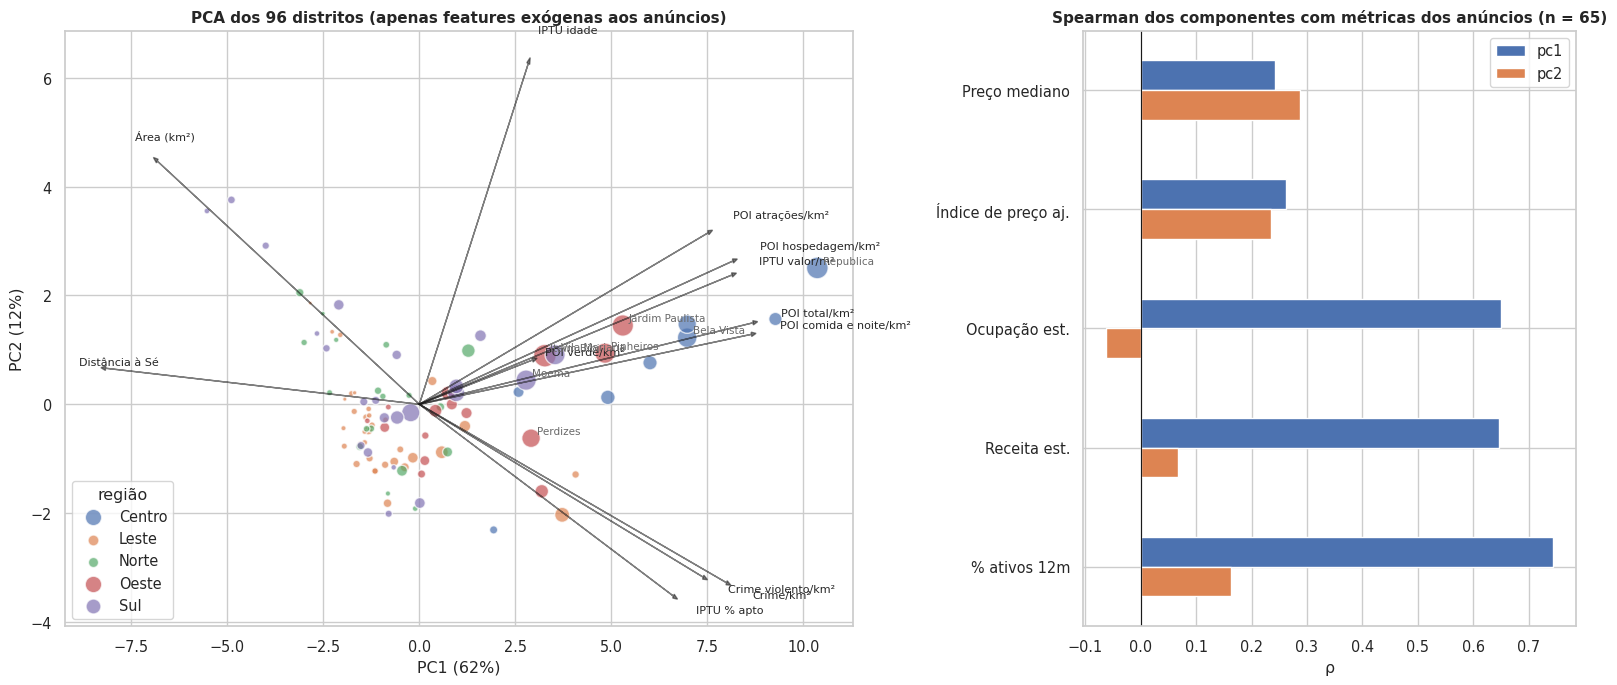

,Preço mediano,Índice de preço aj.,Ocupação est.,Receita est.,% ativos 12m
pc1,0.24,0.26,0.65,0.65,0.74
pc2,0.29,0.24,-0.06,0.07,0.16


In [42]:
from sklearn.decomposition import PCA

PCA_FEATURES = {"iptu_venal_m2_median": "IPTU valor/m²", "iptu_share_apto": "IPTU % apto", "iptu_idade_median": "IPTU idade", "crime_total_km2": "Crime/km²",
                "crime_violento_km2": "Crime violento/km²", "poidens_total": "POI total/km²", "poidens_atracoes": "POI atrações/km²",
                "poidens_hospedagem": "POI hospedagem/km²", "poidens_comida_noite": "POI comida e noite/km²", "poidens_verde_lazer": "POI verde/km²",
                "area_km2": "Área (km²)", "dist_centro_km": "Distância à Sé"}
LOG_COLS = ["crime_total_km2", "crime_violento_km2", "poidens_total", "poidens_atracoes", "poidens_hospedagem", "poidens_comida_noite", "poidens_verde_lazer", "area_km2", "dist_centro_km"]
Xp = dist[list(PCA_FEATURES)].copy()
Xp[LOG_COLS] = np.log1p(Xp[LOG_COLS])
Xp = Xp.fillna(Xp.median())
Xz = (Xp - Xp.mean()) / Xp.std(ddof=0)
pca = PCA(n_components=5, random_state=SEED).fit(Xz)
scores = pca.transform(Xz)
if np.corrcoef(scores[:, 0], Xz["poidens_total"])[0, 1] < 0:                  # orienta PC1: positivo = mais intenso/urbano
    scores[:, 0] *= -1
    pca.components_[0] *= -1
dist["pc1"], dist["pc2"] = scores[:, 0], scores[:, 1]
print("Variância explicada:", " | ".join(f"PC{i + 1} {v:.0%}" for i, v in enumerate(pca.explained_variance_ratio_)), f"| acumulada (PC1–PC3): {pca.explained_variance_ratio_[:3].sum():.0%}")
load = pd.DataFrame(pca.components_[:3].T * np.sqrt(pca.explained_variance_[:3]), index=list(PCA_FEATURES.values()), columns=["PC1", "PC2", "PC3"])
display(load.sort_values("PC1", ascending=False).round(2))

okd = dist[~dist["amostra_baixa"]].copy()
OUTS = {"preco_mediano": "Preço mediano", "indice_preco_aj": "Índice de preço aj.", "ocup_mediana": "Ocupação est.", "receita_mediana": "Receita est.", "pct_ativos": "% ativos 12m"}
rho_pc = pd.DataFrame({pc: {nm: stats.spearmanr(okd[pc], okd[c])[0] for c, nm in OUTS.items()} for pc in ["pc1", "pc2"]})
lp = pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2])
scale = np.abs(scores[:, :2]).max() / np.abs(lp).max() * .85
fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.6, 1]})
for reg, gg in dist.groupby("regiao5"):
    ax[0].scatter(gg["pc1"], gg["pc2"], s=np.sqrt(gg["n_anuncios"]) * 4, color=reg_colors[reg], alpha=.7, edgecolor="w", label=reg)
for j, nm in enumerate(PCA_FEATURES.values()):
    ax[0].arrow(0, 0, lp[j, 0] * scale, lp[j, 1] * scale, color="k", alpha=.55, head_width=.08, length_includes_head=True)
    ax[0].text(lp[j, 0] * scale * 1.07, lp[j, 1] * scale * 1.07, nm, fontsize=8)
for i in dist.nlargest(8, "n_anuncios").index:
    ax[0].annotate(lab(i), (dist.loc[i, "pc1"], dist.loc[i, "pc2"]), fontsize=7.5, xytext=(4, 3), textcoords="offset points", color="dimgray")
ax[0].legend(title="região", loc="lower left")
ax[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", title="PCA dos 96 distritos (apenas features exógenas aos anúncios)")
rho_pc.plot.barh(ax=ax[1], color=[C[0], C[1]]); ax[1].axvline(0, color="k", lw=.8); ax[1].invert_yaxis()
ax[1].set(title=f"Spearman dos componentes com métricas dos anúncios (n = {len(okd)})", xlabel="ρ")
fig.tight_layout()
savefig("21_pca_distritos")
display(rho_pc.round(2).T)

**Leitura**
- **Um único eixo resume a estrutura urbana**: o PC1 explica 62% da variância das 12 features exógenas (82% com três componentes) e reúne POIs de comércio e turismo (0,82 a 0,95), IPTU por m² (0,89), crime/km² (0,87) e, em sentido oposto, distância à Sé (−0,89) e área do distrito (−0,74). É um eixo de **intensidade urbana/centralidade**.
- Esse eixo acompanha a **demanda**, não o preço: ρ(PC1) = 0,74 com % de ativos, 0,65 com ocupação e 0,65 com receita estimada, contra 0,24 com o preço mediano e 0,26 com o índice de preço ajustado.

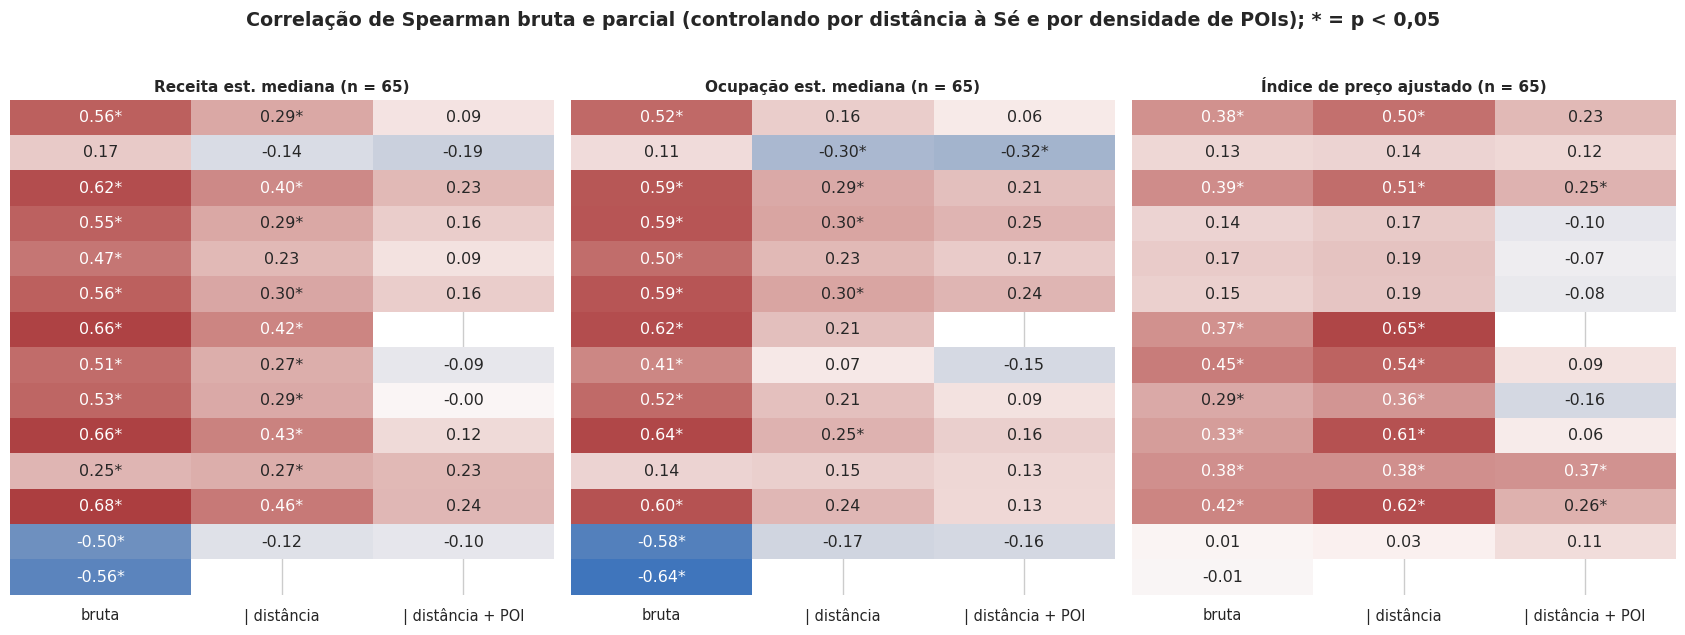

,receita bruta,receita | distância,receita | distância + POI,índice de preço bruta,índice de preço | distância,índice de preço | distância + POI
Crime total /km²,+0.55*,+0.29*,+0.16,+0.14,+0.17,-0.10
IPTU: valor venal/m² (med.),+0.56*,+0.29*,+0.09,+0.38*,+0.50*,+0.23
POI atrações /km²,+0.51*,+0.27*,-0.09,+0.45*,+0.54*,+0.09
Anúncios /km²,+0.68*,+0.46*,+0.24,+0.42*,+0.62*,+0.26*


In [43]:
def partial_spearman(frame, x, y, controls):
    """Spearman parcial: correlação dos resíduos dos postos de x e y após regredir nos postos dos controles."""
    d_ = frame[[x, y] + list(controls)].dropna().rank()
    Z = np.column_stack([np.ones(len(d_))] + [d_[c].values for c in controls])
    rx = d_[x].values - Z @ np.linalg.lstsq(Z, d_[x].values, rcond=None)[0]
    ry = d_[y].values - Z @ np.linalg.lstsq(Z, d_[y].values, rcond=None)[0]
    r_ = float(np.corrcoef(rx, ry)[0, 1])
    dof = len(d_) - 2 - len(controls)
    t_ = r_ * np.sqrt(dof / (1 - r_ ** 2))
    return r_, float(2 * stats.t.sf(abs(t_), dof)), len(d_)


okd = dist[~dist["amostra_baixa"]].copy()
okd["log_poi_total"] = np.log1p(okd["poidens_total"])
FEATS = {**DIST_FEATURES, "dist_centro_km": "Distância à Sé (km)"}
SPECS = {"bruta": [], "| distância": ["dist_centro_km"], "| distância + POI": ["dist_centro_km", "log_poi_total"]}
partial, partial_p = {}, {}
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2), sharey=True)
for ax, (tgt, nm) in zip(axes, [("receita_mediana", "Receita est. mediana"), ("ocup_mediana", "Ocupação est. mediana"), ("indice_preco_aj", "Índice de preço ajustado")]):
    rho_t = pd.DataFrame(index=list(FEATS), columns=list(SPECS), dtype=float)
    ann = rho_t.copy().astype(object)
    pv_t = rho_t.copy()
    for sname, ctrl in SPECS.items():
        for f_ in FEATS:
            if f_ in ctrl or (f_ == "poidens_total" and "log_poi_total" in ctrl):
                ann.loc[f_, sname] = ""
                continue
            r_, p_, _ = partial_spearman(okd, f_, tgt, ctrl)
            rho_t.loc[f_, sname] = r_
            pv_t.loc[f_, sname] = p_
            ann.loc[f_, sname] = f"{r_:.2f}" + ("*" if p_ < .05 else "")
    partial[tgt], partial_p[tgt] = rho_t, pv_t
    sns.heatmap(rho_t, annot=ann, fmt="", cmap="vlag", center=0, vmin=-.7, vmax=.7, ax=ax, cbar=False, yticklabels=list(FEATS.values()) if ax is axes[0] else False)
    ax.set(title=nm + f" (n = {len(okd)})", xlabel="")
fig.suptitle("Correlação de Spearman bruta e parcial (controlando por distância à Sé e por densidade de POIs); * = p < 0,05", y=1.02, fontweight="bold")
fig.tight_layout()
savefig("21_correlacao_parcial")
sel_f = ["crime_total_km2", "iptu_venal_m2_median", "poidens_atracoes", "anuncios_km2"]
tbl_p = pd.DataFrame({f"{tn} {sn}": {FEATS[f_]: f"{partial[t].loc[f_, sn]:+.2f}{'*' if partial_p[t].loc[f_, sn] < .05 else ''}" for f_ in sel_f}
                      for t, tn in [("receita_mediana", "receita"), ("indice_preco_aj", "índice de preço")] for sn in SPECS})
display(tbl_p)

**Leitura**
- A hipótese de **confusão por centralidade se confirma para a demanda**: a correlação de crime/km² com a receita estimada cai de +0,55 para +0,29 ao controlar a distância à Sé e para +0,16 (não significativa) ao controlar também a densidade de POIs. O mesmo vale para IPTU (+0,56 → +0,29 → +0,09) e POIs de atração (+0,51 → +0,27 → −0,09). Só anúncios/km² mantém algum resíduo (+0,24, não significativo).
- Para o **índice de preço ajustado** o crime nunca se associa (+0,14; +0,17; −0,10, todos não significativos). IPTU e POIs de atração *ganham* força ao controlar a distância (+0,38 → +0,50; +0,45 → +0,54): como o preço não cai com a distância (seção 19), tirar a distância revela a relação — que some de novo quando se controla a densidade de POIs (+0,23 e +0,09).
- Ressalvas: n = 65, p-valores sem correção para múltiplos testes e controlar por POI é agressivo (ele mede o mesmo fator latente). É um teste de robustez, não uma prova causal.

### 21.1 Métricas de resultado: o que anda junto

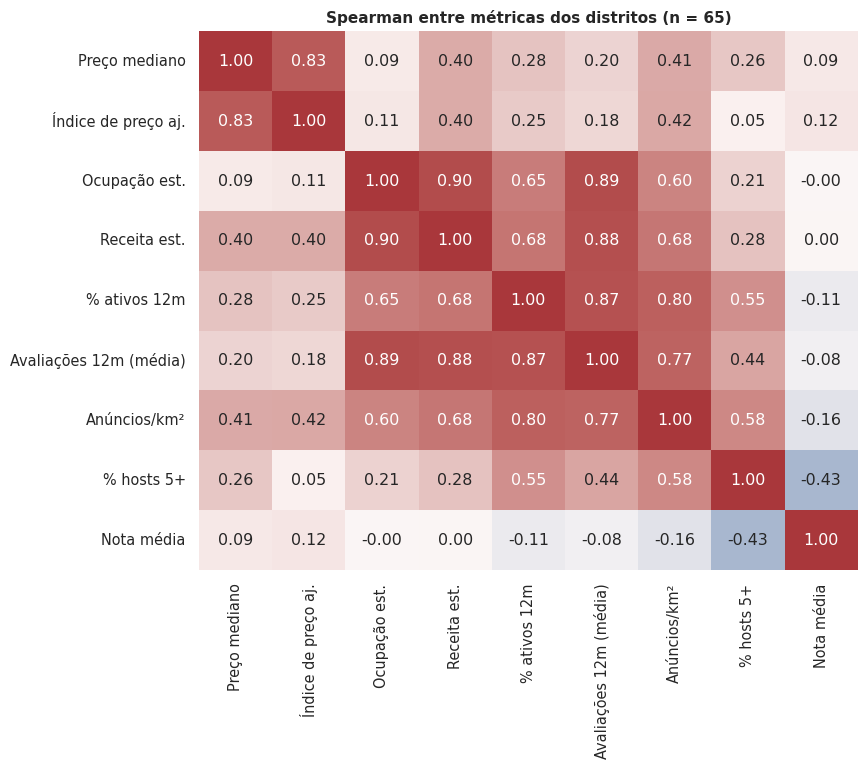

In [44]:
okd["avaliacoes_12m_media"] = df.groupby("distrito")["number_of_reviews_ltm"].mean().reindex(okd.index)
OUT_VARS = {"preco_mediano": "Preço mediano", "indice_preco_aj": "Índice de preço aj.", "ocup_mediana": "Ocupação est.", "receita_mediana": "Receita est.",
            "pct_ativos": "% ativos 12m", "avaliacoes_12m_media": "Avaliações 12m (média)", "anuncios_km2": "Anúncios/km²", "pct_host_5mais": "% hosts 5+", "rating_medio": "Nota média"}
cm_out = okd[list(OUT_VARS)].corr("spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm_out, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar=False, xticklabels=list(OUT_VARS.values()), yticklabels=list(OUT_VARS.values()))
ax.set(title=f"Spearman entre métricas dos distritos (n = {len(okd)})")
savefig("21_metricas_resultado")

**Leitura**
- **Demanda é um bloco só**: ocupação estimada, receita estimada, avaliações em 12 meses e % de ativos andam juntos (ρ de 0,65 a 0,90); a receita estimada tem ρ = 0,90 com a ocupação e 0,88 com as avaliações. O **preço fica fora do bloco** (ρ = 0,09 com a ocupação; 0,40 com a receita).
- **Densidade de oferta acompanha demanda** (anúncios/km² × % ativos = 0,80; × avaliações = 0,77; × receita = 0,68): os distritos mais cheios de anúncios são justamente os de maior demanda. Uma penalização por "saturação" medida pela densidade de anúncios atinge, portanto, os distritos de maior demanda; vale medir a saturação *relativa à demanda* (por exemplo, anúncios por avaliação em 12 meses).
- **Profissionalização e qualidade percebida andam em sentidos opostos**: % de anúncios de hosts com 5+ anúncios × nota média = −0,43.

## 22. Tipologia de distritos (k-means sobre as features exógenas)
Agrupa os 96 distritos pela **estrutura urbana** (PCA → k-means, k escolhido por *silhouette*) *sem usar* métricas dos anúncios; depois verifica se a tipologia explica preço e demanda. Serve também como grupo de apoio para **encolhimento** de distritos de amostra baixa.

k → (silhouette, distritos por grupo): {3: (0.401, [66, 16, 14]), 4: (0.358, [57, 18, 13, 8]), 5: (0.379, [58, 19, 13, 5, 1]), 6: (0.303, [46, 27, 14, 4, 4, 1])}
Escolhido k = 4 (regras: k ≥ 4 e nenhum grupo com menos de 3 distritos)


,distritos,anuncios,% anúncios,maiores distritos,preço mediano,índice preço aj. (%),ocupação est. mediana,receita est. mediana,% ativos
tipologia,,,,,,,,,
T1,8,16385,38.70,"Republica, Jardim Paulista, Pinheiros",312.00,-4.40,78.00,"26,009.50",0.80
T2,18,18479,43.60,"Itaim Bibi, Moema, Vila Mariana",298.00,-9.40,69.00,"20,910.80",0.80
T3,57,6909,16.30,"Santo Amaro, Jabaquara, Tatuape",263.20,-18.50,57.00,"14,308.50",0.70
T4,13,581,1.40,"Cidade Dutra, Tremembe, Parelheiros",456.50,10.60,18.00,"9,910.50",0.60


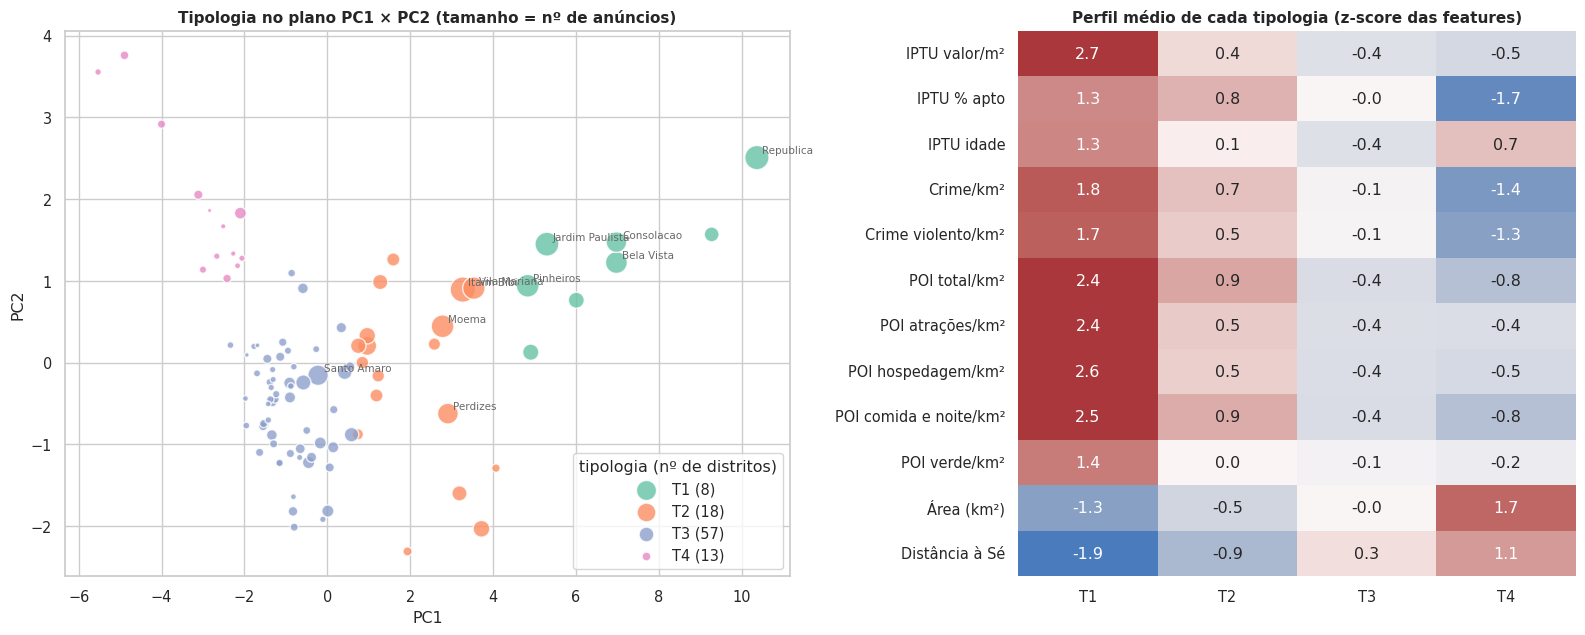

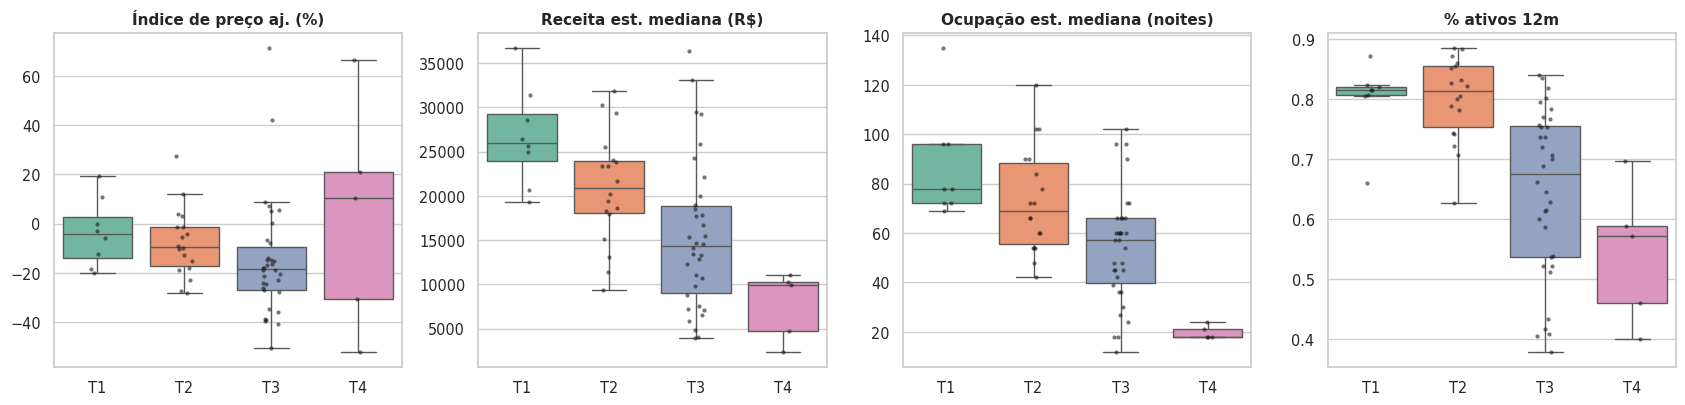

η² ajustado entre 65 distritos — quanto cada agrupamento explica da métrica:


,tipologia,regiao5 (5 regiões)
Preço mediano,0.24,0.15
Índice de preço aj.,0.02,0.26
Ocupação est.,0.37,0.15
Receita est.,0.28,0.09
% ativos 12m,0.35,0.05


In [45]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Zc = scores[:, :4]
K_MIN, MIN_CLUSTER = 4, 3                  # pontos de extensão: nº mínimo de tipos e de distritos por tipo
sil, sizes = {}, {}
for k in range(3, 7):
    lb = KMeans(k, n_init=20, random_state=SEED).fit_predict(Zc)
    sil[k], sizes[k] = silhouette_score(Zc, lb), sorted(np.bincount(lb).tolist(), reverse=True)
valid = {k: v for k, v in sil.items() if k >= K_MIN and min(sizes[k]) >= MIN_CLUSTER}
K = max(valid, key=valid.get)
print("k → (silhouette, distritos por grupo):", {k: (round(sil[k], 3), sizes[k]) for k in sil})
print(f"Escolhido k = {K} (regras: k ≥ {K_MIN} e nenhum grupo com menos de {MIN_CLUSTER} distritos)")
lbl = KMeans(K, n_init=20, random_state=SEED).fit_predict(Zc)
order_c = pd.Series(scores[:, 0]).groupby(lbl).mean().sort_values(ascending=False).index          # T1 = maior PC1 (mais intenso/urbano)
remap = {old: f"T{i + 1}" for i, old in enumerate(order_c)}
dist["tipologia"] = [remap[v] for v in lbl]
TIPS = sorted(dist["tipologia"].unique())
tip_colors = dict(zip(TIPS, sns.color_palette("Set2", len(TIPS))))

okc = dist[~dist["amostra_baixa"]].copy()
prof = Xz.groupby(dist["tipologia"].values).mean().loc[TIPS]
summ = dist.groupby("tipologia").agg(distritos=("n_anuncios", "size"), anuncios=("n_anuncios", "sum"))
summ["% anúncios"] = summ["anuncios"] / summ["anuncios"].sum() * 100
summ["maiores distritos"] = [", ".join(lab(i) for i in dist[dist["tipologia"] == t].nlargest(3, "n_anuncios").index) for t in summ.index]
for c, nm in [("preco_mediano", "preço mediano"), ("indice_preco_aj", "índice preço aj. (%)"), ("ocup_mediana", "ocupação est. mediana"), ("receita_mediana", "receita est. mediana"), ("pct_ativos", "% ativos")]:
    summ[nm] = okc.groupby("tipologia")[c].median()
display(summ.round(1))

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
for t in TIPS:
    gg = dist[dist["tipologia"] == t]
    ax[0].scatter(gg["pc1"], gg["pc2"], s=np.sqrt(gg["n_anuncios"]) * 5, color=tip_colors[t], alpha=.8, edgecolor="w", label=f"{t} ({len(gg)})")
for i in dist.nlargest(10, "n_anuncios").index:
    ax[0].annotate(lab(i), (dist.loc[i, "pc1"], dist.loc[i, "pc2"]), fontsize=7.5, xytext=(4, 3), textcoords="offset points", color="dimgray")
ax[0].legend(title="tipologia (nº de distritos)"); ax[0].set(xlabel="PC1", ylabel="PC2", title="Tipologia no plano PC1 × PC2 (tamanho = nº de anúncios)")
sns.heatmap(prof.T, annot=True, fmt=".1f", cmap="vlag", center=0, vmin=-2.2, vmax=2.2, ax=ax[1], cbar=False, yticklabels=list(PCA_FEATURES.values()))
ax[1].set(title="Perfil médio de cada tipologia (z-score das features)", xlabel="")
fig.tight_layout()
savefig("22_tipologia_distritos")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (c, nm) in zip(axes, [("indice_preco_aj", "Índice de preço aj. (%)"), ("receita_mediana", "Receita est. mediana (R$)"), ("ocup_mediana", "Ocupação est. mediana (noites)"), ("pct_ativos", "% ativos 12m")]):
    sns.boxplot(data=okc, x="tipologia", y=c, order=TIPS, palette=tip_colors, showfliers=False, ax=ax)
    sns.stripplot(data=okc, x="tipologia", y=c, order=TIPS, color="k", size=3, alpha=.6, ax=ax)
    ax.set(title=nm, xlabel="", ylabel="")
fig.tight_layout()
savefig("22_tipologia_resultados")

eta_rows = {}
for c, nm in OUTS.items():
    s_ = okc.dropna(subset=[c])
    eta_rows[nm] = {"tipologia": eta2(s_, "tipologia", y=c)["eta2_ajustado"], "regiao5 (5 regiões)": eta2(s_, "regiao5", y=c)["eta2_ajustado"]}
print(f"η² ajustado entre {len(okc)} distritos — quanto cada agrupamento explica da métrica:")
display(pd.DataFrame(eta_rows).T.round(2))

**Leitura**
- Com k = 4 (silhouette 0,36; k = 3 teria 0,40, mas só separa centro × resto, e k = 5 gera um grupo de 1 distrito), a tipologia fica: **T1 núcleo central denso** (8 distritos, 39% dos anúncios: República, Consolação, Bela Vista, Jardim Paulista, Pinheiros), **T2 centro expandido** (18 distritos, 44%: Itaim Bibi, Moema, Vila Mariana, Perdizes), **T3 urbano intermediário/periférico consolidado** (57 distritos, 16%: Santo Amaro, Jabaquara, Tatuapé) e **T4 franja de baixa densidade** (13 distritos, 1,4%: Cidade Dutra, Tremembé, Parelheiros).
- A demanda cai **degrau a degrau** de T1 a T4: ocupação estimada 78 → 69 → 57 → 18 noites; receita R\$ 26 mil → 21 mil → 14 mil → 10 mil; ativos 80% → 80% → 70% → 60%. O preço não segue essa ordem: T4 tem a maior mediana (R\$ 457; inclui Parelheiros, de casas grandes) com pouquíssimos anúncios.
- A tipologia (que **não usa** nenhuma métrica dos anúncios) explica melhor a demanda do que as 5 regiões geográficas — ocupação 37% × 15%, receita 28% × 9%, % de ativos 35% × 5% (η² ajustado) —, enquanto as regiões explicam melhor o **prêmio de preço** (26% × 2%). Ou seja: *a demanda segue a estrutura urbana; o preço segue a geografia (eixo Oeste/Sudoeste)*.
- Uso prático: a coluna `tipologia` de `resumo_distritos.csv` é um grupo natural para **encolher** as medianas dos distritos de amostra baixa.

## 23. Coortes de entrada: como o mercado mudou
Coorte = ano da 1ª avaliação (proxy de entrada). Cuidado: coortes antigas só incluem quem **sobreviveu**, e os preços são nominais.

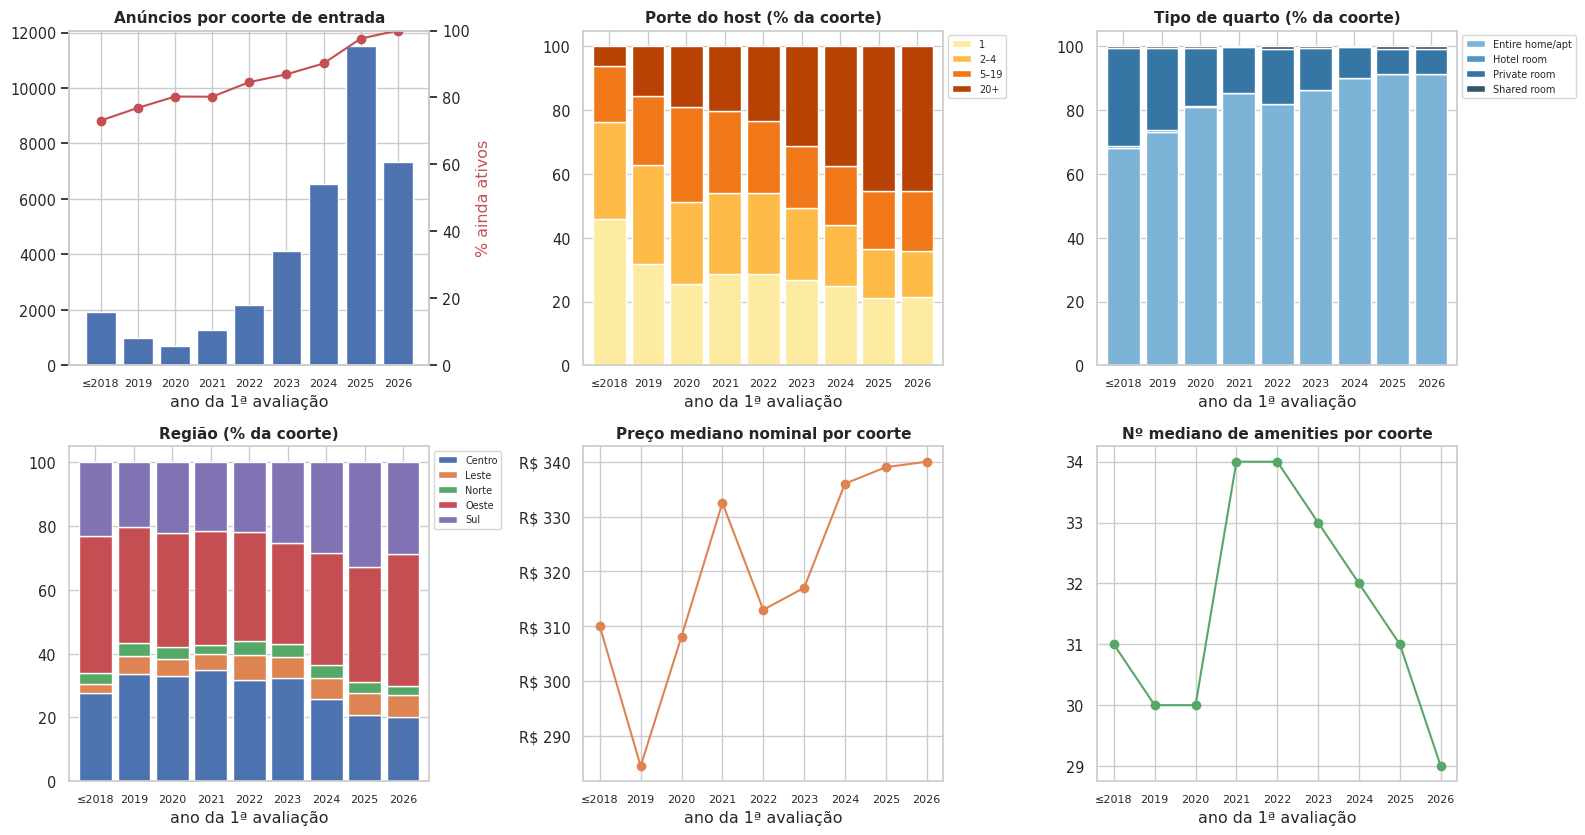

coorte,≤2018,2019,2020,2021,2022,2023,2024,2025,2026
anuncios,"1,937.00",995.00,710.00,"1,259.00","2,186.00","4,128.00","6,535.00","11,498.00","7,335.00"
ativos_%,73.10,76.90,80.30,80.20,84.60,86.90,90.20,97.60,100.00
host_5mais_%,23.60,37.20,48.70,45.90,46.00,50.70,56.10,63.40,64.20
entire_home_%,68.30,73.20,81.10,85.30,81.90,86.30,90.00,91.50,91.50
centro_%,27.70,33.60,33.10,35.00,31.80,32.30,25.90,20.80,20.30
oeste_%,43.30,36.10,35.60,35.70,34.30,31.70,35.00,36.00,41.40
sul_%,22.90,20.40,22.10,21.50,21.90,25.20,28.50,32.80,28.60
preco_mediano,310.00,284.50,308.10,332.50,313.00,317.00,336.00,339.00,340.00
amenities_med,31.00,30.00,30.00,34.00,34.00,33.00,32.00,31.00,29.00


In [46]:
rvc = df[df["has_reviews"]].copy()
yr = rvc["first_review"].dt.year.astype(int)
rvc["coorte"] = np.where(yr <= 2018, "≤2018", yr.astype(str))
COH = ["≤2018"] + sorted(set(rvc["coorte"]) - {"≤2018"})
rvc = rvc[rvc["coorte"].isin(COH)]
cnt_c = rvc.groupby("coorte").size().reindex(COH)
alive = rvc.groupby("coorte")["active_ltm"].mean().reindex(COH)
mix = lambda col: pd.crosstab(rvc["coorte"], rvc[col], normalize="index").reindex(COH) * 100
price_c = rvc[rvc["price_ok"]].groupby("coorte")["price"].median().reindex(COH)
amen_c = rvc.groupby("coorte")["n_amenities"].median().reindex(COH)

fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
ax[0, 0].bar(COH, cnt_c.values, color=C[0]); ax[0, 0].set(title="Anúncios por coorte de entrada")
a2 = ax[0, 0].twinx(); a2.plot(COH, alive.values * 100, "o-", color=C[3]); a2.set_ylim(0, 100); a2.grid(False); a2.set_ylabel("% ainda ativos", color=C[3])
mix("host_size")[["1", "2–4", "5–19", "20+"]].plot.bar(stacked=True, ax=ax[0, 1], color=sns.color_palette("YlOrBr", 4), width=.85, rot=0); ax[0, 1].set(title="Porte do host (% da coorte)")
mix("room_type").plot.bar(stacked=True, ax=ax[0, 2], color=sns.color_palette("Blues_d", 4), width=.85, rot=0); ax[0, 2].set(title="Tipo de quarto (% da coorte)")
mix("regiao5").plot.bar(stacked=True, ax=ax[1, 0], color=[reg_colors[r] for r in sorted(reg_colors)], width=.85, rot=0); ax[1, 0].set(title="Região (% da coorte)")
ax[1, 1].plot(COH, price_c.values, "o-", color=C[1]); ax[1, 1].yaxis.set_major_formatter(BRL); ax[1, 1].set(title="Preço mediano nominal por coorte")
ax[1, 2].plot(COH, amen_c.values, "o-", color=C[2]); ax[1, 2].set(title="Nº mediano de amenities por coorte")
for a in ax.ravel():
    a.set_xlabel("ano da 1ª avaliação")
    a.tick_params(axis="x", labelsize=8)
    if a.get_legend():
        a.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
savefig("23_coortes_entrada")
tbl_c = pd.DataFrame({"anuncios": cnt_c, "ativos_%": alive * 100, "host_5mais_%": rvc.groupby("coorte")["calculated_host_listings_count"].apply(lambda s: (s >= 5).mean() * 100).reindex(COH),
                      "entire_home_%": mix("room_type")["Entire home/apt"], "centro_%": mix("regiao5")["Centro"], "oeste_%": mix("regiao5")["Oeste"], "sul_%": mix("regiao5")["Sul"],
                      "preco_mediano": price_c, "amenities_med": amen_c})
display(tbl_c.round(1).T)

**Leitura**
- **A entrada de anúncios acelerou e se profissionalizou**: 11,5 mil anúncios tiveram a 1ª avaliação em 2025 e 7,3 mil só no 1º semestre de 2026, contra 1,9 mil na coorte ≤ 2018. A fatia de anúncios de hosts com 5+ anúncios sobe de 24% (≤ 2018) para 46–51% (2020–2023), 56% (2024) e 63–64% (2025–2026); a de casas/apartamentos inteiros, de 68% para 91,5%.
- A nova oferta **se desloca do Centro**: o Centro responde por 32–35% das coortes 2019–2023, mas por 21% em 2025 e 20% em 2026; o Sul sobe de ≈ 21% para 29–33%.
- O preço mediano nominal quase não mudou (R\$ 310 → R\$ 340, ≈ +10% em 8 anos, bem abaixo da inflação do período) e o nº mediano de amenities **caiu** nas coortes recentes (34 → 29): os entrantes são mais "enxutos". Cuidado: coortes antigas só incluem sobreviventes e a 1ª avaliação atrasa em relação à entrada.

## 24. O calendário é um bom proxy de demanda?
Teste do que sugeri na seção 7: `booked_30 = 1 − availability_30/30` (fração dos próximos 30 dias **não** aberta) contra a demanda observada (avaliações em 12 meses). Lembrete: dia fechado pode ser reserva **ou bloqueio do host**.

Entre ativos (n = 33,647): Spearman(booked_30, avaliações 12m) = +0.11 | (booked_90, avaliações 12m) = +0.14
Calendário 100% fechado nos próximos 30 dias (availability_30 = 0): ativos 7.4% | inativos 12.2%
Calendário 100% aberto (availability_30 = 30): ativos 15.4% | inativos 34.4%
Entre distritos (n = 65): Spearman(booked_30 mediano, ocupação est. mediana) = +0.37 | (booked_30, % ativos) = +0.33


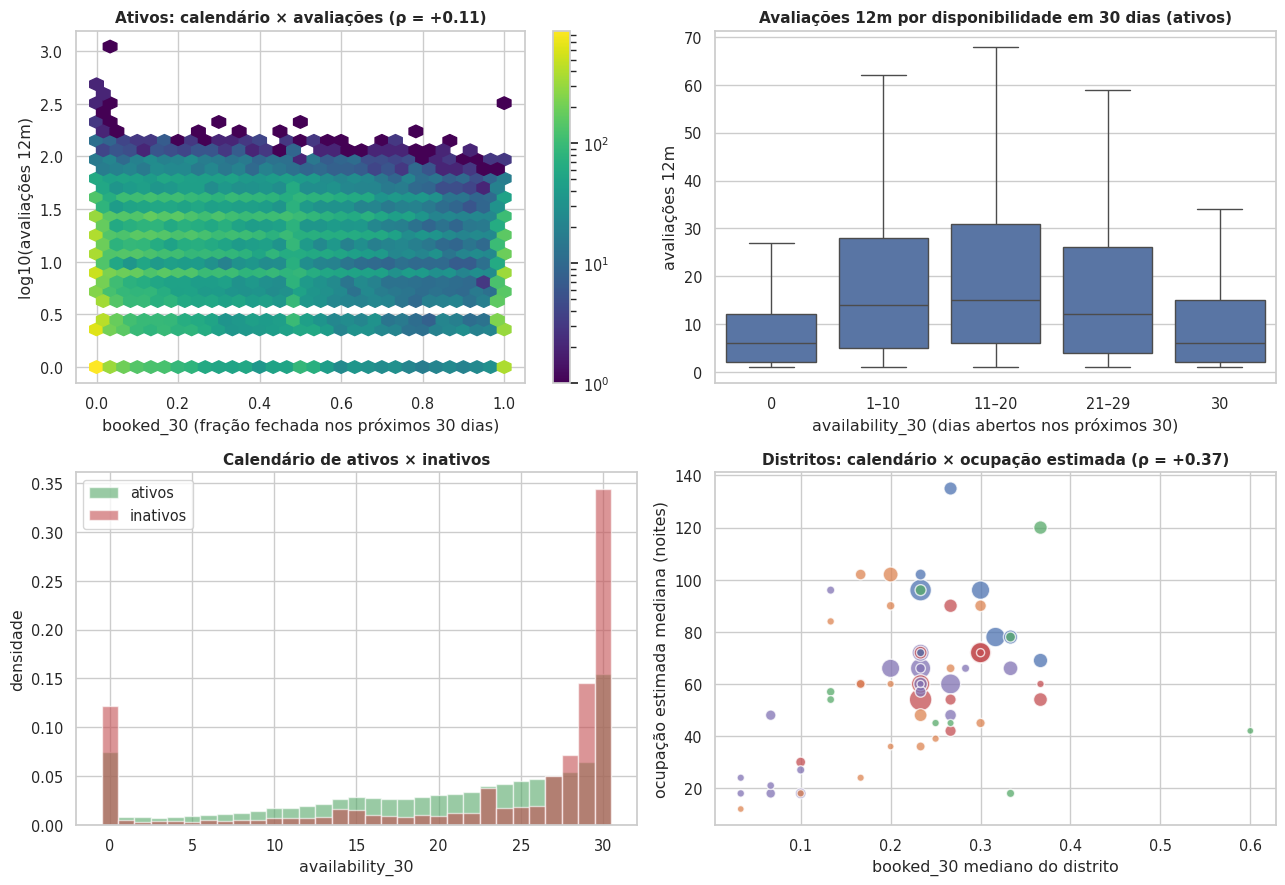

resumo_distritos.csv atualizado: 43 colunas


In [47]:
act = df[df["active_ltm"]].copy()
act["booked_30"] = 1 - act["availability_30"] / 30
act["booked_90"] = 1 - act["availability_90"] / 90
inact = df[~df["active_ltm"]]
r30 = stats.spearmanr(act["booked_30"], act["number_of_reviews_ltm"])[0]
r90 = stats.spearmanr(act["booked_90"], act["number_of_reviews_ltm"])[0]
print(f"Entre ativos (n = {len(act):,}): Spearman(booked_30, avaliações 12m) = {r30:+.2f} | (booked_90, avaliações 12m) = {r90:+.2f}")
print(f"Calendário 100% fechado nos próximos 30 dias (availability_30 = 0): ativos {pct((act['availability_30'] == 0).mean())} | inativos {pct((inact['availability_30'] == 0).mean())}")
print(f"Calendário 100% aberto (availability_30 = 30): ativos {pct((act['availability_30'] == 30).mean())} | inativos {pct((inact['availability_30'] == 30).mean())}")

act["av30_b"] = pd.cut(act["availability_30"], [-1, 0, 10, 20, 29, 30], labels=["0", "1–10", "11–20", "21–29", "30"])
bk = act.groupby("distrito")["booked_30"].median().rename("booked30_med")
dist["booked30_med"] = bk
okd = dist[~dist["amostra_baixa"]].copy()
r_d = stats.spearmanr(okd["booked30_med"], okd["ocup_mediana"], nan_policy="omit")[0]
r_dr = stats.spearmanr(okd["booked30_med"], okd["pct_ativos"], nan_policy="omit")[0]
print(f"Entre distritos (n = {len(okd)}): Spearman(booked_30 mediano, ocupação est. mediana) = {r_d:+.2f} | (booked_30, % ativos) = {r_dr:+.2f}")

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
hb = ax[0, 0].hexbin(act["booked_30"], np.log10(act["number_of_reviews_ltm"]), gridsize=30, bins="log", cmap="viridis", mincnt=1)
ax[0, 0].set(xlabel="booked_30 (fração fechada nos próximos 30 dias)", ylabel="log10(avaliações 12m)", title=f"Ativos: calendário × avaliações (ρ = {r30:+.2f})"); fig.colorbar(hb, ax=ax[0, 0])
sns.boxplot(data=act, x="av30_b", y="number_of_reviews_ltm", showfliers=False, color=C[0], ax=ax[0, 1])
ax[0, 1].set(xlabel="availability_30 (dias abertos nos próximos 30)", ylabel="avaliações 12m", title="Avaliações 12m por disponibilidade em 30 dias (ativos)")
for nm, fr, cl in [("ativos", act, C[2]), ("inativos", inact, C[3])]:
    ax[1, 0].hist(fr["availability_30"], bins=np.arange(-.5, 31.5, 1), density=True, alpha=.6, color=cl, label=nm)
ax[1, 0].legend(); ax[1, 0].set(xlabel="availability_30", ylabel="densidade", title="Calendário de ativos × inativos")
ax[1, 1].scatter(okd["booked30_med"], okd["ocup_mediana"], s=np.sqrt(okd["n_anuncios"]) * 4, c=okd["regiao5"].map(reg_colors), alpha=.75, edgecolor="w")
ax[1, 1].set(xlabel="booked_30 mediano do distrito", ylabel="ocupação estimada mediana (noites)", title=f"Distritos: calendário × ocupação estimada (ρ = {r_d:+.2f})")
fig.tight_layout()
savefig("24_calendario_proxy_demanda")

save_table(dist, "resumo_distritos")          # sobrescreve a tabela da seção 11 com as colunas novas (índice ajustado, PCA, tipologia, calendário)
print("resumo_distritos.csv atualizado:", dist.shape[1], "colunas")

**Leitura**
- **O calendário é um proxy fraco de demanda no nível do anúncio**: entre os 33,6 mil anúncios ativos, a fração fechada nos próximos 30 dias tem ρ = +0,11 com as avaliações em 12 meses (+0,14 com 90 dias). Dia fechado não é só reserva: 12% dos anúncios *inativos* têm o calendário todo fechado (contra 7% dos ativos) — bloqueio do host — e 34% dos inativos o têm todo aberto (contra 15% dos ativos).
- **No nível do distrito há concordância moderada**: ρ = +0,37 entre o `booked_30` mediano e a ocupação estimada (+0,33 com o % de ativos). Serve como *checagem cruzada* de rankings distritais, não como substituto da demanda.

## 25. Resumo e insights consolidados

In [48]:
lines = [
    f"Base: {len(df):,} anúncios · {df['host_id'].nunique():,} hosts · {df['distrito'].nunique()} distritos · coleta de {df['last_scraped'].min():%d/%m} a {df['last_scraped'].max():%d/%m/%Y}",
    f"Preço: mediana {brl(df['price'].median())}/noite (valores em R$) · price_ok = {len(dfp):,} ({pct(len(dfp) / len(df))}) · cotações de 1 noite = {pct((df['quote_nights'] == 1).mean())}",
    f"Oferta: {pct((df['room_type'] == 'Entire home/apt').mean())} casa/apto inteiro · {pct((df['calculated_host_listings_count'] >= 5).mean())} dos anúncios são de hosts com 5+ anúncios",
    f"Atividade: {pct(df['active_ltm'].mean())} com ≥ 1 avaliação em 12m · ocupação estimada mediana (ativos) {dfa['estimated_occupancy_l365d'].median():.0f} noites · receita estimada mediana {brl(dfa['estimated_revenue_l365d'].median())}",
    f"Espacial: top 10 distritos = {pct(df['distrito'].value_counts().head(10).sum() / len(df))} dos anúncios · {int(dist['amostra_baixa'].sum())} distritos com amostra baixa",
    f"Crime imputado: {int((dist['crime_source'] == 'nearest-imputed').sum())} distritos ({pct((df['crime_source'] == 'nearest-imputed').mean())} dos anúncios)",
    f"Variância do log-preço (η² ajustado): distrito {et.loc['distrito (região)', 'eta2_ajustado']:.0%} · room_type {et.loc['room_type', 'eta2_ajustado']:.0%} · distrito × room_type × capacidade {et.loc['distrito × room_type × capacidade', 'eta2_ajustado']:.0%}",
    f"R² fora da amostra (célula região + perfil, CV por host): {cell_res.iloc[-1]:.2f}",
]
if RUN_BASELINE:
    lines.append(f"Baseline HistGradientBoosting (CV por host): R² {cumul['R² (log-preço)'].iloc[-1]:.2f} · erro percentual mediano {cumul['erro % mediano'].iloc[-1]:.0f}%")
sh_occ = la["estimated_revenue_l365d"].cov(la["estimated_occupancy_l365d"]) / la["estimated_revenue_l365d"].var()
okd2 = dist[~dist["amostra_baixa"]]
lines += [
    f"Parte II — preço ajustado por perfil: Spearman com a mediana bruta = {stats.spearmanr(okd2['preco_mediano'], okd2['indice_preco_aj'])[0]:.2f}; maiores índices: " + ", ".join(f"{lab(i)} {v:+.0f}%" for i, v in okd2["indice_preco_aj"].nlargest(3).items()),
    f"Receita estimada: {sh_occ:.0%} da variância do log-receita (anúncios ativos) vem da ocupação estimada (avaliações) e {1 - sh_occ:.0%} do preço",
    f"Gradiente: ocupação estimada mediana {grad['ocup_mediana'].iloc[0]:.0f} noites (0–2 km) → {grad['ocup_mediana'].iloc[-1]:.0f} (15+ km); preço mediano {brl(grad['preco_mediano'].iloc[0])} (0–2 km) → {brl(grad['preco_mediano'].max())} ({grad['preco_mediano'].idxmax()} km)",
    f"Moran global (65 distritos): índice de preço ajustado {moran_tbl.loc['Índice de preço ajustado', 'Moran I']:.2f} | receita {moran_tbl.loc['Receita est. mediana', 'Moran I']:.2f} | IPTU/m² (96 distritos) {moran_tbl.loc['IPTU valor/m² — 96 distritos', 'Moran I']:.2f}",
    f"PCA dos distritos: PC1 = {pca.explained_variance_ratio_[0]:.0%} da variância; ρ(PC1, % ativos) = {rho_pc.loc['% ativos 12m', 'pc1']:+.2f} | ρ(PC1, preço mediano) = {rho_pc.loc['Preço mediano', 'pc1']:+.2f}",
    f"Crime/km² × receita estimada: ρ bruta {partial['receita_mediana'].loc['crime_total_km2', 'bruta']:+.2f} → {partial['receita_mediana'].loc['crime_total_km2', '| distância + POI']:+.2f} controlando distância e POIs",
    f"Tipologia (k = {K}): η² ajustado da ocupação est. = {eta_rows['Ocupação est.']['tipologia']:.2f} (tipologia) × {eta_rows['Ocupação est.']['regiao5 (5 regiões)']:.2f} (5 regiões); do índice de preço = {eta_rows['Índice de preço aj.']['tipologia']:.2f} × {eta_rows['Índice de preço aj.']['regiao5 (5 regiões)']:.2f}",
    f"Coortes: hosts com 5+ anúncios = {tbl_c['host_5mais_%'].iloc[0]:.0f}% (≤ 2018) → {tbl_c['host_5mais_%'].iloc[-1]:.0f}% ({COH[-1]}) das entradas",
    f"Calendário como proxy: ρ(booked_30, avaliações 12m) = {r30:+.2f} (anúncios) | ρ(booked_30, ocupação est.) = {r_d:+.2f} (distritos)",
]
print("\n".join(" • " + l for l in lines))

 • Base: 42,354 anúncios · 15,840 hosts · 96 distritos · coleta de 14/06 a 16/06/2026
 • Preço: mediana R$ 331/noite (valores em R$) · price_ok = 38,033 (89.8%) · cotações de 1 noite = 54.9%
 • Oferta: 85.9% casa/apto inteiro · 54.1% dos anúncios são de hosts com 5+ anúncios
 • Atividade: 79.4% com ≥ 1 avaliação em 12m · ocupação estimada mediana (ativos) 72 noites · receita estimada mediana R$ 22.968
 • Espacial: top 10 distritos = 66.7% dos anúncios · 31 distritos com amostra baixa
 • Crime imputado: 25 distritos (33.2% dos anúncios)
 • Variância do log-preço (η² ajustado): distrito 14% · room_type 16% · distrito × room_type × capacidade 44%
 • R² fora da amostra (célula região + perfil, CV por host): 0.34
 • Baseline HistGradientBoosting (CV por host): R² 0.59 · erro percentual mediano 16%
 • Parte II — preço ajustado por perfil: Spearman com a mediana bruta = 0.83; maiores índices: Socorro +71%, Cidade Dutra +66%, Morumbi +42%
 • Receita estimada: 89% da variância do log-receita (a


### Armadilhas (para não cair)
1. **Receita e ocupação estimadas ≠ observadas.** São `preço cotado × 2 × avaliações_12m × max(3, minimum_nights)` (teto de 255 noites): 89% da variância da receita vem da ocupação. Demanda e receita derivadas daí não são independentes.
2. **Preço é cotação pontual** (1 noite, próximas datas, sobretudo dias úteis): filtre por duração (`price_ok`) e não compare com preços de estadia longa.
3. **A mediana bruta de preço mistura composição.** Para comparar distritos, use o índice ajustado por perfil (seção 17); os extremos do ranking bruto são distritos pequenos (Grajaú, Parelheiros, Socorro).
4. **Features distritais têm n = 96, não 42 mil.** Correlacione/modele no nível do distrito (ou valide agrupando por distrito) e use encolhimento (*empirical Bayes*) para os 31 distritos de amostra baixa; a `tipologia` serve de grupo de apoio.
5. **Crime imputado em 25 distritos (33% dos anúncios) e POI do OSM com viés central.** Faça sensibilidade com e sem esses distritos.
6. **Centralidade confunde tudo.** POI, crime/km², IPTU e anúncios/km² formam um eixo único (PC1 = 62%); ao controlar distância e POIs, a correlação de crime com receita cai de +0,55 para +0,16 (não significativa).
7. **"Saturação" medida por densidade de anúncios é positiva com a demanda** (ρ de 0,6 a 0,8): penalizá-la pune os distritos de maior demanda. Prefira saturação relativa à demanda.
8. **Calendário (`availability_*`) é proxy fraco de demanda** (ρ = 0,11 por anúncio): dia fechado pode ser bloqueio do host.
9. **Validação aleatória vaza** (mesmo host/prédio em treino e teste): use `GroupKFold` por host (ou por distrito).
10. **Mercado jovem, concentrado e em profissionalização**: mais da metade dos anúncios avaliados começou em 2025–26; 1% dos hosts controla 29% da oferta; hosts com 5+ anúncios passaram de 24% para 64% das entradas.

### Próximos passos (pontos de extensão)
- **Retorno esperado**: dividir a receita estimada (ou, melhor, uma versão calibrada) pelo valor venal/m² do IPTU de cada distrito para ter um proxy receita/custo por região × perfil.
- **Mapas coropléticos e pesos Queen**: `geopandas` + shapefile de distritos, juntando por `distrito` (normalize acentos com `norm_txt`); troque `knn_weights` por contiguidade (`libpysal`) para refazer Moran/LISA.
- **Encolhimento** das medianas distritais usando a `tipologia` (ou regiões vizinhas) como grupo de apoio antes de ranquear.
- **Saturação relativa à demanda** (anúncios por avaliação em 12 meses) no lugar da densidade bruta de anúncios.
- **Novas células região × perfil**: adicione cascatas em `cascades` (ex.: `property_type`, `bed_b`) e reavalie com `cell_cv_r2`.
- **Novos blocos no baseline**: edite `BLOCKS`; para importância por permutação/SHAP use `base` e `cv_eval`.
- **Texto e imagem** (`name`, `description`, `picture_url`) ainda não foram explorados.
